# Embryonic Mouse Brain Atlas Clean Splat Notebook

This notebook starts from a minimal, cleaner scaffold for the embryonic mouse brain atlas.
It currently focuses only on loading tissue support and spatial units in the same style as the modular amplitude notebooks.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import random
import torch
import torch.nn as nn
from scipy.ndimage import distance_transform_edt

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import AmplitudeSplatField, DataConfig, SplatConfig, TrainingConfig, build_cell_only_targets, capture_initial_splat_state, composition_cosine_loss, compute_splat_weights, create_amplitude_splat_optimizer, evaluate_cell_readout, evaluate_count_model, farthest_point_sample_indices, log_total_count_loss, mae_count_loss, make_split_indices, predict_cell_log_rates, sample_numpy_grid, sample_tissue_support, summarize_activity_slices, summarize_error_slices, usage_statistics, GeneProfileAutoencoder, evaluate_profile_autoencoder, train_profile_autoencoder
from spatsplat.baselines import CountMLP, FourierFeatureMLP, KNNCountRegressor, MeanProfileBaseline
from paper.data_loaders.embryonic_mouse_brain_atlas import load_embryonic_mouse_brain_atlas_dataset


In [2]:
control_name = "Control06"

data_cfg = DataConfig(bin_size=64, mask_grid_size=128, qv_threshold=20, cell_mask_min_radius=2.5)
splat_cfg = SplatConfig(num_splats=64, latent_dim=32, hidden_dim=256, init_log_scale=-3.5, kernel_sharpness=0.2)
init_log_amplitude = 8.0
train_cfg = TrainingConfig(
    baseline_epochs=500,
    splat_epochs=500,
    baseline_batch_size=256,
    cell_batch_size=256,
    off_tissue_batch_size=256,
    cell_loss_weight=1.0,
    off_tissue_weight=0.0,
    center_support_weight=0.1,
    splat_means_lr=2e-2,
    splat_log_scales_lr=1e-3,
    splat_rotation_lr=1e-3,
    splat_opacity_lr=1e-3,
    splat_latents_lr=1e-3,
    splat_log_theta_lr=1e-3,
    splat_decoder_lr=1e-3,
    splat_amplitude_lr=1e-3,
)

notebook_seed = 1023
split_seed = notebook_seed
ae_seed = notebook_seed + 1
seed_init_seed = notebook_seed + 2
baseline_mean_seed = notebook_seed + 3
baseline_mlp_mae_seed = notebook_seed + 4
baseline_mlp_bio_seed = notebook_seed + 5
baseline_fourier_mae_seed = notebook_seed + 6
baseline_fourier_bio_seed = notebook_seed + 7
baseline_budget_knn_seed = notebook_seed + 8
random_model_seed = notebook_seed + 9
random_train_seed = notebook_seed + 10
ae_train_seed = notebook_seed + 11
ae_frozen_train_seed = notebook_seed + 12
ae_unfrozen_train_seed = notebook_seed + 13
layout_seed = notebook_seed + 14
overlap_seed = notebook_seed + 15
comparison_gene_of_interest = "Eomes"


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, 'cudnn'):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(notebook_seed)
display_sig_digits = 4


def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if np.isnan(value) or np.isinf(value):
            return value
        return float(f'{value:.{display_sig_digits}g}')
    return value


def format_for_display(obj):
    if isinstance(obj, dict):
        return {k: format_for_display(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [format_for_display(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(format_for_display(v) for v in obj)
    return format_scalar(obj)

FIGURE_EXPORT_DIR = PROJECT_ROOT / 'figures' / 'embryonic_mouse_brain_atlas_clean'
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
figure_export_dir = FIGURE_EXPORT_DIR
def _slugify_figure_name(name: str) -> str:
    keep = []
    for ch in name.lower():
        if ch.isalnum():
            keep.append(ch)
        elif ch in {' ', '-', '_', '|'}:
            keep.append('_')
    slug = ''.join(keep).strip('_')
    while '__' in slug:
        slug = slug.replace('__', '_')
    return slug or 'untitled_figure'

def export_figure_axes(fig, fallback_prefix: str = "figure", dpi: int = 300, canvas_px: int = 2200):
    from PIL import Image

    titled_axes = []
    for ax in fig.axes:
        title = ax.get_title().strip() if hasattr(ax, "get_title") else ""
        if title:
            titled_axes.append((ax, title))
    if not titled_axes:
        return []

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width, height = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8).reshape(height, width, 4)
    all_bboxes = {ax: ax.get_tightbbox(renderer) for ax in fig.axes}
    saved_paths = []

    def _merge_with_adjacent_colorbars(main_ax, main_bbox):
        merged = main_bbox
        main_w = max(float(main_bbox.width), 1.0)
        main_h = max(float(main_bbox.height), 1.0)
        for other_ax in fig.axes:
            if other_ax is main_ax:
                continue
            other_bbox = all_bboxes.get(other_ax)
            if other_bbox is None:
                continue
            other_title = other_ax.get_title().strip() if hasattr(other_ax, "get_title") else ""
            if other_title:
                continue

            horiz_gap = min(abs(other_bbox.x1 - merged.x0), abs(other_bbox.x0 - merged.x1))
            vert_gap = min(abs(other_bbox.y1 - merged.y0), abs(other_bbox.y0 - merged.y1))
            y_overlap = max(0.0, min(merged.y1, other_bbox.y1) - max(merged.y0, other_bbox.y0))
            x_overlap = max(0.0, min(merged.x1, other_bbox.x1) - max(merged.x0, other_bbox.x0))

            is_vertical_bar = (
                other_bbox.width < 0.22 * main_w
                and y_overlap > 0.55 * min(main_h, float(other_bbox.height))
                and horiz_gap < 0.08 * main_w
                and other_bbox.x0 >= merged.x1
            )
            is_horizontal_bar = (
                other_bbox.height < 0.22 * main_h
                and x_overlap > 0.55 * min(main_w, float(other_bbox.width))
                and vert_gap < 0.08 * main_h
                and other_bbox.y1 <= merged.y0
            )
            if is_vertical_bar or is_horizontal_bar:
                merged = merged.union([merged, other_bbox])
        return merged

    for idx, (ax, title) in enumerate(titled_axes, start=1):
        base = _slugify_figure_name(f"{fallback_prefix}_{title}")
        if not base:
            base = _slugify_figure_name(f"{fallback_prefix}_{idx}")
        out_path = FIGURE_EXPORT_DIR / f"{base}.png"

        bbox = _merge_with_adjacent_colorbars(ax, all_bboxes[ax]).expanded(1.03, 1.08)
        x0 = max(0, int(np.floor(bbox.x0)))
        y0 = max(0, int(np.floor(bbox.y0)))
        x1 = min(width, int(np.ceil(bbox.x1)))
        y1 = min(height, int(np.ceil(bbox.y1)))
        if x1 <= x0 or y1 <= y0:
            continue

        crop = buf[height - y1:height - y0, x0:x1].copy()
        crop_img = Image.fromarray(crop)
        side = max(crop_img.width, crop_img.height)
        square = Image.new("RGBA", (side, side), (255, 255, 255, 255))
        offset = ((side - crop_img.width) // 2, (side - crop_img.height) // 2)
        square.paste(crop_img, offset)
        if side != canvas_px:
            square = square.resize((canvas_px, canvas_px), Image.Resampling.LANCZOS)
        square.save(out_path)
        saved_paths.append(str(out_path))
    return saved_paths

loaded = load_embryonic_mouse_brain_atlas_dataset(control_name=control_name)
dataset = build_cell_only_targets(loaded, data_cfg)

device = loaded.device
adata = loaded.adata
gene_list = loaded.gene_list
gene_to_id = loaded.gene_to_id
num_genes = loaded.num_genes

cell_features = dataset.cell_features
cell_spans = dataset.cell_spans
cell_targets = dataset.cell_targets
off_tissue_points = dataset.off_tissue_points
tissue_mask_tensor = dataset.tissue_mask_tensor
mask_grid_size = dataset.mask_grid_size

dataset_name = f"embryonic_mouse_brain_atlas_{control_name}"

print(f"Device: {device}")
print(f"Dataset: {dataset_name}")
print(f"Sample: {control_name}")
print(f"Genes: {num_genes:,}")
print(f"Spatial units: {len(cell_features):,}")



Device: cuda
Dataset: embryonic_mouse_brain_atlas_Control06
Sample: Control06
Genes: 32,285
Spatial units: 984


## Tissue View

Inspect the raw spatial-unit layout before adding any modeling code.


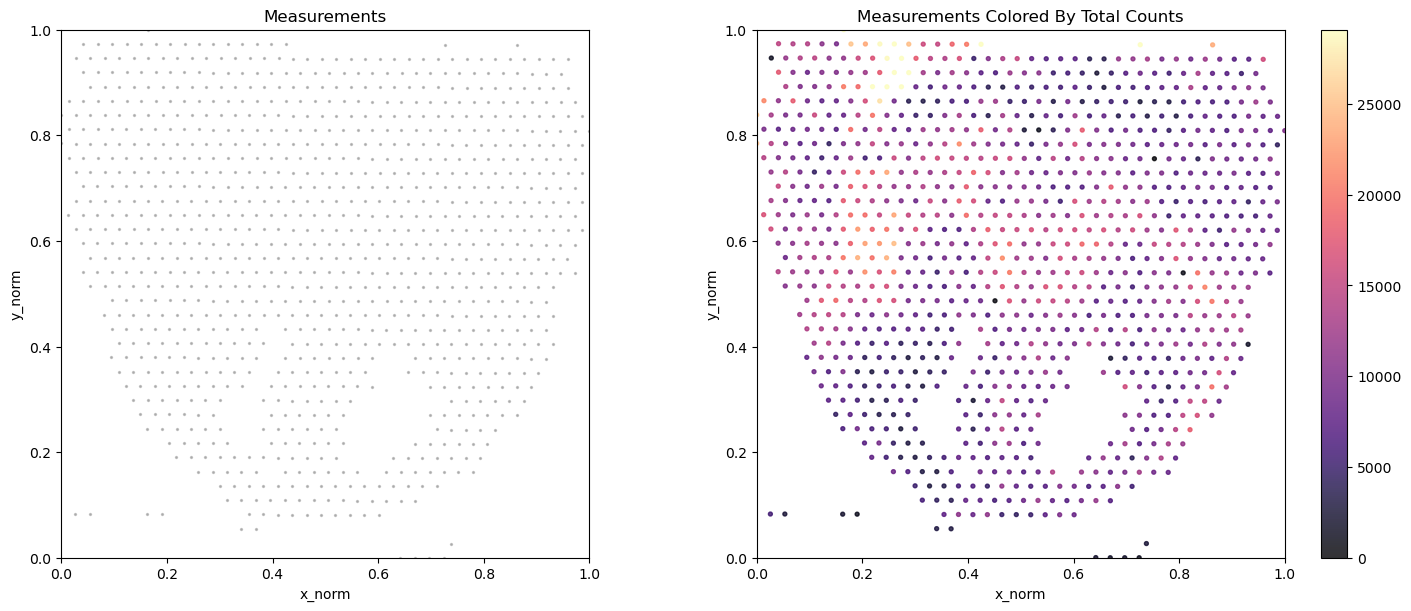

Cells shown: 984 / 984
Total count summary: mean=10330.0 | median=9496.0 | max=42630.0


In [3]:
cell_points_np = cell_features.detach().cpu().numpy()
cell_total_counts_np = cell_targets.sum(dim=1).detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

sample_n = min(50000, len(cell_points_np))
sample_idx = np.random.default_rng(0).choice(len(cell_points_np), size=sample_n, replace=False)

axes[0].scatter(cell_points_np[sample_idx, 0], cell_points_np[sample_idx, 1], s=2, alpha=0.2, color="black")
axes[0].set_title("Measurements")

vmax = np.quantile(cell_total_counts_np, 0.99) if len(cell_total_counts_np) else 1.0
sc = axes[1].scatter(
    cell_points_np[sample_idx, 0],
    cell_points_np[sample_idx, 1],
    c=cell_total_counts_np[sample_idx],
    s=8,
    cmap="magma",
    alpha=0.8,
    vmin=0.0,
    vmax=vmax,
)
axes[1].set_title("Measurements Colored By Total Counts")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix='measurements_overview')
plt.show()

print(f"Cells shown: {sample_n:,} / {len(cell_points_np):,}")
print(f"Total count summary: mean={format_scalar(cell_total_counts_np.mean())} | median={format_scalar(np.median(cell_total_counts_np))} | max={format_scalar(cell_total_counts_np.max())}")


## Tissue Mask Diagnostics

Check the support mask directly against the observed spatial-unit positions.


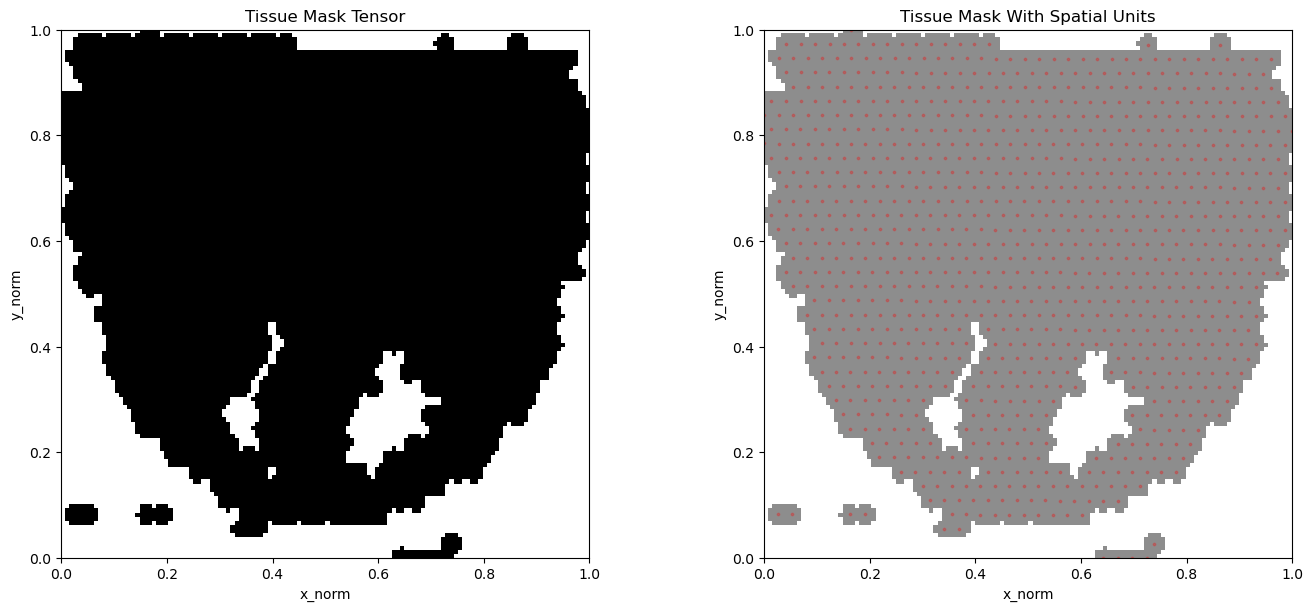

Tissue mask coverage summary
{'mask_shape': (128, 128), 'mask_mean': 0.7504, 'mask_binary_fraction_gt_0.05': 0.7504, 'sampled_spatial_units': 984}


In [4]:
mask_np = tissue_mask_tensor.squeeze().detach().cpu().numpy()
mask_binary = mask_np > 0.05
cell_points_np = cell_features.detach().cpu().numpy()

sample_n = min(50000, len(cell_points_np))
sample_idx = np.random.default_rng(0).choice(len(cell_points_np), size=sample_n, replace=False)
sample_xy = cell_points_np[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

axes[0].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r")
axes[0].set_title("Tissue Mask Tensor")

axes[1].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.45)
axes[1].scatter(sample_xy[:, 0], sample_xy[:, 1], s=3, alpha=0.25, color="red")
axes[1].set_title("Tissue Mask With Spatial Units")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

export_figure_axes(fig, fallback_prefix='tissue_mask')
plt.show()

print("Tissue mask coverage summary")
print(format_for_display({
    "mask_shape": tuple(mask_np.shape),
    "mask_mean": float(mask_np.mean()),
    "mask_binary_fraction_gt_0.05": float(mask_binary.mean()),
    "sampled_spatial_units": int(sample_n),
}))


## Normalized Profile Autoencoder

Train an encoder/decoder on normalized gene-expression profiles so the latent space can later be used to initialize splat biology programs.


In [5]:
set_seed(ae_seed)
cell_train_idx, cell_val_idx, cell_test_idx = make_split_indices(len(cell_features), seed=split_seed, device=device)

cell_total_counts = cell_targets.sum(dim=1, keepdim=True).clamp_min(1.0)
cell_profiles = cell_targets.float() / cell_total_counts

ae_epochs = 300
ae_batch_size = 256
ae_lr = 1e-3

set_seed(ae_seed)
profile_autoencoder = GeneProfileAutoencoder(
    num_genes=num_genes,
    hidden_dim=splat_cfg.hidden_dim,
    latent_dim=splat_cfg.latent_dim,
).to(device)
profile_autoencoder_opt = torch.optim.Adam(profile_autoencoder.parameters(), lr=ae_lr)

print(format_for_display({
    'train_cells': int(len(cell_train_idx)),
    'val_cells': int(len(cell_val_idx)),
    'test_cells': int(len(cell_test_idx)),
    'latent_dim': int(splat_cfg.latent_dim),
    'hidden_dim': int(splat_cfg.hidden_dim),
}))


{'train_cells': 787, 'val_cells': 98, 'test_cells': 99, 'latent_dim': 32, 'hidden_dim': 256}


## Autoencoder Training

Optimize the encoder/decoder only on normalized profiles. Total-count magnitude stays outside this path.


AE epoch 0 | train_loss=10.37 | val={'loss': 10.33, 'mae': 5.425e-05, 'cosine': 0.1467, 'n': 98}
AE epoch 1 | train_loss=10.28 | val={'loss': 10.19, 'mae': 5.333e-05, 'cosine': 0.1677, 'n': 98}
AE epoch 2 | train_loss=10.1 | val={'loss': 9.92, 'mae': 5.11e-05, 'cosine': 0.2139, 'n': 98}
AE epoch 3 | train_loss=9.763 | val={'loss': 9.452, 'mae': 4.578e-05, 'cosine': 0.2957, 'n': 98}
AE epoch 4 | train_loss=9.231 | val={'loss': 8.862, 'mae': 3.711e-05, 'cosine': 0.3927, 'n': 98}
AE epoch 5 | train_loss=8.737 | val={'loss': 8.578, 'mae': 3.06e-05, 'cosine': 0.5555, 'n': 98}
AE epoch 6 | train_loss=8.52 | val={'loss': 8.375, 'mae': 2.68e-05, 'cosine': 0.7222, 'n': 98}
AE epoch 7 | train_loss=8.308 | val={'loss': 8.22, 'mae': 2.602e-05, 'cosine': 0.8054, 'n': 98}
AE epoch 8 | train_loss=8.24 | val={'loss': 8.237, 'mae': 2.769e-05, 'cosine': 0.8339, 'n': 98}
AE epoch 9 | train_loss=8.237 | val={'loss': 8.219, 'mae': 2.724e-05, 'cosine': 0.8399, 'n': 98}
AE epoch 10 | train_loss=8.23 | val={'

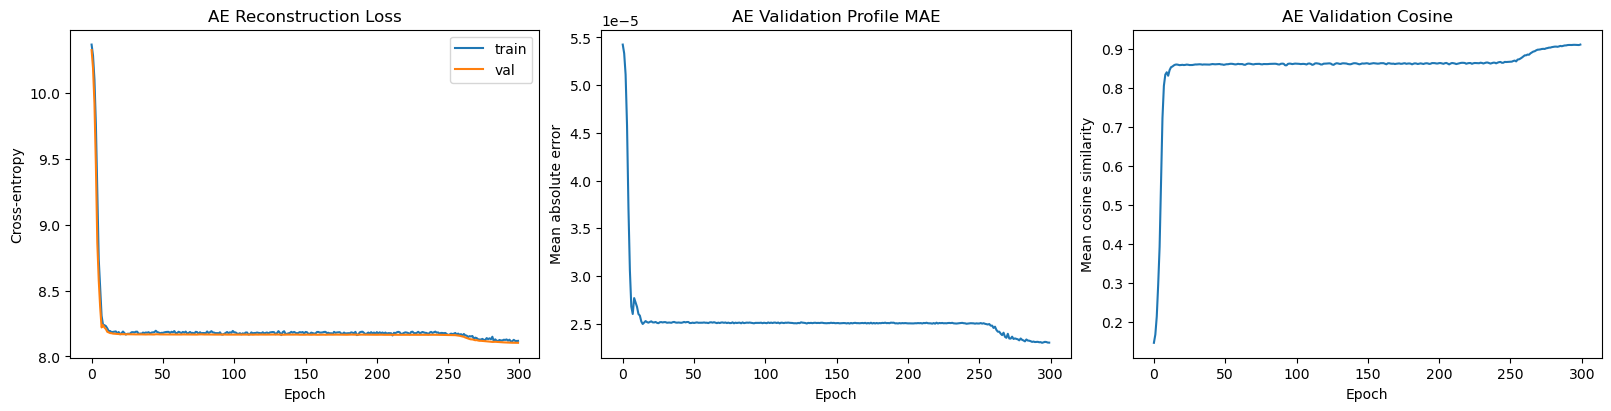

In [6]:
def _record_ae_epoch(epoch, train_loss, val_metrics):
    print(f"AE epoch {epoch} | train_loss={format_scalar(train_loss)} | val={format_for_display(val_metrics)}")


ae_history = train_profile_autoencoder(
    profile_autoencoder,
    cell_profiles,
    cell_train_idx,
    cell_val_idx,
    epochs=ae_epochs,
    batch_size=ae_batch_size,
    optimizer=profile_autoencoder_opt,
    max_grad_norm=5.0,
    on_epoch_end=_record_ae_epoch,
)

ae_test_metrics = evaluate_profile_autoencoder(profile_autoencoder, cell_profiles, cell_test_idx, batch_size=ae_batch_size)
print('Normalized-profile autoencoder test')
print(format_for_display(ae_test_metrics))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(ae_history['train_loss'], label='train')
axes[0].plot(ae_history['val_loss'], label='val')
axes[0].set_title('AE Reconstruction Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy')
axes[0].legend()

axes[1].plot(ae_history['val_mae'])
axes[1].set_title('AE Validation Profile MAE')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean absolute error')

axes[2].plot(ae_history['val_cosine'])
axes[2].set_title('AE Validation Cosine')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Mean cosine similarity')

export_figure_axes(fig, fallback_prefix='ae_training')
plt.show()


## Autoencoder Diagnostics

Check whether reconstructed normalized profiles preserve overall composition and marker structure well enough to support latent initialization.


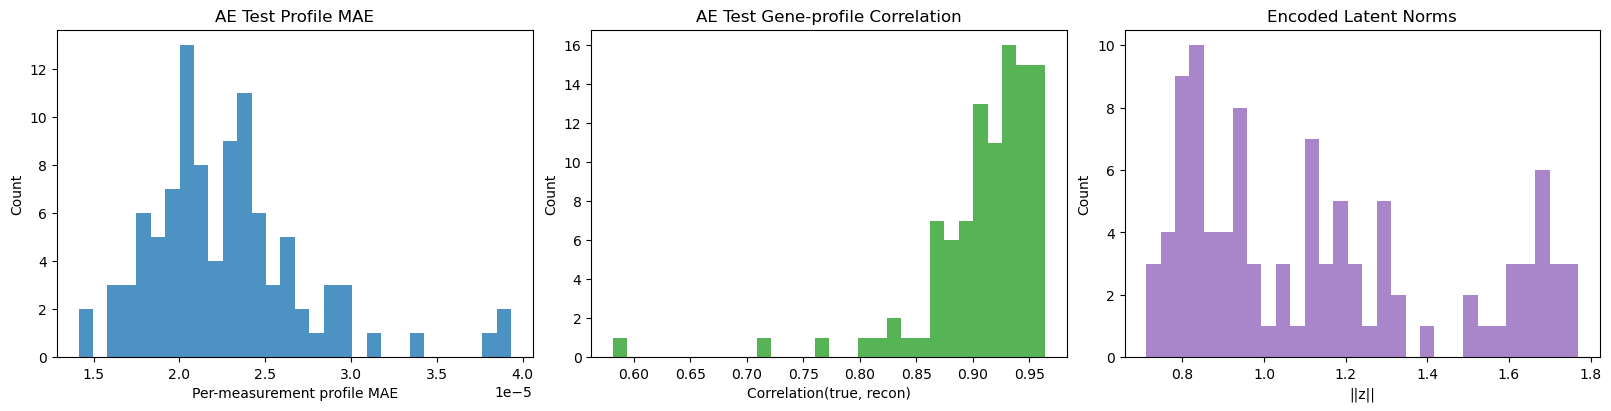

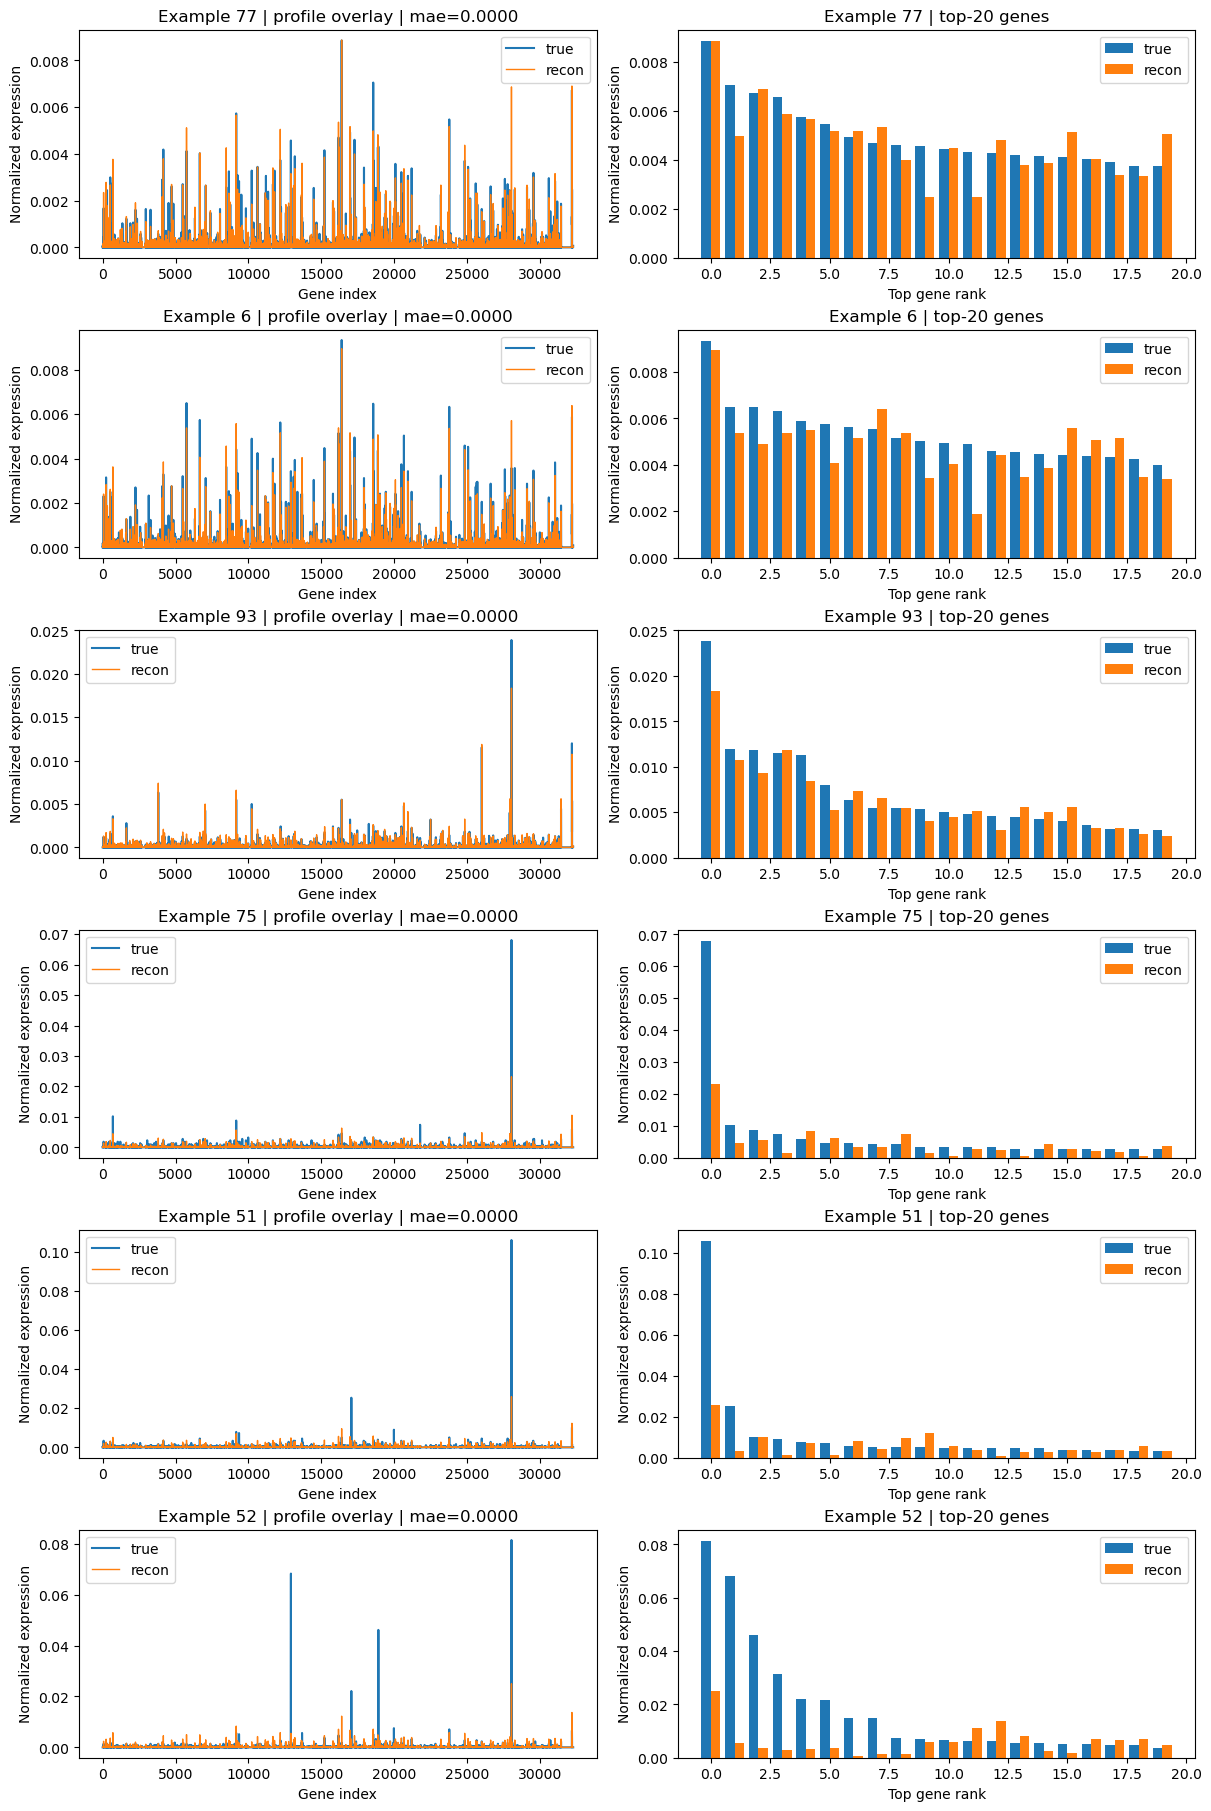

{'diag_cells': 99, 'diag_mae_mean': 2.276e-05, 'diag_mae_median': 2.244e-05, 'diag_corr_mean': 0.9088, 'diag_corr_median': 0.9157}
Worst AE test examples by MAE
[{'local_diag_index': 52, 'original_cell_index': 400, 'mae': 3.933e-05, 'corr': 0.5816}, {'local_diag_index': 51, 'original_cell_index': 566, 'mae': 3.89e-05, 'corr': 0.714}, {'local_diag_index': 75, 'original_cell_index': 914, 'mae': 3.8e-05, 'corr': 0.7684}, {'local_diag_index': 61, 'original_cell_index': 229, 'mae': 3.419e-05, 'corr': 0.7986}, {'local_diag_index': 63, 'original_cell_index': 366, 'mae': 3.095e-05, 'corr': 0.8679}]
Worst AE test examples by correlation
[{'local_diag_index': 52, 'original_cell_index': 400, 'mae': 3.933e-05, 'corr': 0.5816}, {'local_diag_index': 51, 'original_cell_index': 566, 'mae': 3.89e-05, 'corr': 0.714}, {'local_diag_index': 75, 'original_cell_index': 914, 'mae': 3.8e-05, 'corr': 0.7684}, {'local_diag_index': 61, 'original_cell_index': 229, 'mae': 3.419e-05, 'corr': 0.7986}, {'local_diag_in

In [7]:
set_seed(seed_init_seed)
with torch.no_grad():
    diag_idx = cell_test_idx[:min(len(cell_test_idx), 256)]
    diag_profiles = cell_profiles[diag_idx]
    diag_latents, _, diag_recon_profiles = profile_autoencoder(diag_profiles)

diag_mae = (diag_recon_profiles - diag_profiles).abs().mean(dim=1).detach().cpu().numpy()
diag_true_np = diag_profiles.detach().cpu().numpy()
diag_recon_np = diag_recon_profiles.detach().cpu().numpy()
diag_latent_np = diag_latents.detach().cpu().numpy()
diag_corr = [np.corrcoef(t, r)[0, 1] if np.std(t) > 0 and np.std(r) > 0 else np.nan for t, r in zip(diag_true_np, diag_recon_np)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].hist(diag_mae, bins=30, color='tab:blue', alpha=0.8)
axes[0].set_title('AE Test Profile MAE')
axes[0].set_xlabel('Per-measurement profile MAE')
axes[0].set_ylabel('Count')

axes[1].hist([x for x in diag_corr if np.isfinite(x)], bins=30, color='tab:green', alpha=0.8)
axes[1].set_title('AE Test Gene-profile Correlation')
axes[1].set_xlabel('Correlation(true, recon)')
axes[1].set_ylabel('Count')

latent_norms = np.linalg.norm(diag_latent_np, axis=1)
axes[2].hist(latent_norms, bins=30, color='tab:purple', alpha=0.8)
axes[2].set_title('Encoded Latent Norms')
axes[2].set_xlabel('||z||')
axes[2].set_ylabel('Count')

export_figure_axes(fig, fallback_prefix='ae_test_summary')
export_figure_axes(fig, fallback_prefix='ae_examples')
plt.show()

diag_idx_np = diag_idx.detach().cpu().numpy()
diag_corr_np = np.asarray(diag_corr, dtype=np.float64)
worst_mae_order = np.argsort(diag_mae)[::-1]
finite_corr_mask = np.isfinite(diag_corr_np)
worst_corr_order = np.argsort(diag_corr_np[finite_corr_mask]) if finite_corr_mask.any() else np.array([], dtype=np.int64)
finite_corr_local_idx = np.flatnonzero(finite_corr_mask)
worst_k = min(5, len(diag_mae))
worst_mae_examples = [
    {
        'local_diag_index': int(local_idx),
        'original_cell_index': int(diag_idx_np[local_idx]),
        'mae': float(diag_mae[local_idx]),
        'corr': float(diag_corr_np[local_idx]) if np.isfinite(diag_corr_np[local_idx]) else float('nan'),
    }
    for local_idx in worst_mae_order[:worst_k]
]
worst_corr_examples = [
    {
        'local_diag_index': int(finite_corr_local_idx[pos]),
        'original_cell_index': int(diag_idx_np[finite_corr_local_idx[pos]]),
        'mae': float(diag_mae[finite_corr_local_idx[pos]]),
        'corr': float(diag_corr_np[finite_corr_local_idx[pos]]),
    }
    for pos in worst_corr_order[:worst_k]
]

example_idx = np.argsort(diag_mae)[:3].tolist() + np.argsort(diag_mae)[-3:].tolist()
example_idx = list(dict.fromkeys(example_idx))
fig, axes = plt.subplots(len(example_idx), 2, figsize=(12, 3 * len(example_idx)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, local_idx in enumerate(example_idx):
    axes[row, 0].plot(diag_true_np[local_idx], label='true', linewidth=1.5)
    axes[row, 0].plot(diag_recon_np[local_idx], label='recon', linewidth=1.0)
    axes[row, 0].set_title(f'Example {local_idx} | profile overlay | mae={diag_mae[local_idx]:.4f}')
    axes[row, 0].set_xlabel('Gene index')
    axes[row, 0].set_ylabel('Normalized expression')
    axes[row, 0].legend()

    gene_order = np.argsort(diag_true_np[local_idx])[::-1][:20]
    x = np.arange(len(gene_order))
    axes[row, 1].bar(x - 0.2, diag_true_np[local_idx, gene_order], width=0.4, label='true')
    axes[row, 1].bar(x + 0.2, diag_recon_np[local_idx, gene_order], width=0.4, label='recon')
    axes[row, 1].set_title(f'Example {local_idx} | top-20 genes')
    axes[row, 1].set_xlabel('Top gene rank')
    axes[row, 1].set_ylabel('Normalized expression')
    axes[row, 1].legend()

plt.show()

print(format_for_display({
    'diag_cells': int(len(diag_idx)),
    'diag_mae_mean': float(np.mean(diag_mae)),
    'diag_mae_median': float(np.median(diag_mae)),
    'diag_corr_mean': float(np.nanmean(diag_corr)),
    'diag_corr_median': float(np.nanmedian(diag_corr)),
}))
print('Worst AE test examples by MAE')
print(format_for_display(worst_mae_examples))
print('Worst AE test examples by correlation')
print(format_for_display(worst_corr_examples))


## Encoder-Initialized Splats

Use the trained encoder to initialize splat latents from local neighborhoods around initial splat centers.


In [8]:
init_neighbor_k = 16

with torch.no_grad():
    seed_idx = farthest_point_sample_indices(cell_features, splat_cfg.num_splats)
    seed_xy = cell_features[seed_idx]
    pairwise_dist = torch.cdist(seed_xy, cell_features)
    neighbor_k = min(init_neighbor_k, cell_features.shape[0])
    neighbor_dist, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)

    neighbor_profiles = cell_profiles[neighbor_idx]
    neighbor_totals = cell_total_counts[neighbor_idx]
    avg_profiles = neighbor_profiles.mean(dim=1)
    avg_profiles = avg_profiles / avg_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)
    avg_totals = neighbor_totals.mean(dim=1)
    encoded_seed_latents = profile_autoencoder.encoder(avg_profiles)

encoder_initialized_splat_model = AmplitudeSplatField(
    num_splats=splat_cfg.num_splats,
    latent_dim=splat_cfg.latent_dim,
    hidden_dim=splat_cfg.hidden_dim,
    num_genes=num_genes,
    init_log_scale=splat_cfg.init_log_scale,
    kernel_sharpness=splat_cfg.kernel_sharpness,
    init_log_amplitude=init_log_amplitude,
).to(device)

with torch.no_grad():
    encoder_initialized_splat_model.means.copy_(seed_xy)
    encoder_initialized_splat_model.latents.copy_(encoded_seed_latents)
    encoder_initialized_splat_model.log_amplitudes.copy_(avg_totals.clamp_min(1.0).log())
    encoder_initialized_splat_model.log_scales.fill_(splat_cfg.init_log_scale)
    encoder_initialized_splat_model.rotation.zero_()
    encoder_initialized_splat_model.opacity_logits.zero_()
    encoder_initialized_splat_model.decoder.load_state_dict(profile_autoencoder.decoder.state_dict())

print(format_for_display({
    'num_splats': int(splat_cfg.num_splats),
    'neighbor_k': int(neighbor_k),
    'seed_profile_shape': tuple(avg_profiles.shape),
    'seed_latent_shape': tuple(encoded_seed_latents.shape),
    'mean_neighbor_total_count': float(avg_totals.mean().item()),
    'median_neighbor_total_count': float(avg_totals.median().item()),
}))


{'num_splats': 64, 'neighbor_k': 16, 'seed_profile_shape': (64, 32285), 'seed_latent_shape': (64, 32), 'mean_neighbor_total_count': 9975.0, 'median_neighbor_total_count': 9409.0}


## Encoder Initialization Diagnostics

Inspect the seed locations and compare neighborhood-averaged profiles against the decoder output from the initialized latents.


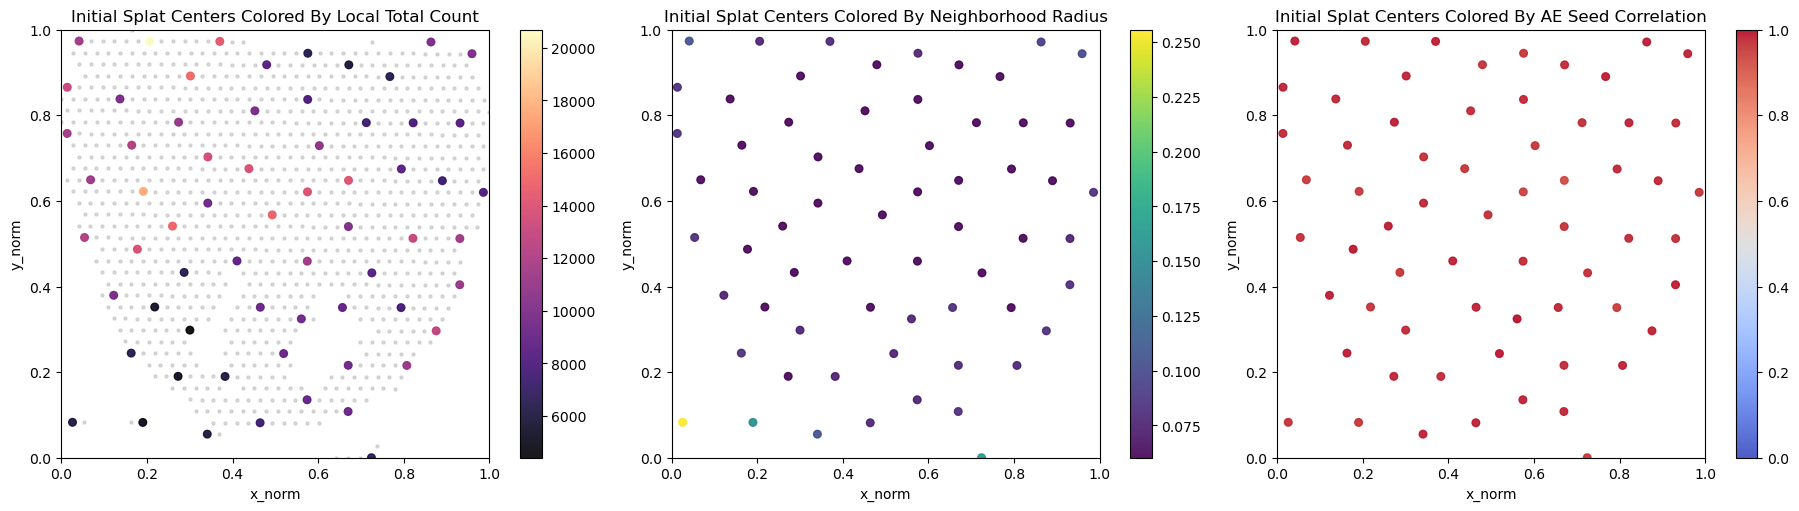

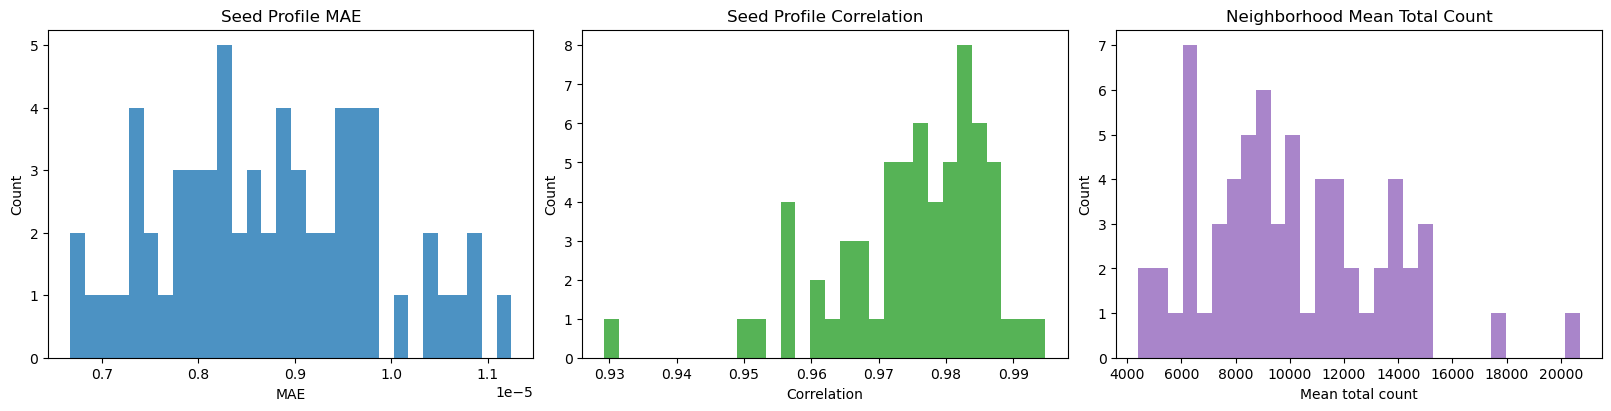

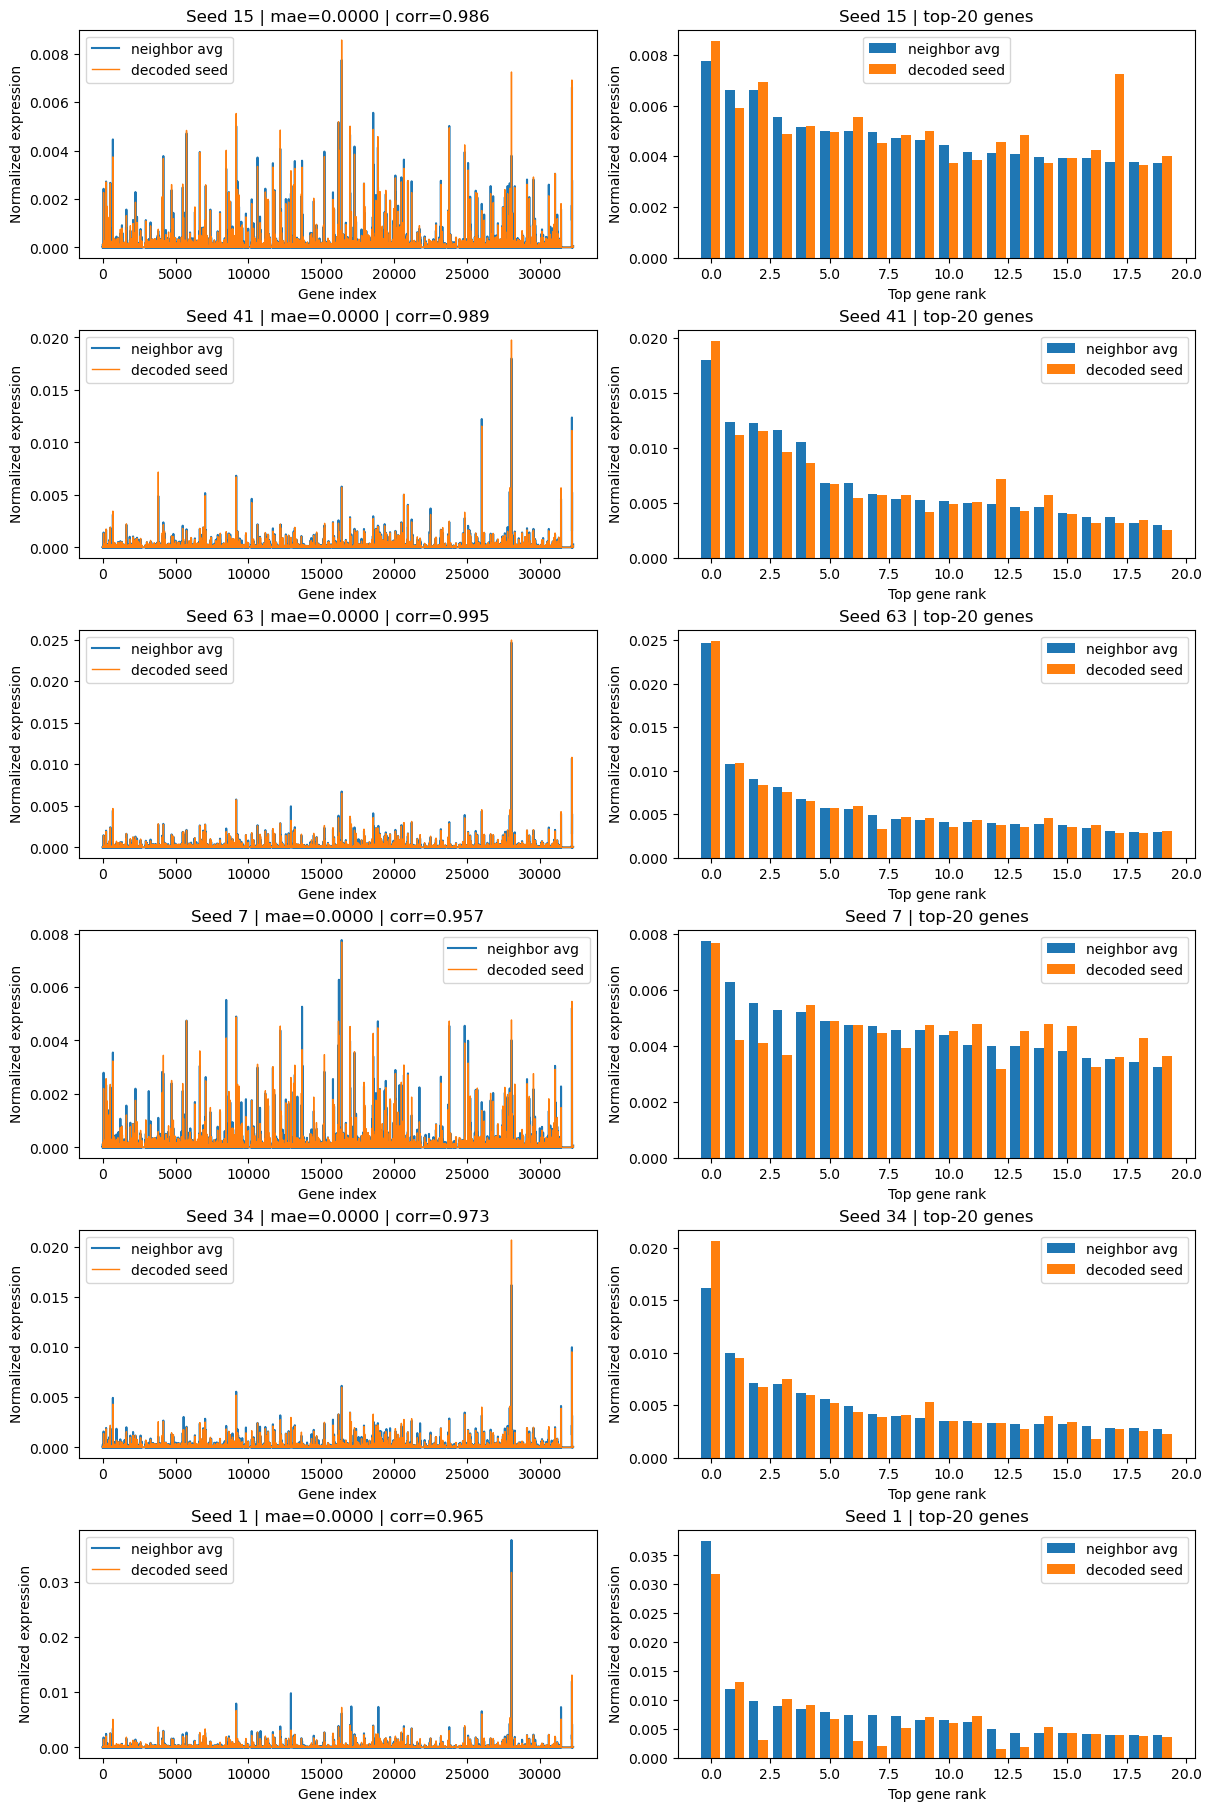

{'seed_mae_mean': 8.754e-06, 'seed_mae_median': 8.776e-06, 'seed_corr_mean': 0.9749, 'seed_corr_median': 0.9768, 'neighbor_radius_mean': 0.07515, 'neighbor_radius_median': 0.06057}


In [9]:
with torch.no_grad():
    seed_gene_logits, _ = encoder_initialized_splat_model.decoder(encoded_seed_latents)
    decoded_seed_profiles = torch.softmax(seed_gene_logits, dim=1)

seed_xy_np = seed_xy.detach().cpu().numpy()
avg_profiles_np = avg_profiles.detach().cpu().numpy()
decoded_seed_profiles_np = decoded_seed_profiles.detach().cpu().numpy()
avg_totals_np = avg_totals.squeeze(-1).detach().cpu().numpy()
neighbor_radius_np = neighbor_dist[:, -1].detach().cpu().numpy()
seed_mae = np.mean(np.abs(decoded_seed_profiles_np - avg_profiles_np), axis=1)
seed_corr = np.array([
    np.corrcoef(t, r)[0, 1] if np.std(t) > 0 and np.std(r) > 0 else np.nan
    for t, r in zip(avg_profiles_np, decoded_seed_profiles_np)
], dtype=np.float64)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes[0].scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=5, alpha=0.12, color='black')
sc0 = axes[0].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=avg_totals_np, s=30, cmap='magma', alpha=0.9)
axes[0].set_title('Initial Splat Centers Colored By Local Total Count')
fig.colorbar(sc0, ax=axes[0], fraction=0.046, pad=0.04)

sc1 = axes[1].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=neighbor_radius_np, s=30, cmap='viridis', alpha=0.9)
axes[1].set_title('Initial Splat Centers Colored By Neighborhood Radius')
fig.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.04)

sc2 = axes[2].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=seed_corr, s=30, cmap='coolwarm', alpha=0.9, vmin=0.0, vmax=1.0)
axes[2].set_title('Initial Splat Centers Colored By AE Seed Correlation')
fig.colorbar(sc2, ax=axes[2], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix='seed_centers')
export_figure_axes(fig, fallback_prefix='seed_summary')
export_figure_axes(fig, fallback_prefix='seed_examples')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].hist(seed_mae, bins=30, color='tab:blue', alpha=0.8)
axes[0].set_title('Seed Profile MAE')
axes[0].set_xlabel('MAE')
axes[0].set_ylabel('Count')

axes[1].hist(seed_corr[np.isfinite(seed_corr)], bins=30, color='tab:green', alpha=0.8)
axes[1].set_title('Seed Profile Correlation')
axes[1].set_xlabel('Correlation')
axes[1].set_ylabel('Count')

axes[2].hist(avg_totals_np, bins=30, color='tab:purple', alpha=0.8)
axes[2].set_title('Neighborhood Mean Total Count')
axes[2].set_xlabel('Mean total count')
axes[2].set_ylabel('Count')

plt.show()

best_seed_idx = np.argsort(seed_mae)[:3].tolist()
worst_seed_idx = np.argsort(seed_mae)[-3:].tolist()
example_seed_idx = list(dict.fromkeys(best_seed_idx + worst_seed_idx))
fig, axes = plt.subplots(len(example_seed_idx), 2, figsize=(12, 3 * len(example_seed_idx)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, local_idx in enumerate(example_seed_idx):
    axes[row, 0].plot(avg_profiles_np[local_idx], label='neighbor avg', linewidth=1.5)
    axes[row, 0].plot(decoded_seed_profiles_np[local_idx], label='decoded seed', linewidth=1.0)
    axes[row, 0].set_title(f'Seed {local_idx} | mae={seed_mae[local_idx]:.4f} | corr={seed_corr[local_idx]:.3f}')
    axes[row, 0].set_xlabel('Gene index')
    axes[row, 0].set_ylabel('Normalized expression')
    axes[row, 0].legend()

    gene_order = np.argsort(avg_profiles_np[local_idx])[::-1][:20]
    x = np.arange(len(gene_order))
    axes[row, 1].bar(x - 0.2, avg_profiles_np[local_idx, gene_order], width=0.4, label='neighbor avg')
    axes[row, 1].bar(x + 0.2, decoded_seed_profiles_np[local_idx, gene_order], width=0.4, label='decoded seed')
    axes[row, 1].set_title(f'Seed {local_idx} | top-20 genes')
    axes[row, 1].set_xlabel('Top gene rank')
    axes[row, 1].set_ylabel('Normalized expression')
    axes[row, 1].legend()

plt.show()

print(format_for_display({
    'seed_mae_mean': float(np.mean(seed_mae)),
    'seed_mae_median': float(np.median(seed_mae)),
    'seed_corr_mean': float(np.nanmean(seed_corr)),
    'seed_corr_median': float(np.nanmedian(seed_corr)),
    'neighbor_radius_mean': float(np.mean(neighbor_radius_np)),
    'neighbor_radius_median': float(np.median(neighbor_radius_np)),
}))


## Baselines

Run the same baseline models used in the older notebook on the canonical train/val/test split before coarse splat training.


In [10]:
reconstruction_loss_fn = mae_count_loss
composition_loss_weight = 1.0
total_count_loss_weight = 0.1
mae_refine_weight = 1.0
mae_refine_fraction = 0.25

train_cell_features = cell_features[cell_train_idx]
train_cell_targets = cell_targets[cell_train_idx]
baseline_mae_refine_start_epoch = max(0, int(round((1.0 - mae_refine_fraction) * train_cfg.baseline_epochs)))

def train_mae_baseline(model, optimizer):
    for epoch in range(train_cfg.baseline_epochs):
        model.train()
        perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        for start in range(0, len(perm), train_cfg.baseline_batch_size):
            idx = perm[start:start + train_cfg.baseline_batch_size]
            loss = reconstruction_loss_fn(model(cell_features[idx]), cell_targets[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

def train_bio_objective_baseline(model, optimizer):
    for epoch in range(train_cfg.baseline_epochs):
        model.train()
        mae_refine_active = epoch >= baseline_mae_refine_start_epoch
        perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        for start in range(0, len(perm), train_cfg.baseline_batch_size):
            idx = perm[start:start + train_cfg.baseline_batch_size]
            pred_log_rate = model(cell_features[idx])
            pred_counts = torch.exp(pred_log_rate)
            cell_loss = mae_count_loss(pred_log_rate, cell_targets[idx]) if mae_refine_active else pred_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(pred_counts, cell_targets[idx])
            total_count_loss = log_total_count_loss(pred_log_rate, cell_targets[idx])
            loss = (
                mae_refine_weight * cell_loss
                + composition_loss_weight * composition_loss
                + total_count_loss_weight * total_count_loss
            )
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

set_seed(baseline_mean_seed)
mean_cell_model = MeanProfileBaseline(train_cell_targets).to(device)
mean_cell_val = evaluate_count_model(mean_cell_model, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
mean_cell_test = evaluate_count_model(mean_cell_model, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Mean baseline')
print(format_for_display(mean_cell_val))
print(format_for_display(mean_cell_test))

set_seed(baseline_mlp_mae_seed)
cell_mlp_mae = CountMLP(input_dim=2, hidden_dim=128, output_dim=num_genes).to(device)
cell_mlp_mae_opt = torch.optim.Adam(cell_mlp_mae.parameters(), lr=1e-3)
train_mae_baseline(cell_mlp_mae, cell_mlp_mae_opt)
cell_mlp_mae_val = evaluate_count_model(cell_mlp_mae, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_mlp_mae_test = evaluate_count_model(cell_mlp_mae, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('MLP-MAE')
print(format_for_display(cell_mlp_mae_val))
print(format_for_display(cell_mlp_mae_test))

set_seed(baseline_mlp_bio_seed)
cell_mlp = CountMLP(input_dim=2, hidden_dim=128, output_dim=num_genes).to(device)
cell_mlp_opt = torch.optim.Adam(cell_mlp.parameters(), lr=1e-3)
train_bio_objective_baseline(cell_mlp, cell_mlp_opt)
cell_mlp_val = evaluate_count_model(cell_mlp, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_mlp_test = evaluate_count_model(cell_mlp, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('MLP (Bio Objective)')
print(format_for_display(cell_mlp_val))
print(format_for_display(cell_mlp_test))

set_seed(baseline_fourier_mae_seed)
cell_fourier_mlp_mae = FourierFeatureMLP(input_dim=2, hidden_dim=128, output_dim=num_genes, num_frequencies=32, sigma=10.0).to(device)
cell_fourier_mlp_mae_opt = torch.optim.Adam(cell_fourier_mlp_mae.parameters(), lr=1e-3)
train_mae_baseline(cell_fourier_mlp_mae, cell_fourier_mlp_mae_opt)
cell_fourier_mlp_mae_val = evaluate_count_model(cell_fourier_mlp_mae, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_fourier_mlp_mae_test = evaluate_count_model(cell_fourier_mlp_mae, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Fourier MLP-MAE')
print(format_for_display(cell_fourier_mlp_mae_val))
print(format_for_display(cell_fourier_mlp_mae_test))

set_seed(baseline_fourier_bio_seed)
cell_fourier_mlp = FourierFeatureMLP(input_dim=2, hidden_dim=128, output_dim=num_genes, num_frequencies=32, sigma=10.0).to(device)
cell_fourier_opt = torch.optim.Adam(cell_fourier_mlp.parameters(), lr=1e-3)
train_bio_objective_baseline(cell_fourier_mlp, cell_fourier_opt)
cell_fourier_val = evaluate_count_model(cell_fourier_mlp, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_fourier_test = evaluate_count_model(cell_fourier_mlp, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Fourier MLP (Bio Objective)')
print(format_for_display(cell_fourier_val))
print(format_for_display(cell_fourier_test))

cell_knn = KNNCountRegressor(train_cell_features, train_cell_targets, k=64).to(device)
cell_knn_val = evaluate_count_model(cell_knn, cell_features, cell_targets, cell_val_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
cell_knn_test = evaluate_count_model(cell_knn, cell_features, cell_targets, cell_test_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
print('KNN')
print(format_for_display(cell_knn_val))
print(format_for_display(cell_knn_test))

set_seed(baseline_budget_knn_seed)
budget_knn_budget = min(splat_cfg.num_splats, len(cell_train_idx))
budget_knn_candidate_limit = None
if len(cell_train_idx) > 100000:
    budget_knn_candidate_limit = min(len(cell_train_idx), max(4 * budget_knn_budget, 50000))
budget_knn_local_idx = farthest_point_sample_indices(
    train_cell_features,
    budget_knn_budget,
    candidate_limit=budget_knn_candidate_limit,
    random_state=baseline_budget_knn_seed,
)
cell_budget_knn = KNNCountRegressor(
    train_cell_features[budget_knn_local_idx],
    train_cell_targets[budget_knn_local_idx],
    k=64,
).to(device)
cell_budget_knn_val = evaluate_count_model(cell_budget_knn, cell_features, cell_targets, cell_val_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
cell_budget_knn_test = evaluate_count_model(cell_budget_knn, cell_features, cell_targets, cell_test_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
print('Budget-matched KNN')
print(format_for_display({
    'prototype_cells': int(len(budget_knn_local_idx)),
    'candidate_pool': int(budget_knn_candidate_limit or len(cell_train_idx)),
}))
print(format_for_display(cell_budget_knn_val))
print(format_for_display(cell_budget_knn_test))

baseline_summary = {
    'Mean baseline': {'val': mean_cell_val, 'test': mean_cell_test},
    'MLP-MAE': {'val': cell_mlp_mae_val, 'test': cell_mlp_mae_test},
    'MLP (Bio Objective)': {'val': cell_mlp_val, 'test': cell_mlp_test},
    'Fourier MLP-MAE': {'val': cell_fourier_mlp_mae_val, 'test': cell_fourier_mlp_mae_test},
    'Fourier MLP (Bio Objective)': {'val': cell_fourier_val, 'test': cell_fourier_test},
    'KNN': {'val': cell_knn_val, 'test': cell_knn_test},
    'Budget-matched KNN': {'val': cell_budget_knn_val, 'test': cell_budget_knn_test},
}
print('Baseline summary')
print(format_for_display(baseline_summary))

for model_name in ['mean_cell_model', 'cell_mlp_mae', 'cell_mlp', 'cell_fourier_mlp_mae', 'cell_fourier_mlp']:
    globals()[model_name] = globals()[model_name].cpu()
del cell_mlp_mae_opt
del cell_mlp_opt
del cell_fourier_mlp_mae_opt
del cell_fourier_opt
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Mean baseline
{'loss': 0.2871, 'mae': 0.2871, 'n': 98}
{'loss': 0.2897, 'mae': 0.2897, 'n': 99}
MLP-MAE
{'loss': 0.2295, 'mae': 0.2295, 'n': 98}
{'loss': 0.2365, 'mae': 0.2365, 'n': 99}
MLP (Bio Objective)
{'loss': 0.2321, 'mae': 0.2321, 'n': 98}
{'loss': 0.2379, 'mae': 0.2379, 'n': 99}
Fourier MLP-MAE
{'loss': 0.2622, 'mae': 0.2622, 'n': 98}
{'loss': 0.2657, 'mae': 0.2657, 'n': 99}
Fourier MLP (Bio Objective)
{'loss': 0.2633, 'mae': 0.2633, 'n': 98}
{'loss': 0.2675, 'mae': 0.2675, 'n': 99}
KNN
{'loss': 0.2491, 'mae': 0.2491, 'n': 98}
{'loss': 0.2542, 'mae': 0.2542, 'n': 99}
Budget-matched KNN
{'prototype_cells': 64, 'candidate_pool': 787}
{'loss': 0.2726, 'mae': 0.2726, 'n': 98}
{'loss': 0.2771, 'mae': 0.2771, 'n': 99}
Baseline summary
{'Mean baseline': {'val': {'loss': 0.2871, 'mae': 0.2871, 'n': 98}, 'test': {'loss': 0.2897, 'mae': 0.2897, 'n': 99}}, 'MLP-MAE': {'val': {'loss': 0.2295, 'mae': 0.2295, 'n': 98}, 'test': {'loss': 0.2365, 'mae': 0.2365, 'n': 99}}, 'MLP (Bio Objective)':

## Splat Training Setup

Train the coarse splat field twice with the same objective and schedule: once from random initialization and once from AE-neighbor initialization.


In [11]:
reconstruction_loss_fn = mae_count_loss
composition_loss_weight = 1.0
total_count_loss_weight = 0.1
mae_refine_weight = 1.0
mae_refine_fraction = 0.25
freeze_geometry_during_mae_refine = True
coarse_log_every = 10

def build_random_splat_model():
    return AmplitudeSplatField(
        num_splats=splat_cfg.num_splats,
        latent_dim=splat_cfg.latent_dim,
        hidden_dim=splat_cfg.hidden_dim,
        num_genes=num_genes,
        init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness,
        init_log_amplitude=init_log_amplitude,
    ).to(device)

def clone_splat_model(model):
    cloned = AmplitudeSplatField(
        num_splats=model.num_splats,
        latent_dim=model.latent_dim,
        hidden_dim=model.hidden_dim,
        num_genes=model.num_genes,
        init_log_scale=model.init_log_scale,
        kernel_sharpness=model.kernel_sharpness,
        init_log_amplitude=float(model.log_amplitudes.detach().mean().item()),
    ).to(model.means.device)
    cloned.load_state_dict({k: v.detach().clone() for k, v in model.state_dict().items()})
    cloned.eval()
    return cloned

def train_coarse_splat_model(initial_model, label: str, seed: int, freeze_decoder: bool = False, freeze_geometry_during_mae: bool = True, num_epochs = None):
    set_seed(seed)
    splat_model = clone_splat_model(initial_model)
    if freeze_decoder:
        for param in splat_model.decoder.parameters():
            param.requires_grad_(False)
    initial_state = capture_initial_splat_state(splat_model)
    splat_opt = create_amplitude_splat_optimizer(
        splat_model,
        means_lr=train_cfg.splat_means_lr,
        log_scales_lr=train_cfg.splat_log_scales_lr,
        rotation_lr=train_cfg.splat_rotation_lr,
        opacity_lr=train_cfg.splat_opacity_lr,
        latents_lr=train_cfg.splat_latents_lr,
        log_theta_lr=train_cfg.splat_log_theta_lr,
        decoder_lr=train_cfg.splat_decoder_lr,
        amplitude_lr=train_cfg.splat_amplitude_lr,
    )
    train_epochs = int(train_cfg.splat_epochs if num_epochs is None else num_epochs)
    coarse_mae_refine_start_epoch = max(0, int(round((1.0 - mae_refine_fraction) * train_epochs)))
    history = {
        'train_joint_loss': [],
        'train_composition_loss': [],
        'train_total_count_loss': [],
        'train_cell_loss': [],
        'val_loss': [],
        'val_mae': [],
        'val_phase': [],
    }
    print(f"{label} | coarse loss weights: composition={format_scalar(composition_loss_weight)}, total={format_scalar(total_count_loss_weight)}, mae_refine={format_scalar(mae_refine_weight)}, off_tissue={format_scalar(train_cfg.off_tissue_weight)}, center_support={format_scalar(train_cfg.center_support_weight)}, freeze_decoder={freeze_decoder}, freeze_geometry_during_mae={freeze_geometry_during_mae}")

    for epoch in range(train_epochs):
        splat_model.train()
        mae_refine_active = epoch >= coarse_mae_refine_start_epoch
        geometry_lr_scale = 0.0 if (mae_refine_active and freeze_geometry_during_mae) else 1.0
        splat_opt.param_groups[0]['lr'] = train_cfg.splat_means_lr * geometry_lr_scale
        splat_opt.param_groups[1]['lr'] = train_cfg.splat_log_scales_lr * geometry_lr_scale
        splat_opt.param_groups[2]['lr'] = train_cfg.splat_rotation_lr * geometry_lr_scale
        splat_opt.param_groups[3]['lr'] = train_cfg.splat_opacity_lr * geometry_lr_scale
        splat_opt.param_groups[4]['lr'] = train_cfg.splat_latents_lr
        splat_opt.param_groups[5]['lr'] = train_cfg.splat_log_theta_lr
        splat_opt.param_groups[6]['lr'] = 0.0 if freeze_decoder else train_cfg.splat_decoder_lr
        splat_opt.param_groups[7]['lr'] = train_cfg.splat_amplitude_lr
        cell_perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        off_perm = torch.randperm(len(off_tissue_points), device=device)
        batch_size = min(train_cfg.cell_batch_size, 1024)
        off_batch_size = min(train_cfg.off_tissue_batch_size, 1024)
        num_steps = max(1, (len(cell_perm) + batch_size - 1) // batch_size)
        running = {
            'joint_loss': 0.0,
            'cell_loss': 0.0,
            'composition_loss': 0.0,
            'total_count_loss': 0.0,
            'off_tissue_loss': 0.0,
            'center_support_loss': 0.0,
        }

        for step in range(num_steps):
            cell_start = (step * batch_size) % len(cell_perm)
            off_start = (step * off_batch_size) % len(off_perm)
            cell_idx = cell_perm[cell_start:cell_start + batch_size]
            off_idx = off_perm[off_start:off_start + off_batch_size]
            if len(cell_idx) == 0:
                cell_idx = cell_perm[:batch_size]
            if len(off_idx) == 0:
                off_idx = off_perm[:off_batch_size]

            pred_cell_log_rate = predict_cell_log_rates(
                splat_model,
                cell_features[cell_idx],
                cell_spans[cell_idx],
                batch_size=batch_size,
            )
            off_tissue_intensity = splat_model.total_intensity(off_tissue_points[off_idx])
            center_support = sample_tissue_support(splat_model.means, tissue_mask_tensor)

            cell_loss = mae_count_loss(pred_cell_log_rate, cell_targets[cell_idx]) if mae_refine_active else pred_cell_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(torch.exp(pred_cell_log_rate), cell_targets[cell_idx])
            total_count_loss = log_total_count_loss(pred_cell_log_rate, cell_targets[cell_idx])
            off_tissue_loss = off_tissue_intensity.mean()
            center_support_loss = (1.0 - center_support).mean()
            loss = mae_refine_weight * cell_loss + composition_loss_weight * composition_loss + total_count_loss_weight * total_count_loss + train_cfg.off_tissue_weight * off_tissue_loss + train_cfg.center_support_weight * center_support_loss

            splat_opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(splat_model.parameters(), max_norm=5.0)
            splat_opt.step()

            with torch.no_grad():
                splat_model.means.clamp_(0.0, 1.0)
                splat_model.log_scales.clamp_(-8.0, -2.0)

            running['joint_loss'] += loss.item()
            running['cell_loss'] += cell_loss.item()
            running['composition_loss'] += composition_loss.item()
            running['total_count_loss'] += total_count_loss.item()
            running['off_tissue_loss'] += off_tissue_loss.item()
            running['center_support_loss'] += center_support_loss.item()

        train_metrics = {k: v / num_steps for k, v in running.items()}
        val_metrics = evaluate_cell_readout(
            splat_model,
            cell_features,
            cell_spans,
            cell_targets,
            cell_val_idx,
            loss_fn=reconstruction_loss_fn,
        )
        history['train_joint_loss'].append(train_metrics['joint_loss'])
        history['train_composition_loss'].append(train_metrics['composition_loss'])
        history['train_total_count_loss'].append(train_metrics['total_count_loss'])
        history['train_cell_loss'].append(train_metrics['cell_loss'])
        history['val_loss'].append(val_metrics['loss'])
        history['val_mae'].append(val_metrics['mae'])
        history['val_phase'].append('mae_refine' if mae_refine_active else 'composition')
        if epoch == 0 or (epoch + 1) % coarse_log_every == 0 or epoch == train_cfg.splat_epochs - 1:
            phase_name = 'mae_refine' if mae_refine_active else 'composition'
            print(f"{label} | epoch {epoch} [{phase_name}] | train={format_for_display(train_metrics)} | val={format_for_display(val_metrics)}")

    train_eval = evaluate_cell_readout(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_train_idx,
        loss_fn=reconstruction_loss_fn,
    )
    val_eval = evaluate_cell_readout(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_val_idx,
        loss_fn=reconstruction_loss_fn,
    )
    test_eval = evaluate_cell_readout(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_test_idx,
        loss_fn=reconstruction_loss_fn,
    )
    print(f"{label} | final train={format_for_display(train_eval)}")
    print(f"{label} | final val={format_for_display(val_eval)}")
    print(f"{label} | final test={format_for_display(test_eval)}")
    return {
        'label': label,
        'model': splat_model,
        'initial_state': initial_state,
        'history': history,
        'train_metrics': train_eval,
        'val_metrics': val_eval,
        'test_metrics': test_eval,
    }


## Splat Training Runs

Run the same coarse optimization from random initialization and from AE-neighbor initialization.


In [12]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()

set_seed(random_model_seed)
random_init_splat_model = build_random_splat_model()
random_coarse_result = train_coarse_splat_model(random_init_splat_model, label="Random init", seed=random_train_seed)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

ae_coarse_result = train_coarse_splat_model(encoder_initialized_splat_model, label="AE-neighbor init", seed=ae_train_seed)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

ae_frozen_coarse_result = train_coarse_splat_model(
    encoder_initialized_splat_model,
    label="AE-neighbor init (decoder frozen)",
    seed=ae_frozen_train_seed,
    freeze_decoder=True,
)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

ae_unfrozen_coarse_result = train_coarse_splat_model(
    encoder_initialized_splat_model,
    label="AE-neighbor init (geometry unfrozen in MAE)",
    seed=ae_unfrozen_train_seed,
    freeze_decoder=False,
    freeze_geometry_during_mae=False,
)


Random init | coarse loss weights: composition=1.0, total=0.1, mae_refine=1.0, off_tissue=0.0, center_support=0.1, freeze_decoder=False, freeze_geometry_during_mae=True
Random init | epoch 0 [composition] | train={'joint_loss': 0.9861, 'cell_loss': 0.0, 'composition_loss': 0.8569, 'total_count_loss': 1.11, 'off_tissue_loss': 2984.0, 'center_support_loss': 0.1821} | val={'loss': 0.3992, 'mae': 0.3992, 'n': 98}
Random init | epoch 9 [composition] | train={'joint_loss': 0.3147, 'cell_loss': 0.0, 'composition_loss': 0.1757, 'total_count_loss': 1.104, 'off_tissue_loss': 3037.0, 'center_support_loss': 0.2858} | val={'loss': 0.2739, 'mae': 0.2739, 'n': 98}
Random init | epoch 19 [composition] | train={'joint_loss': 0.2568, 'cell_loss': 0.0, 'composition_loss': 0.1201, 'total_count_loss': 1.085, 'off_tissue_loss': 3113.0, 'center_support_loss': 0.282} | val={'loss': 0.2971, 'mae': 0.2971, 'n': 98}
Random init | epoch 29 [composition] | train={'joint_loss': 0.2428, 'cell_loss': 0.0, 'compositio

## Splat Training Comparison

Compare final split metrics and convergence behavior for the two initialization strategies.


Training summary
{'Random init': {'train': {'loss': 0.2095, 'mae': 0.2095, 'n': 787}, 'val': {'loss': 0.2245, 'mae': 0.2245, 'n': 98}, 'test': {'loss': 0.2273, 'mae': 0.2273, 'n': 99}}, 'AE-neighbor init': {'train': {'loss': 0.2051, 'mae': 0.2051, 'n': 787}, 'val': {'loss': 0.2188, 'mae': 0.2188, 'n': 98}, 'test': {'loss': 0.2232, 'mae': 0.2232, 'n': 99}}, 'AE-neighbor init (decoder frozen)': {'train': {'loss': 0.2298, 'mae': 0.2298, 'n': 787}, 'val': {'loss': 0.2453, 'mae': 0.2453, 'n': 98}, 'test': {'loss': 0.2484, 'mae': 0.2484, 'n': 99}}, 'AE-neighbor init (geometry unfrozen in MAE)': {'train': {'loss': 0.2052, 'mae': 0.2052, 'n': 787}, 'val': {'loss': 0.2181, 'mae': 0.2181, 'n': 98}, 'test': {'loss': 0.2246, 'mae': 0.2246, 'n': 99}}}


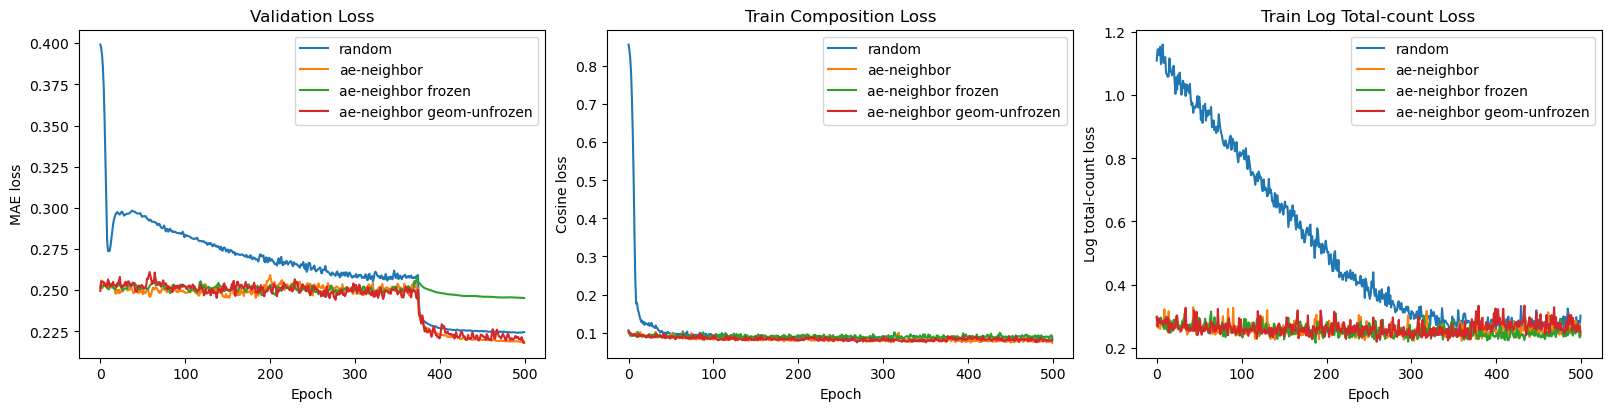

In [13]:
comparison_summary = {
    'Random init': {
        'train': random_coarse_result['train_metrics'],
        'val': random_coarse_result['val_metrics'],
        'test': random_coarse_result['test_metrics'],
    },
    'AE-neighbor init': {
        'train': ae_coarse_result['train_metrics'],
        'val': ae_coarse_result['val_metrics'],
        'test': ae_coarse_result['test_metrics'],
    },
    'AE-neighbor init (decoder frozen)': {
        'train': ae_frozen_coarse_result['train_metrics'],
        'val': ae_frozen_coarse_result['val_metrics'],
        'test': ae_frozen_coarse_result['test_metrics'],
    },
    'AE-neighbor init (geometry unfrozen in MAE)': {
        'train': ae_unfrozen_coarse_result['train_metrics'],
        'val': ae_unfrozen_coarse_result['val_metrics'],
        'test': ae_unfrozen_coarse_result['test_metrics'],
    },
}
print('Training summary')
print(format_for_display(comparison_summary))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(random_coarse_result['history']['val_loss'], label='random')
axes[0].plot(ae_coarse_result['history']['val_loss'], label='ae-neighbor')
axes[0].plot(ae_frozen_coarse_result['history']['val_loss'], label='ae-neighbor frozen')
axes[0].plot(ae_unfrozen_coarse_result['history']['val_loss'], label='ae-neighbor geom-unfrozen')
axes[0].set_title('Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MAE loss')
axes[0].legend()

axes[1].plot(random_coarse_result['history']['train_composition_loss'], label='random')
axes[1].plot(ae_coarse_result['history']['train_composition_loss'], label='ae-neighbor')
axes[1].plot(ae_frozen_coarse_result['history']['train_composition_loss'], label='ae-neighbor frozen')
axes[1].plot(ae_unfrozen_coarse_result['history']['train_composition_loss'], label='ae-neighbor geom-unfrozen')
axes[1].set_title('Train Composition Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cosine loss')
axes[1].legend()

axes[2].plot(random_coarse_result['history']['train_total_count_loss'], label='random')
axes[2].plot(ae_coarse_result['history']['train_total_count_loss'], label='ae-neighbor')
axes[2].plot(ae_frozen_coarse_result['history']['train_total_count_loss'], label='ae-neighbor frozen')
axes[2].plot(ae_unfrozen_coarse_result['history']['train_total_count_loss'], label='ae-neighbor geom-unfrozen')
axes[2].set_title('Train Log Total-count Loss')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Log total-count loss')
axes[2].legend()

export_figure_axes(fig, fallback_prefix='validation_training_losses')
plt.show()


In [14]:
coarse_reference_summary = {
    'Random init': {
        'train': {'loss': 0.212, 'mae': 0.212, 'n': 787},
        'val': {'loss': 0.235, 'mae': 0.235, 'n': 98},
        'test': {'loss': 0.234, 'mae': 0.234, 'n': 99},
    },
    'AE-neighbor init': {
        'train': {'loss': 0.207, 'mae': 0.207, 'n': 787},
        'val': {'loss': 0.224, 'mae': 0.224, 'n': 98},
        'test': {'loss': 0.231, 'mae': 0.231, 'n': 99},
    },
    'AE-neighbor init (decoder frozen)': {
        'train': {'loss': 0.230, 'mae': 0.230, 'n': 787},
        'val': {'loss': 0.244, 'mae': 0.244, 'n': 98},
        'test': {'loss': 0.248, 'mae': 0.248, 'n': 99},
    },
    'AE-neighbor init (geometry unfrozen in MAE)': {
        'train': {'loss': 0.212, 'mae': 0.212, 'n': 787},
        'val': {'loss': 0.223, 'mae': 0.223, 'n': 98},
        'test': {'loss': 0.231, 'mae': 0.231, 'n': 99},
    },
}

print('Coarse reference summary')
print(format_for_display(coarse_reference_summary))

coarse_reference_test_mae = {
    key: value['test']['mae']
    for key, value in coarse_reference_summary.items()
}
print('Reference test MAE only')
print(format_for_display(coarse_reference_test_mae))


Coarse reference summary
{'Random init': {'train': {'loss': 0.212, 'mae': 0.212, 'n': 787}, 'val': {'loss': 0.235, 'mae': 0.235, 'n': 98}, 'test': {'loss': 0.234, 'mae': 0.234, 'n': 99}}, 'AE-neighbor init': {'train': {'loss': 0.207, 'mae': 0.207, 'n': 787}, 'val': {'loss': 0.224, 'mae': 0.224, 'n': 98}, 'test': {'loss': 0.231, 'mae': 0.231, 'n': 99}}, 'AE-neighbor init (decoder frozen)': {'train': {'loss': 0.23, 'mae': 0.23, 'n': 787}, 'val': {'loss': 0.244, 'mae': 0.244, 'n': 98}, 'test': {'loss': 0.248, 'mae': 0.248, 'n': 99}}, 'AE-neighbor init (geometry unfrozen in MAE)': {'train': {'loss': 0.212, 'mae': 0.212, 'n': 787}, 'val': {'loss': 0.223, 'mae': 0.223, 'n': 98}, 'test': {'loss': 0.231, 'mae': 0.231, 'n': 99}}}
Reference test MAE only
{'Random init': 0.234, 'AE-neighbor init': 0.231, 'AE-neighbor init (decoder frozen)': 0.248, 'AE-neighbor init (geometry unfrozen in MAE)': 0.231}


## Splat Layout Comparison

Compare the active splat locations and true-scale ellipse coverage for the random and AE-neighbor models.


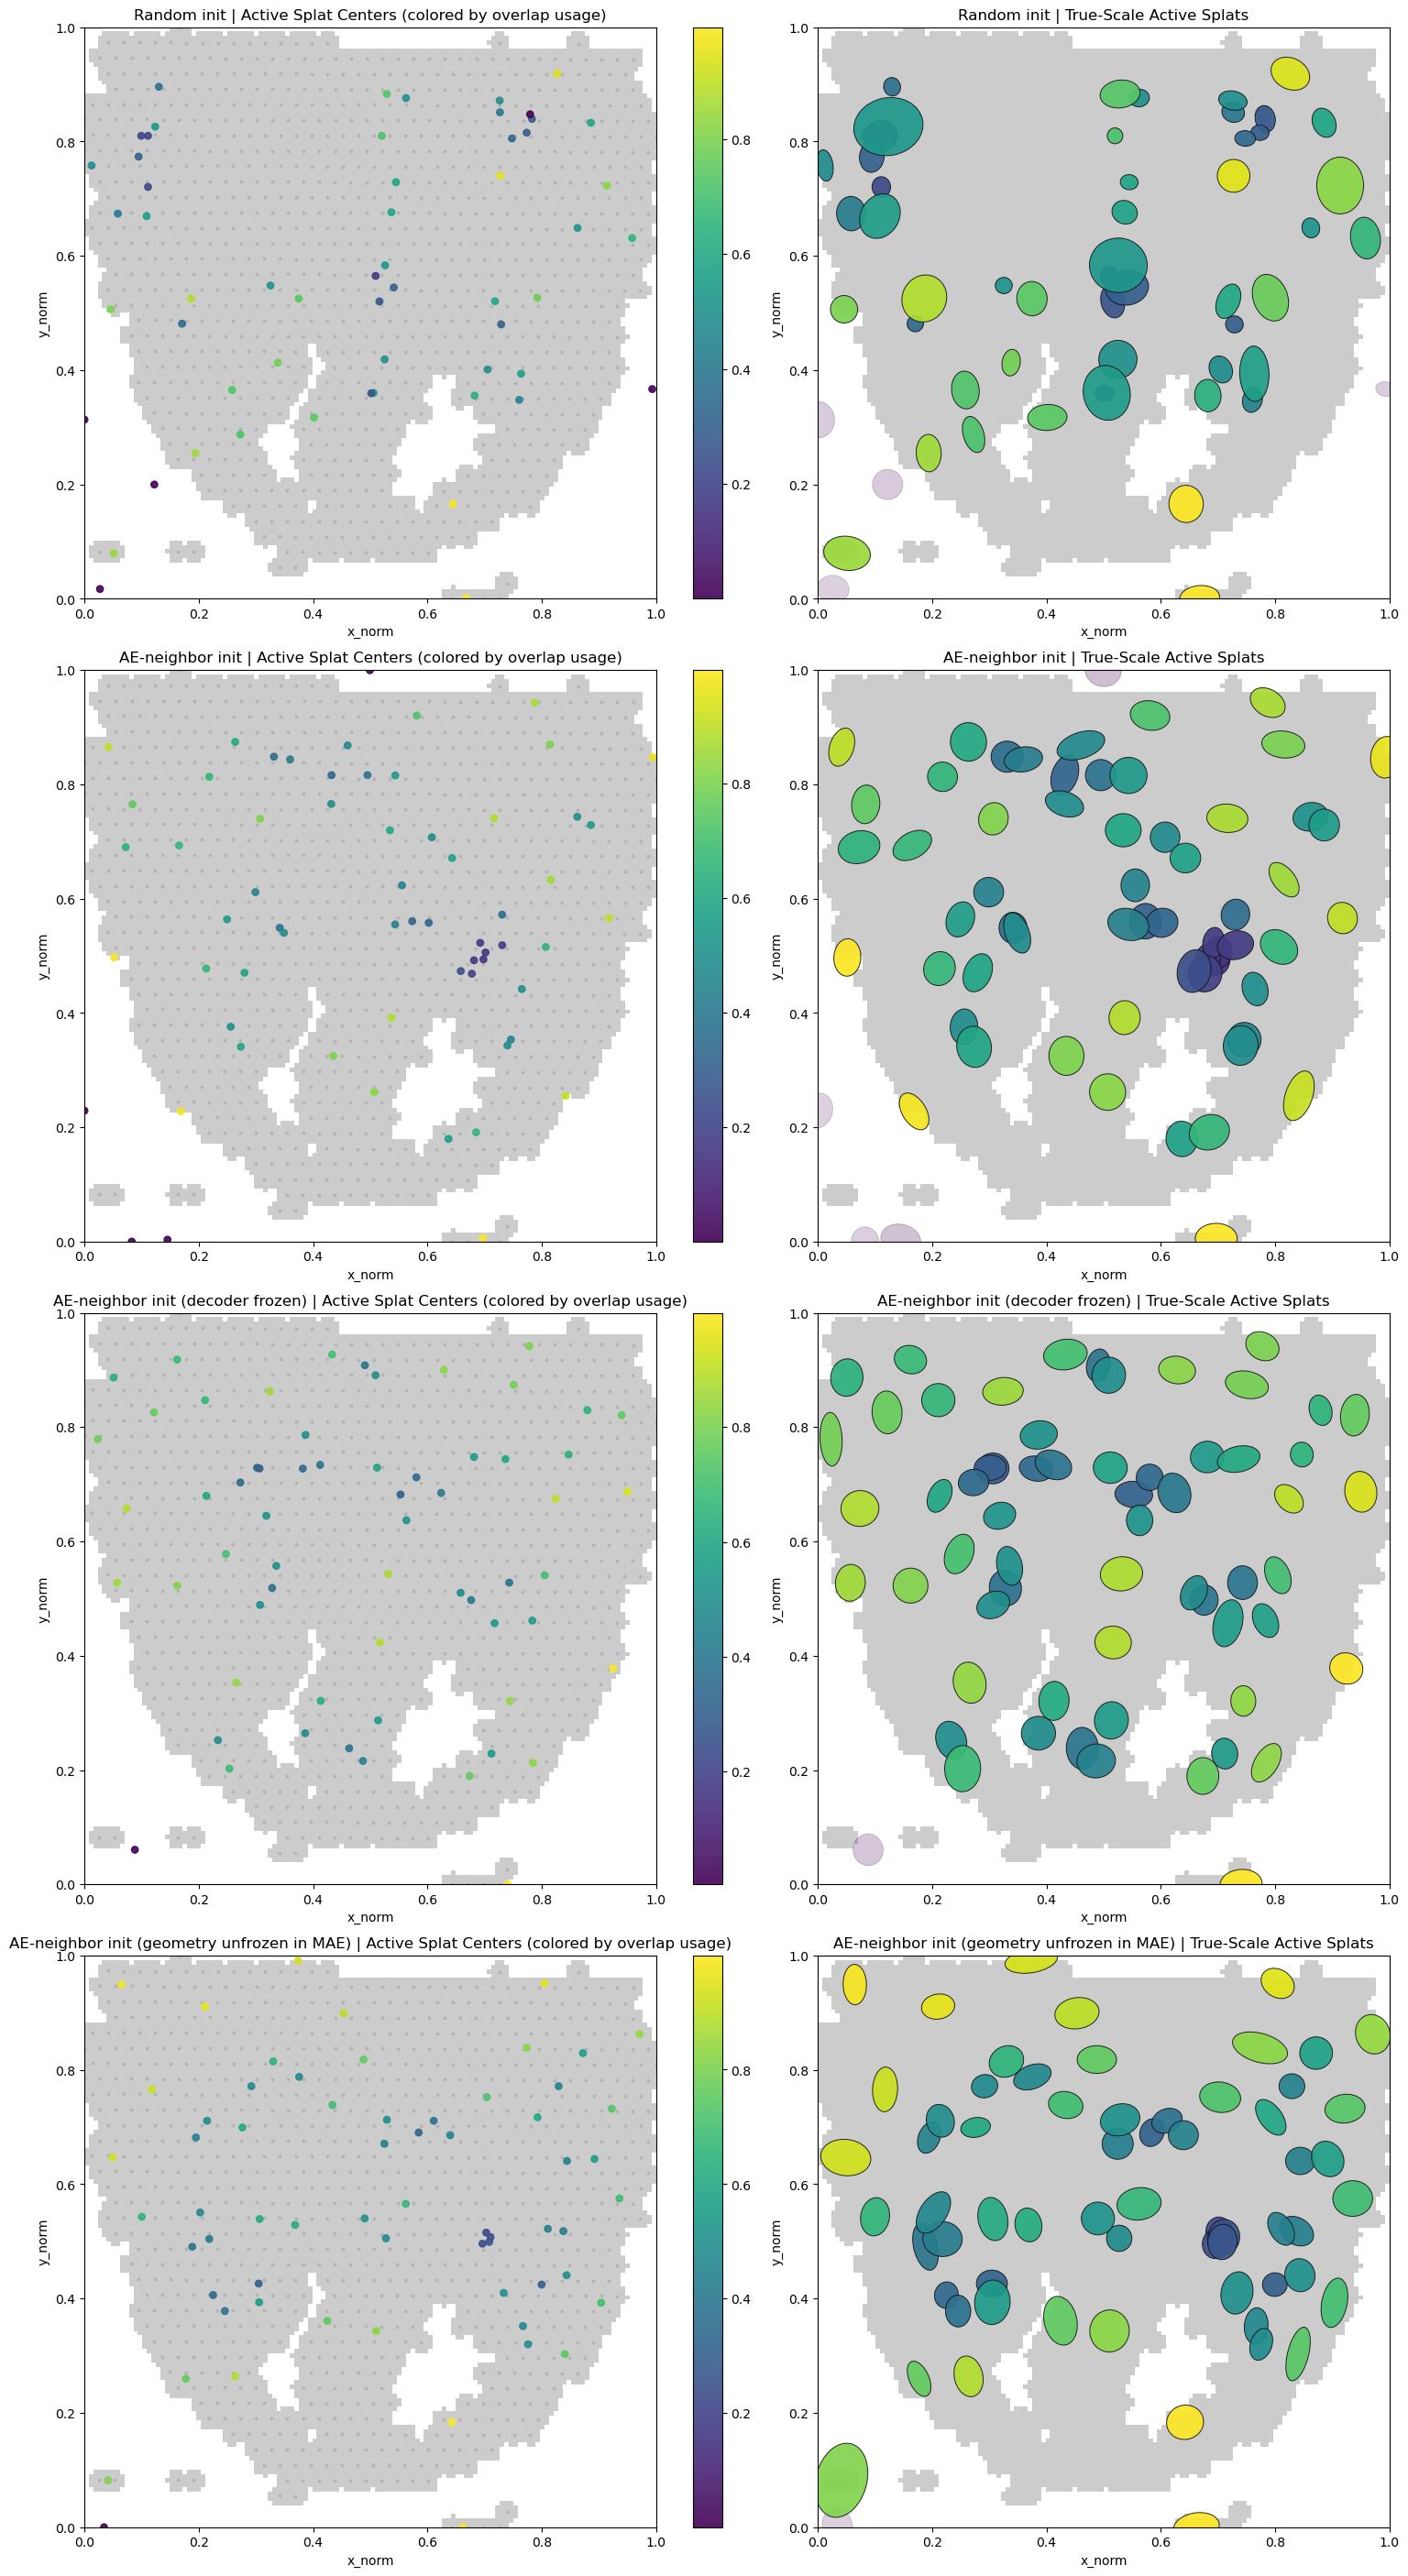

Splat layout summary
{'Random init': {'active_splats': 57, 'total_splats': 64, 'mean_usage_active': 0.01754, 'mean_overlap_usage_active': 0.5075, 'median_overlap_cell_count_active': 2.0, 'median_scale_x_active': 0.02254, 'median_scale_y_active': 0.02642, 'mean_peak_usage_active': 0.6219}, 'AE-neighbor init': {'active_splats': 63, 'total_splats': 64, 'mean_usage_active': 0.01587, 'mean_overlap_usage_active': 0.5353, 'median_overlap_cell_count_active': 3.0, 'median_scale_x_active': 0.02739, 'median_scale_y_active': 0.02856, 'mean_peak_usage_active': 0.6701}, 'AE-neighbor init (decoder frozen)': {'active_splats': 62, 'total_splats': 64, 'mean_usage_active': 0.01613, 'mean_overlap_usage_active': 0.6085, 'median_overlap_cell_count_active': 3.0, 'median_scale_x_active': 0.02827, 'median_scale_y_active': 0.02887, 'mean_peak_usage_active': 0.7273}, 'AE-neighbor init (geometry unfrozen in MAE)': {'active_splats': 64, 'total_splats': 64, 'mean_usage_active': 0.01562, 'mean_overlap_usage_active':

In [15]:
set_seed(layout_seed)
layout_query_idx = torch.randperm(len(cell_features), device=device)[:min(2048, len(cell_features))]
layout_queries = cell_features[layout_query_idx]

layout_models = [
    ('Random init', random_coarse_result['model']),
    ('AE-neighbor init', ae_coarse_result['model']),
    ('AE-neighbor init (decoder frozen)', ae_frozen_coarse_result['model']),
    ('AE-neighbor init (geometry unfrozen in MAE)', ae_unfrozen_coarse_result['model']),
]

fig, axes = plt.subplots(len(layout_models), 2, figsize=(16, 7 * len(layout_models)), constrained_layout=True)
axes = np.atleast_2d(axes)
layout_summaries = {}

for row, (label, model) in enumerate(layout_models):
    with torch.no_grad():
        layout_weights = compute_splat_weights(model, layout_queries)
        layout_mean_usage = layout_weights.mean(dim=0).detach().cpu().numpy()
        layout_peak_usage = layout_weights.max(dim=0).values.detach().cpu().numpy()
        full_layout_weights = compute_splat_weights(model, cell_features).detach().cpu().numpy()
        layout_means = model.means.detach().cpu().numpy()
        layout_scales_xy = torch.exp(model.log_scales).detach().cpu().numpy()
        layout_rotation = model.rotation.detach().cpu().numpy().reshape(-1)

    active_mask = layout_mean_usage > 1e-4
    active_idx = np.flatnonzero(active_mask)
    overlap_usage = np.zeros(len(layout_mean_usage), dtype=np.float64)
    overlap_counts = np.zeros(len(layout_mean_usage), dtype=np.int64)
    for splat_idx in active_idx:
        dx = cell_points_np[:, 0] - layout_means[splat_idx, 0]
        dy = cell_points_np[:, 1] - layout_means[splat_idx, 1]
        theta = -float(layout_rotation[splat_idx])
        c, s = np.cos(theta), np.sin(theta)
        x_rot = c * dx - s * dy
        y_rot = s * dx + c * dy
        sx = max(float(layout_scales_xy[splat_idx, 0]), 1e-8)
        sy = max(float(layout_scales_xy[splat_idx, 1]), 1e-8)
        inside_mask = (x_rot / sx) ** 2 + (y_rot / sy) ** 2 <= 1.0
        overlap_counts[splat_idx] = int(inside_mask.sum())
        if inside_mask.any():
            overlap_usage[splat_idx] = float(full_layout_weights[inside_mask, splat_idx].mean())
        else:
            overlap_usage[splat_idx] = float(layout_mean_usage[splat_idx])

    layout_summaries[label] = {
        'active_splats': int(len(active_idx)),
        'total_splats': int(len(layout_mean_usage)),
        'mean_usage_active': float(layout_mean_usage[active_idx].mean()) if len(active_idx) else float('nan'),
        'mean_overlap_usage_active': float(overlap_usage[active_idx].mean()) if len(active_idx) else float('nan'),
        'median_overlap_cell_count_active': float(np.median(overlap_counts[active_idx])) if len(active_idx) else float('nan'),
        'median_scale_x_active': float(np.median(layout_scales_xy[active_idx, 0])) if len(active_idx) else float('nan'),
        'median_scale_y_active': float(np.median(layout_scales_xy[active_idx, 1])) if len(active_idx) else float('nan'),
        'mean_peak_usage_active': float(layout_peak_usage[active_idx].mean()) if len(active_idx) else float('nan'),
    }

    ax0 = axes[row, 0]
    ax0.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    ax0.scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=4, alpha=0.08, color='black')
    if len(active_idx):
        sc0 = ax0.scatter(
            layout_means[active_idx, 0],
            layout_means[active_idx, 1],
            c=overlap_usage[active_idx],
            s=28.0,
            cmap='viridis',
            alpha=0.9,
        )
        fig.colorbar(sc0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title(f'{label} | Active Splat Centers (colored by overlap usage)')

    ax1 = axes[row, 1]
    ax1.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    draw_order = np.argsort(overlap_usage[active_idx]) if len(active_idx) else np.array([], dtype=np.int64)
    overlap_max = float(overlap_usage[active_idx].max()) if len(active_idx) else 1.0
    for local_pos in draw_order:
        splat_idx = active_idx[local_pos]
        face_color = plt.cm.viridis(min(1.0, max(0.0, overlap_usage[splat_idx] / (overlap_max + 1e-8))))
        ellipse = Ellipse(
            xy=layout_means[splat_idx],
            width=2.0 * layout_scales_xy[splat_idx, 0],
            height=2.0 * layout_scales_xy[splat_idx, 1],
            angle=float(np.degrees(layout_rotation[splat_idx])),
            facecolor=face_color,
            edgecolor=(0.08, 0.08, 0.08, 0.95),
            linewidth=0.7,
            alpha=float(np.clip(0.18 + 12.0 * overlap_usage[splat_idx], 0.18, 0.92)),
        )
        ax1.add_patch(ellipse)
    ax1.set_title(f'{label} | True-Scale Active Splats')

    for ax in (ax0, ax1):
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('x_norm')
        ax.set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix='true_scale_layout')
plt.show()
print('Splat layout summary')
print(format_for_display(layout_summaries))


## Overlap Diagnostics

Measure mixture overlap and center spacing more directly for the two coarse models.


In [16]:
set_seed(overlap_seed)
overlap_query_idx = torch.randperm(len(cell_features), device=device)[:min(2048, len(cell_features))]
overlap_queries = cell_features[overlap_query_idx]

overlap_summary = {}
for label, model in layout_models:
    with torch.no_grad():
        overlap_weights = compute_splat_weights(model, overlap_queries)
        usage = usage_statistics(overlap_weights)
        means_np = model.means.detach().cpu().numpy()
        pairwise = np.linalg.norm(means_np[:, None, :] - means_np[None, :, :], axis=-1)
        pairwise[pairwise == 0.0] = np.inf
        nearest_center_dist = pairwise.min(axis=1)
        active_mask = overlap_weights.mean(dim=0).detach().cpu().numpy() > 1e-4
        active_nearest = nearest_center_dist[active_mask] if np.any(active_mask) else np.array([], dtype=np.float64)

    overlap_summary[label] = {
        'sampled_queries': int(overlap_queries.shape[0]),
        'active_splat_fraction_gt_1e4': float(usage['active_fraction']),
        'dominant_splat_fraction_gt_5pct': float(usage['dominant_fraction']),
        'avg_splats_per_query_gt_1pct': float(usage['avg_splats_per_query_gt_1pct']),
        'median_nearest_center_distance_all': float(np.median(nearest_center_dist)),
        'mean_nearest_center_distance_all': float(np.mean(nearest_center_dist)),
        'median_nearest_center_distance_active': float(np.median(active_nearest)) if len(active_nearest) else float('nan'),
        'mean_nearest_center_distance_active': float(np.mean(active_nearest)) if len(active_nearest) else float('nan'),
    }

print('Coarse overlap summary')
print(format_for_display(overlap_summary))


Coarse overlap summary
{'Random init': {'sampled_queries': 984, 'active_splat_fraction_gt_1e4': 0.8906, 'dominant_splat_fraction_gt_5pct': 0.8906, 'avg_splats_per_query_gt_1pct': 3.595, 'median_nearest_center_distance_all': 0.05097, 'mean_nearest_center_distance_all': 0.05751, 'median_nearest_center_distance_active': 0.05108, 'mean_nearest_center_distance_active': 0.06231}, 'AE-neighbor init': {'sampled_queries': 984, 'active_splat_fraction_gt_1e4': 0.9844, 'dominant_splat_fraction_gt_5pct': 0.9844, 'avg_splats_per_query_gt_1pct': 4.552, 'median_nearest_center_distance_all': 0.06393, 'mean_nearest_center_distance_all': 0.07041, 'median_nearest_center_distance_active': 0.06252, 'mean_nearest_center_distance_active': 0.06775}, 'AE-neighbor init (decoder frozen)': {'sampled_queries': 984, 'active_splat_fraction_gt_1e4': 0.9688, 'dominant_splat_fraction_gt_5pct': 0.9688, 'avg_splats_per_query_gt_1pct': 4.417, 'median_nearest_center_distance_all': 0.06294, 'mean_nearest_center_distance_all'

## Amplitude Diagnostics

Compare each coarse model's learned splat amplitudes against the local total-count scale of nearby cells.


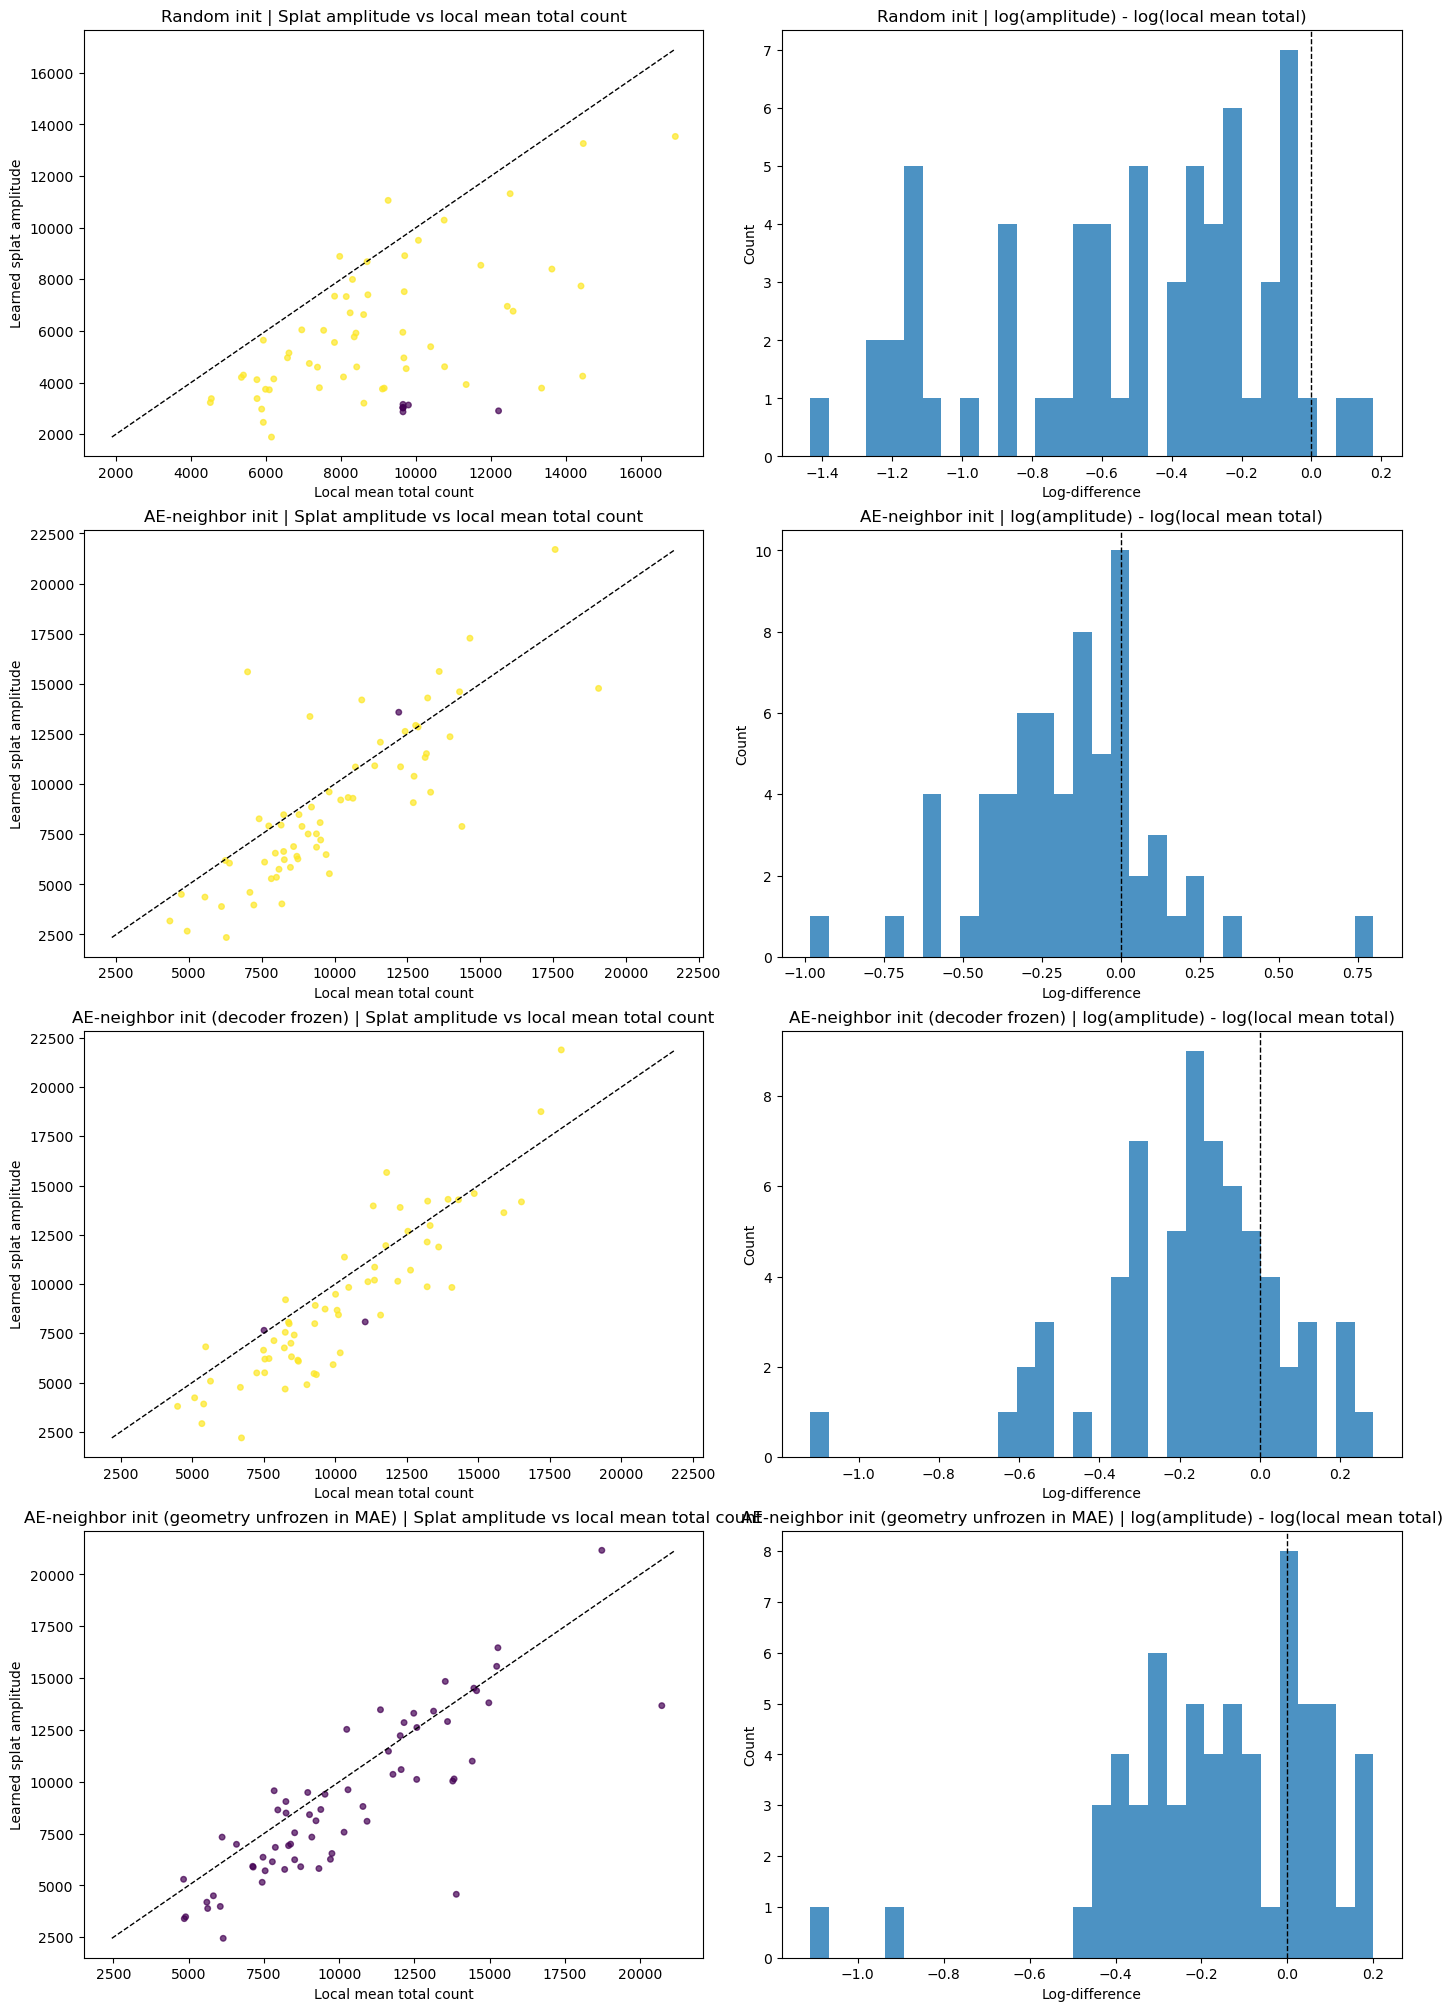

Amplitude summary
{'Random init': {'neighbor_k': 16, 'mean_local_total_count': 8990.0, 'mean_splat_amplitude': 5666.0, 'median_splat_amplitude': 4741.0, 'median_abs_log_amp_minus_local_mean': 0.4412, 'mean_abs_log_amp_minus_local_mean': 0.5252, 'median_abs_log_amp_minus_local_median': 0.4034, 'mean_abs_log_amp_minus_local_median': 0.5009, 'median_amp_to_local_mean_ratio': 0.6435, 'median_amp_to_local_median_ratio': 0.668, 'active_splats': 57, 'median_abs_log_amp_minus_local_mean_active': 0.3503, 'median_amp_to_local_mean_ratio_active': 0.7044}, 'AE-neighbor init': {'neighbor_k': 16, 'mean_local_total_count': 9884.0, 'mean_splat_amplitude': 8873.0, 'median_splat_amplitude': 7954.0, 'median_abs_log_amp_minus_local_mean': 0.1989, 'mean_abs_log_amp_minus_local_mean': 0.2371, 'median_abs_log_amp_minus_local_median': 0.1373, 'mean_abs_log_amp_minus_local_median': 0.2178, 'median_amp_to_local_mean_ratio': 0.8692, 'median_amp_to_local_median_ratio': 0.8998, 'active_splats': 63, 'median_abs_log

In [17]:
amplitude_diag_neighbor_k = init_neighbor_k
amplitude_summary = {}
fig, axes = plt.subplots(len(layout_models), 2, figsize=(14, 5 * len(layout_models)), constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (label, model) in enumerate(layout_models):
    with torch.no_grad():
        pairwise_dist = torch.cdist(model.means, cell_features)
        neighbor_k = min(amplitude_diag_neighbor_k, cell_features.shape[0])
        _, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)
        local_totals = cell_total_counts[neighbor_idx].squeeze(-1)
        local_mean_totals = local_totals.mean(dim=1)
        local_median_totals = local_totals.median(dim=1).values
        splat_amplitudes = model.splat_amplitudes().detach().squeeze(-1)
        mean_usage = compute_splat_weights(model, cell_features).mean(dim=0)
        active_mask = mean_usage > 1e-4

        log_amp = splat_amplitudes.clamp_min(1e-8).log()
        log_local_mean = local_mean_totals.clamp_min(1e-8).log()
        log_local_median = local_median_totals.clamp_min(1e-8).log()
        mean_log_diff = log_amp - log_local_mean
        median_log_diff = log_amp - log_local_median

    active_np = active_mask.detach().cpu().numpy()
    splat_amp_np = splat_amplitudes.detach().cpu().numpy()
    local_mean_np = local_mean_totals.detach().cpu().numpy()
    local_median_np = local_median_totals.detach().cpu().numpy()
    mean_log_diff_np = mean_log_diff.detach().cpu().numpy()
    median_log_diff_np = median_log_diff.detach().cpu().numpy()

    amplitude_summary[label] = {
        'neighbor_k': int(neighbor_k),
        'mean_local_total_count': float(local_mean_totals.mean().item()),
        'mean_splat_amplitude': float(splat_amplitudes.mean().item()),
        'median_splat_amplitude': float(splat_amplitudes.median().item()),
        'median_abs_log_amp_minus_local_mean': float(np.median(np.abs(mean_log_diff_np))),
        'mean_abs_log_amp_minus_local_mean': float(np.mean(np.abs(mean_log_diff_np))),
        'median_abs_log_amp_minus_local_median': float(np.median(np.abs(median_log_diff_np))),
        'mean_abs_log_amp_minus_local_median': float(np.mean(np.abs(median_log_diff_np))),
        'median_amp_to_local_mean_ratio': float(np.median(splat_amp_np / np.clip(local_mean_np, 1e-8, None))),
        'median_amp_to_local_median_ratio': float(np.median(splat_amp_np / np.clip(local_median_np, 1e-8, None))),
        'active_splats': int(active_np.sum()),
        'median_abs_log_amp_minus_local_mean_active': float(np.median(np.abs(mean_log_diff_np[active_np]))) if active_np.any() else float('nan'),
        'median_amp_to_local_mean_ratio_active': float(np.median((splat_amp_np / np.clip(local_mean_np, 1e-8, None))[active_np])) if active_np.any() else float('nan'),
    }

    ax0 = axes[row, 0]
    ax0.scatter(local_mean_np, splat_amp_np, s=16, alpha=0.7, c=np.where(active_np, 1.0, 0.25), cmap='viridis')
    lo = float(min(local_mean_np.min(), splat_amp_np.min()))
    hi = float(max(local_mean_np.max(), splat_amp_np.max()))
    ax0.plot([lo, hi], [lo, hi], linestyle='--', color='black', linewidth=1.0)
    ax0.set_title(f'{label} | Splat amplitude vs local mean total count')
    ax0.set_xlabel('Local mean total count')
    ax0.set_ylabel('Learned splat amplitude')

    ax1 = axes[row, 1]
    ax1.hist(mean_log_diff_np, bins=30, alpha=0.8, color='tab:blue')
    ax1.axvline(0.0, linestyle='--', color='black', linewidth=1.0)
    ax1.set_title(f'{label} | log(amplitude) - log(local mean total)')
    ax1.set_xlabel('Log-difference')
    ax1.set_ylabel('Count')

export_figure_axes(fig, fallback_prefix='amplitude_diagnostics')
plt.show()
print('Amplitude summary')
print(format_for_display(amplitude_summary))


## Program Drift Diagnostics

Compare decoded splat programs before and after coarse training to see whether the AE-initialized biological programs stay coherent after decoder fine-tuning.


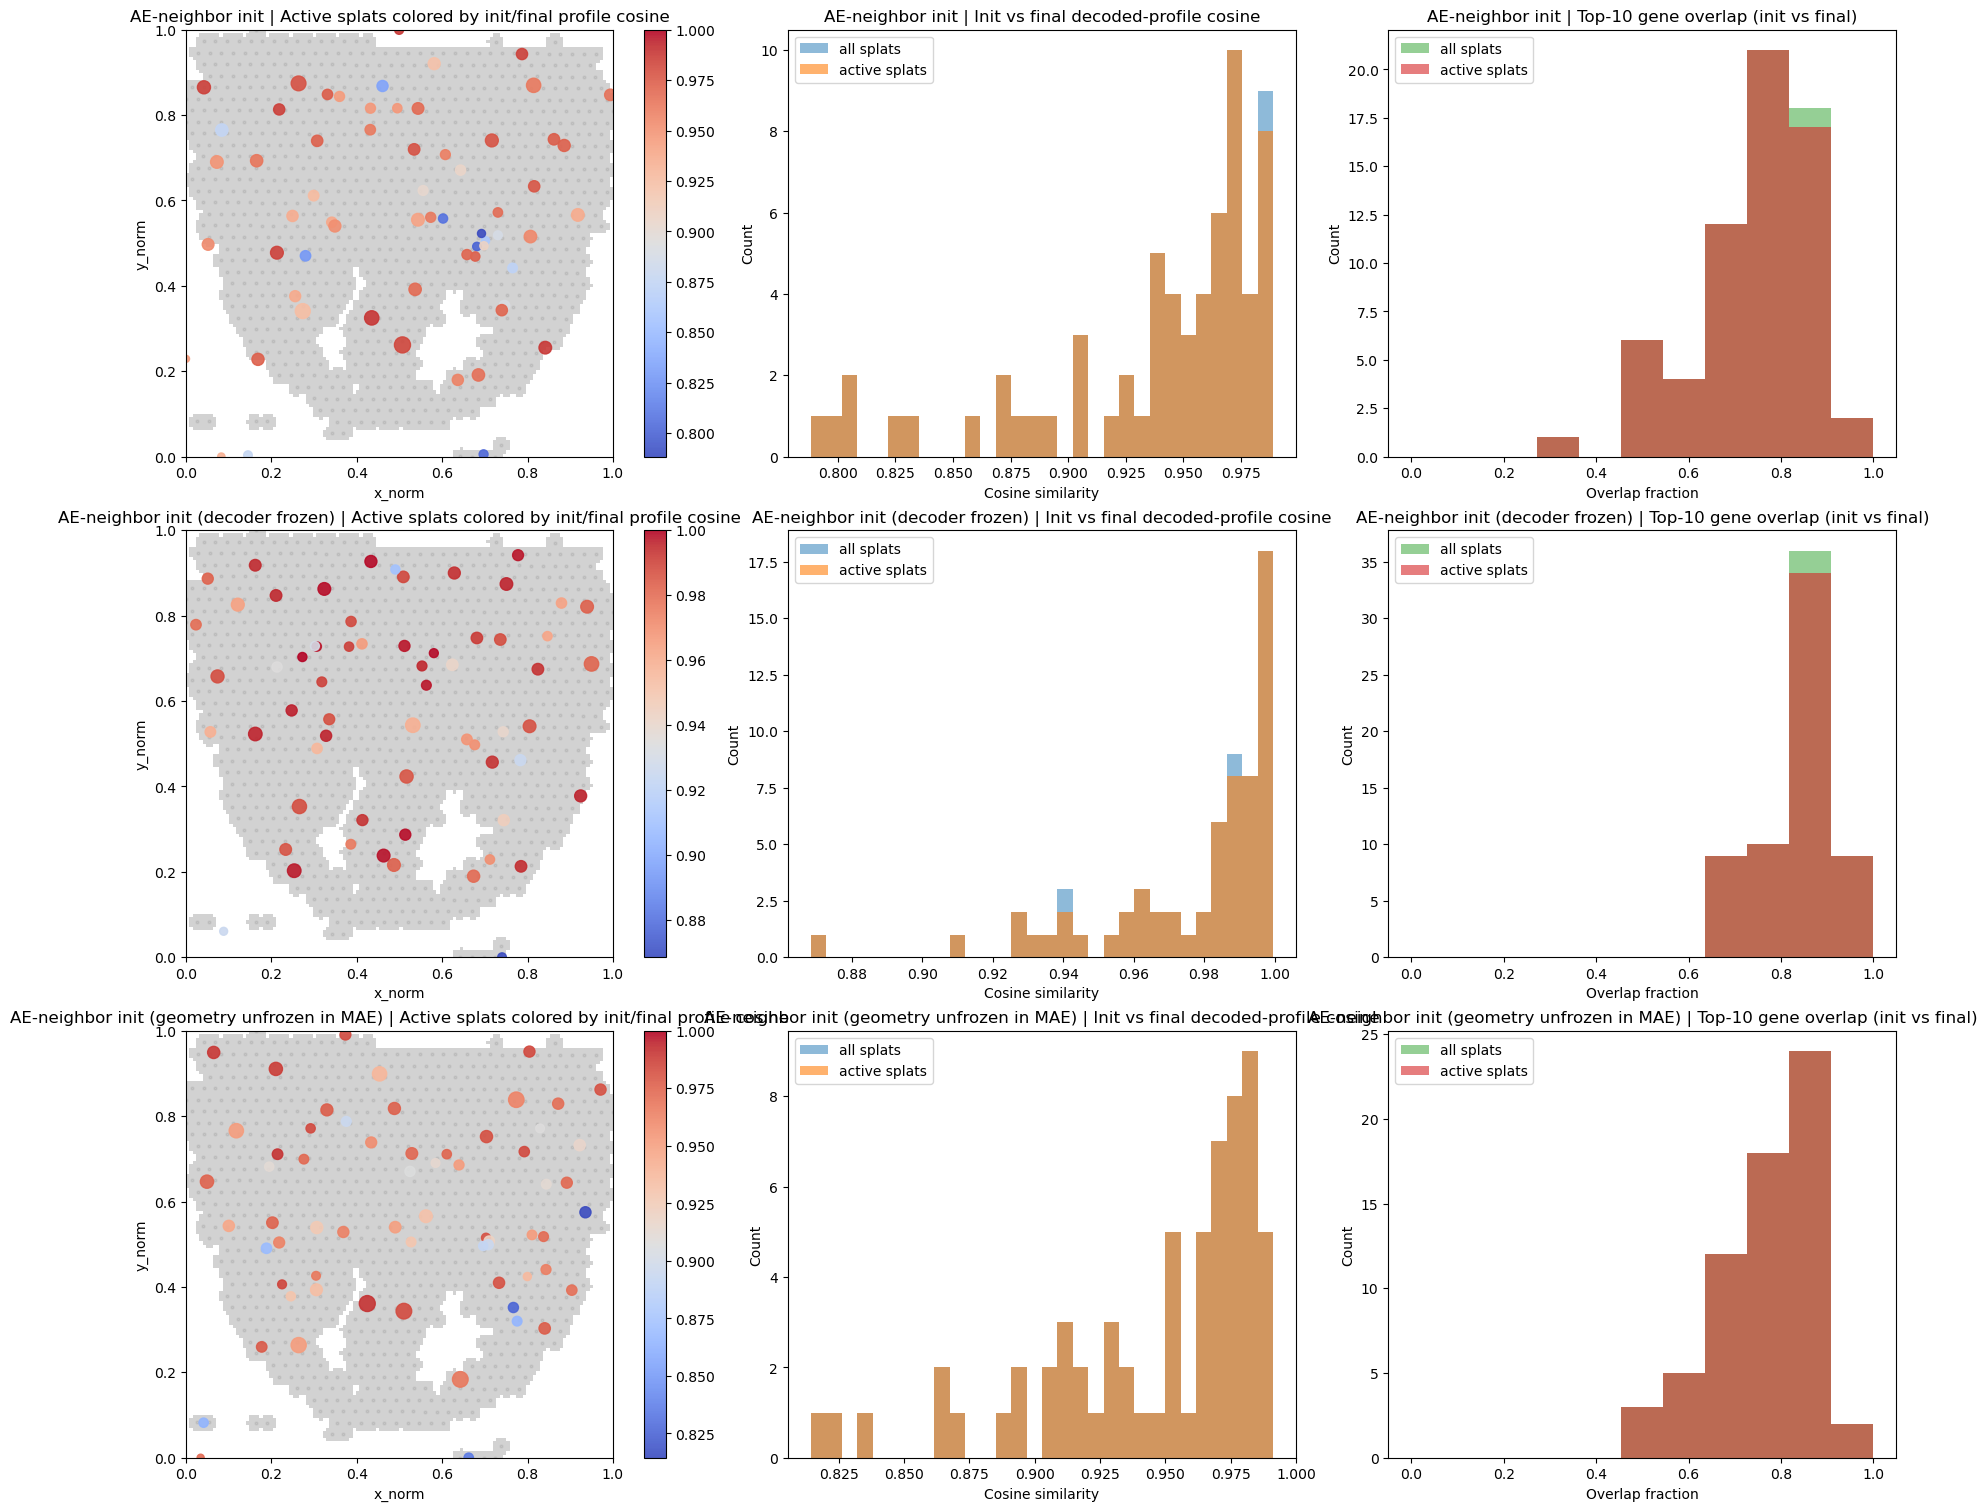

Program drift summary
{'AE-neighbor init': {'active_splats': 63, 'mean_profile_cosine_all': 0.9378, 'median_profile_cosine_all': 0.9569, 'mean_profile_cosine_active': 0.937, 'median_profile_cosine_active': 0.9557, 'mean_top10_overlap_all': 0.7672, 'median_top10_overlap_all': 0.8, 'mean_top10_overlap_active': 0.7651, 'median_top10_overlap_active': 0.8, 'program_geometry_corr_active': 0.5336}, 'AE-neighbor init (decoder frozen)': {'active_splats': 62, 'mean_profile_cosine_all': 0.9772, 'median_profile_cosine_all': 0.9879, 'mean_profile_cosine_active': 0.9776, 'median_profile_cosine_active': 0.9879, 'mean_top10_overlap_all': 0.8703, 'median_top10_overlap_all': 0.9, 'mean_top10_overlap_active': 0.8694, 'median_top10_overlap_active': 0.9, 'program_geometry_corr_active': 0.6525}, 'AE-neighbor init (geometry unfrozen in MAE)': {'active_splats': 64, 'mean_profile_cosine_all': 0.9463, 'median_profile_cosine_all': 0.9639, 'mean_profile_cosine_active': 0.9463, 'median_profile_cosine_active': 0.96

In [18]:
with torch.no_grad():
    init_gene_logits, _ = encoder_initialized_splat_model.decoder(encoder_initialized_splat_model.latents)
    init_profiles = torch.softmax(init_gene_logits, dim=1)

program_drift_models = [
    ('AE-neighbor init', ae_coarse_result['model']),
    ('AE-neighbor init (decoder frozen)', ae_frozen_coarse_result['model']),
    ('AE-neighbor init (geometry unfrozen in MAE)', ae_unfrozen_coarse_result['model']),
]

top_gene_k = min(10, num_genes)
program_drift_summary = {}
fig, axes = plt.subplots(len(program_drift_models), 3, figsize=(18, 5 * len(program_drift_models)), constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (label, model) in enumerate(program_drift_models):
    with torch.no_grad():
        final_gene_logits, _ = model.decoder(model.latents)
        final_profiles = torch.softmax(final_gene_logits, dim=1)
        init_norm = init_profiles / init_profiles.norm(dim=1, keepdim=True).clamp_min(1e-8)
        final_norm = final_profiles / final_profiles.norm(dim=1, keepdim=True).clamp_min(1e-8)
        profile_cosine = (init_norm * final_norm).sum(dim=1)
        mean_usage = compute_splat_weights(model, cell_features).mean(dim=0)
        active_mask = mean_usage > 1e-4

        init_top = torch.topk(init_profiles, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        final_top = torch.topk(final_profiles, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        top_overlap = np.array([
            len(set(init_top[i].tolist()) & set(final_top[i].tolist())) / float(top_gene_k)
            for i in range(init_top.shape[0])
        ], dtype=np.float64)

        active_idx = torch.nonzero(active_mask, as_tuple=False).squeeze(1)
        if active_idx.numel() >= 2:
            init_active = init_norm[active_idx]
            final_active = final_norm[active_idx]
            init_pairwise = (init_active @ init_active.T).detach().cpu().numpy()
            final_pairwise = (final_active @ final_active.T).detach().cpu().numpy()
            tri = np.triu_indices(init_pairwise.shape[0], k=1)
            if len(tri[0]) > 1 and np.std(init_pairwise[tri]) > 0 and np.std(final_pairwise[tri]) > 0:
                program_geometry_corr = float(np.corrcoef(init_pairwise[tri], final_pairwise[tri])[0, 1])
            else:
                program_geometry_corr = float('nan')
        else:
            program_geometry_corr = float('nan')

    profile_cosine_np = profile_cosine.detach().cpu().numpy()
    mean_usage_np = mean_usage.detach().cpu().numpy()
    active_np = active_mask.detach().cpu().numpy()
    means_np = model.means.detach().cpu().numpy()

    program_drift_summary[label] = {
        'active_splats': int(active_np.sum()),
        'mean_profile_cosine_all': float(np.mean(profile_cosine_np)),
        'median_profile_cosine_all': float(np.median(profile_cosine_np)),
        'mean_profile_cosine_active': float(np.mean(profile_cosine_np[active_np])) if active_np.any() else float('nan'),
        'median_profile_cosine_active': float(np.median(profile_cosine_np[active_np])) if active_np.any() else float('nan'),
        'mean_top10_overlap_all': float(np.mean(top_overlap)),
        'median_top10_overlap_all': float(np.median(top_overlap)),
        'mean_top10_overlap_active': float(np.mean(top_overlap[active_np])) if active_np.any() else float('nan'),
        'median_top10_overlap_active': float(np.median(top_overlap[active_np])) if active_np.any() else float('nan'),
        'program_geometry_corr_active': program_geometry_corr,
    }

    ax0 = axes[row, 0]
    ax0.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.18)
    ax0.scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=4, alpha=0.06, color='black')
    if active_np.any():
        sc0 = ax0.scatter(
            means_np[active_np, 0],
            means_np[active_np, 1],
            c=profile_cosine_np[active_np],
            s=25.0 + 2500.0 * np.clip(mean_usage_np[active_np], 0.0, None),
            cmap='coolwarm',
            alpha=0.9,
            vmin=max(0.0, float(np.nanmin(profile_cosine_np[active_np]))),
            vmax=1.0,
        )
        fig.colorbar(sc0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title(f'{label} | Active splats colored by init/final profile cosine')
    ax0.set_xlim(0, 1)
    ax0.set_ylim(0, 1)
    ax0.set_aspect('equal')
    ax0.set_xlabel('x_norm')
    ax0.set_ylabel('y_norm')

    ax1 = axes[row, 1]
    ax1.hist(profile_cosine_np, bins=30, alpha=0.5, label='all splats', color='tab:blue')
    if active_np.any():
        ax1.hist(profile_cosine_np[active_np], bins=30, alpha=0.6, label='active splats', color='tab:orange')
    ax1.set_title(f'{label} | Init vs final decoded-profile cosine')
    ax1.set_xlabel('Cosine similarity')
    ax1.set_ylabel('Count')
    ax1.legend()

    ax2 = axes[row, 2]
    ax2.hist(top_overlap, bins=np.linspace(0.0, 1.0, top_gene_k + 2), alpha=0.5, label='all splats', color='tab:green')
    if active_np.any():
        ax2.hist(top_overlap[active_np], bins=np.linspace(0.0, 1.0, top_gene_k + 2), alpha=0.6, label='active splats', color='tab:red')
    ax2.set_title(f'{label} | Top-{top_gene_k} gene overlap (init vs final)')
    ax2.set_xlabel('Overlap fraction')
    ax2.set_ylabel('Count')
    ax2.legend()

export_figure_axes(fig, fallback_prefix='program_drift')
plt.show()
print('Program drift summary')
print(format_for_display(program_drift_summary))


## Observed Maturity Analysis

Compute a simple marker-based maturity score on observed cells before interpreting the learned splat field.


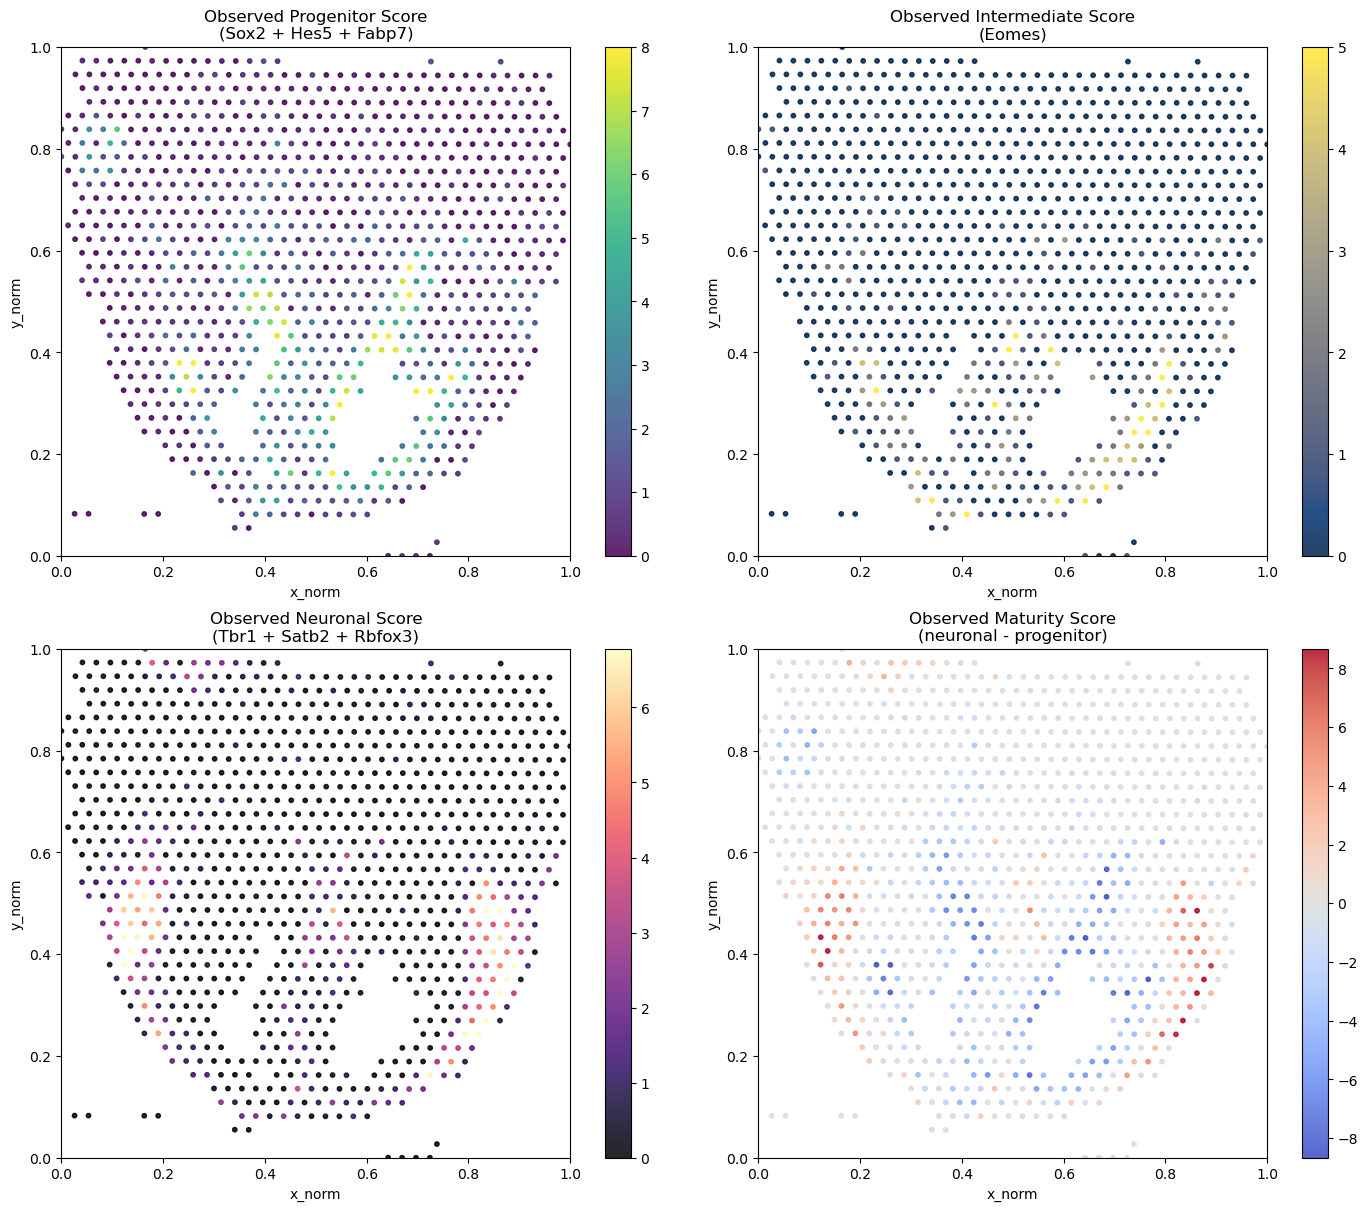

Observed-cell maturity markers
{'available_progenitor': ['Sox2', 'Hes5', 'Fabp7'], 'available_intermediate': ['Eomes'], 'available_neuronal': ['Tbr1', 'Satb2', 'Rbfox3'], 'missing_progenitor': [], 'missing_intermediate': [], 'missing_neuronal': [], 'sampled_cells': 984, 'maturity_summary': {'mean': -0.54, 'std': 2.516, 'min': -19.67, 'median': -0.3333, 'max': 15.67}}


In [19]:
progenitor_markers = ['Sox2', 'Hes5', 'Fabp7']
intermediate_markers = ['Eomes']
neuronal_markers = ['Tbr1', 'Satb2', 'Rbfox3']

available_progenitor = [g for g in progenitor_markers if g in gene_to_id]
available_intermediate = [g for g in intermediate_markers if g in gene_to_id]
available_neuronal = [g for g in neuronal_markers if g in gene_to_id]
missing_progenitor = [g for g in progenitor_markers if g not in gene_to_id]
missing_intermediate = [g for g in intermediate_markers if g not in gene_to_id]
missing_neuronal = [g for g in neuronal_markers if g not in gene_to_id]

if not available_progenitor or not available_neuronal:
    raise RuntimeError(
        f'Need at least one progenitor and one neuronal marker. '
        f'Available progenitor={available_progenitor}, available neuronal={available_neuronal}'
    )

prog_idx = torch.tensor([gene_to_id[g] for g in available_progenitor], device=cell_targets.device)
inter_idx = torch.tensor([gene_to_id[g] for g in available_intermediate], device=cell_targets.device) if available_intermediate else None
neur_idx = torch.tensor([gene_to_id[g] for g in available_neuronal], device=cell_targets.device)

observed_prog_score = cell_targets[:, prog_idx].float().mean(dim=1)
observed_intermediate_score = cell_targets[:, inter_idx].float().mean(dim=1) if inter_idx is not None else torch.zeros_like(observed_prog_score)
observed_neur_score = cell_targets[:, neur_idx].float().mean(dim=1)
observed_maturity_score = observed_neur_score - observed_prog_score

obs_xy = cell_features.detach().cpu().numpy()
prog_np = observed_prog_score.detach().cpu().numpy()
inter_np = observed_intermediate_score.detach().cpu().numpy()
neur_np = observed_neur_score.detach().cpu().numpy()
maturity_np = observed_maturity_score.detach().cpu().numpy()

sample_n = min(50000, len(obs_xy))
sample_idx = np.random.default_rng(0).choice(len(obs_xy), size=sample_n, replace=False)
sample_xy = obs_xy[sample_idx]
sample_prog = prog_np[sample_idx]
sample_inter = inter_np[sample_idx]
sample_neur = neur_np[sample_idx]
sample_maturity = maturity_np[sample_idx]

fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
axes = axes.reshape(-1)

prog_vmax = np.quantile(sample_prog, 0.99) if len(sample_prog) else 1.0
inter_vmax = np.quantile(sample_inter, 0.99) if len(sample_inter) else 1.0
neur_vmax = np.quantile(sample_neur, 0.99) if len(sample_neur) else 1.0
maturity_abs = np.quantile(np.abs(sample_maturity), 0.99) if len(sample_maturity) else 1.0
maturity_abs = max(float(maturity_abs), 1e-6)

sc0 = axes[0].scatter(sample_xy[:, 0], sample_xy[:, 1], c=sample_prog, s=10, cmap='viridis', vmin=0.0, vmax=prog_vmax, alpha=0.85)
axes[0].set_title(f'Observed Progenitor Score\n({" + ".join(available_progenitor)})')
fig.colorbar(sc0, ax=axes[0], fraction=0.046, pad=0.04)

sc1 = axes[1].scatter(sample_xy[:, 0], sample_xy[:, 1], c=sample_inter, s=10, cmap='cividis', vmin=0.0, vmax=inter_vmax, alpha=0.85)
axes[1].set_title(f'Observed Intermediate Score\n({" + ".join(available_intermediate) if available_intermediate else "none"})')
fig.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.04)

sc2 = axes[2].scatter(sample_xy[:, 0], sample_xy[:, 1], c=sample_neur, s=10, cmap='magma', vmin=0.0, vmax=neur_vmax, alpha=0.85)
axes[2].set_title(f'Observed Neuronal Score\n({" + ".join(available_neuronal)})')
fig.colorbar(sc2, ax=axes[2], fraction=0.046, pad=0.04)

sc3 = axes[3].scatter(sample_xy[:, 0], sample_xy[:, 1], c=sample_maturity, s=10, cmap='coolwarm', vmin=-maturity_abs, vmax=maturity_abs, alpha=0.85)
axes[3].set_title('Observed Maturity Score\n(neuronal - progenitor)')
fig.colorbar(sc3, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix='observed_maturity')
plt.show()

print('Observed-cell maturity markers')
print(format_for_display({
    'available_progenitor': available_progenitor,
    'available_intermediate': available_intermediate,
    'available_neuronal': available_neuronal,
    'missing_progenitor': missing_progenitor,
    'missing_intermediate': missing_intermediate,
    'missing_neuronal': missing_neuronal,
    'sampled_cells': int(sample_n),
    'maturity_summary': {
        'mean': float(maturity_np.mean()),
        'std': float(maturity_np.std()),
        'min': float(maturity_np.min()),
        'median': float(np.median(maturity_np)),
        'max': float(maturity_np.max()),
    },
}))


## Splat Reconstructed Maturity Field

Evaluate the trained AE-neighbor splat model on a dense grid and visualize the same marker programs as continuous tissue-masked fields.


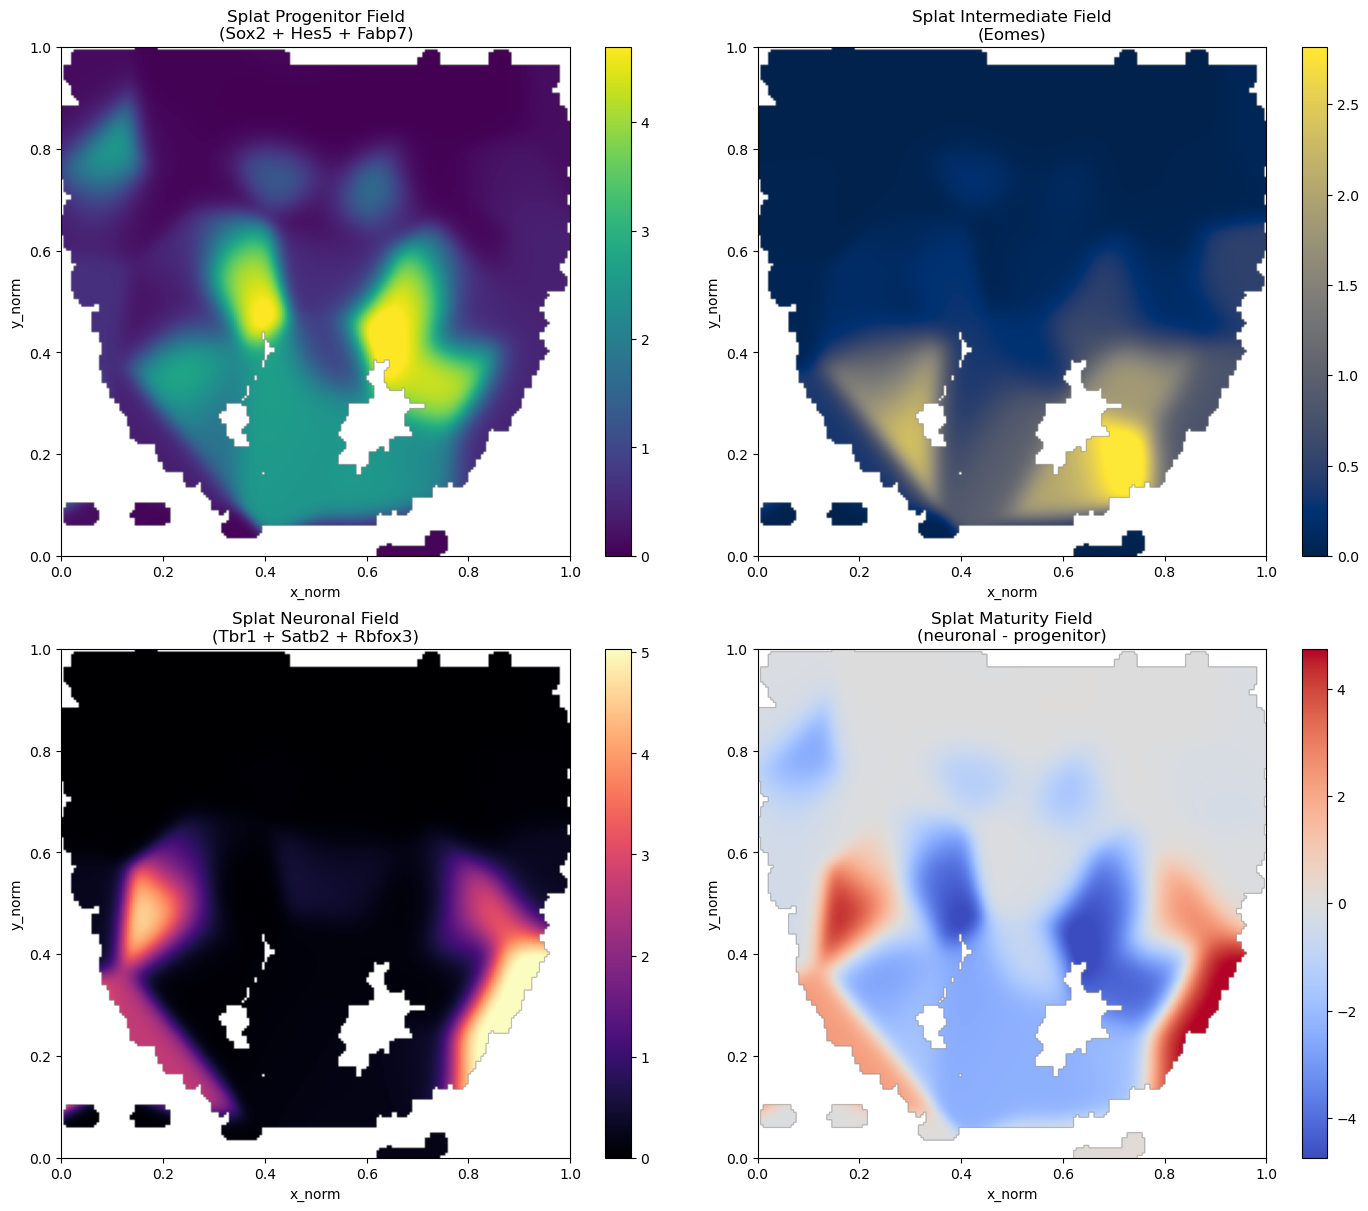

Splat-field maturity summary
{'grid_size': 200, 'grid_batch_size': 2048, 'grid_mask_threshold': 0.05, 'grid_mask_coverage': 0.7752, 'maturity_summary': {'mean': -0.6333, 'std': 1.654, 'min': -5.017, 'median': -0.2463, 'max': 4.902}}


In [20]:
grid_size = 200
grid_batch_size = 2048
grid_mask_threshold = 0.05
grid_x = torch.linspace(0.0, 1.0, grid_size, device=device)
grid_y = torch.linspace(0.0, 1.0, grid_size, device=device)
mesh_y, mesh_x = torch.meshgrid(grid_y, grid_x, indexing='ij')
grid_xy = torch.stack([mesh_x.reshape(-1), mesh_y.reshape(-1)], dim=1)

grid_prog_chunks = []
grid_inter_chunks = []
grid_neur_chunks = []
grid_model = ae_coarse_result['model']

with torch.no_grad():
    grid_mask_score = sample_tissue_support(grid_xy, tissue_mask_tensor).reshape(grid_size, grid_size).cpu().numpy()
    grid_mask_np = grid_mask_score > grid_mask_threshold
    for start in range(0, len(grid_xy), grid_batch_size):
        batch_xy = grid_xy[start:start + grid_batch_size]
        batch_log_rate = grid_model(batch_xy)
        batch_pred = torch.exp(batch_log_rate)
        grid_prog_chunks.append(batch_pred[:, prog_idx].float().mean(dim=1).cpu())
        if inter_idx is not None:
            grid_inter_chunks.append(batch_pred[:, inter_idx].float().mean(dim=1).cpu())
        else:
            grid_inter_chunks.append(torch.zeros(batch_pred.shape[0], dtype=torch.float32))
        grid_neur_chunks.append(batch_pred[:, neur_idx].float().mean(dim=1).cpu())
        del batch_log_rate
        del batch_pred
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

grid_prog_score = torch.cat(grid_prog_chunks, dim=0)
grid_inter_score = torch.cat(grid_inter_chunks, dim=0)
grid_neur_score = torch.cat(grid_neur_chunks, dim=0)
grid_maturity_score = grid_neur_score - grid_prog_score

grid_prog_np = grid_prog_score.reshape(grid_size, grid_size).numpy()
grid_inter_np = grid_inter_score.reshape(grid_size, grid_size).numpy()
grid_neur_np = grid_neur_score.reshape(grid_size, grid_size).numpy()
grid_maturity_np = grid_maturity_score.reshape(grid_size, grid_size).numpy()

grid_prog_masked = np.where(grid_mask_np, grid_prog_np, np.nan)
grid_inter_masked = np.where(grid_mask_np, grid_inter_np, np.nan)
grid_neur_masked = np.where(grid_mask_np, grid_neur_np, np.nan)
grid_maturity_masked = np.where(grid_mask_np, grid_maturity_np, np.nan)

def masked_q99(values, *, abs_values=False, fallback=1.0):
    valid = np.abs(values[np.isfinite(values)]) if abs_values else values[np.isfinite(values)]
    if valid.size == 0:
        return fallback
    q = float(np.quantile(valid, 0.99))
    return max(q, 1e-6)

fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
axes = axes.reshape(-1)

prog_vmax = masked_q99(grid_prog_masked)
inter_vmax = masked_q99(grid_inter_masked)
neur_vmax = masked_q99(grid_neur_masked)
maturity_abs = masked_q99(grid_maturity_masked, abs_values=True)

im0 = axes[0].imshow(grid_prog_masked, origin='lower', extent=[0, 1, 0, 1], cmap='viridis', vmin=0.0, vmax=prog_vmax)
axes[0].set_title(f'Splat Progenitor Field\n({" + ".join(available_progenitor)})')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(grid_inter_masked, origin='lower', extent=[0, 1, 0, 1], cmap='cividis', vmin=0.0, vmax=inter_vmax)
axes[1].set_title(f'Splat Intermediate Field\n({" + ".join(available_intermediate) if available_intermediate else "none"})')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(grid_neur_masked, origin='lower', extent=[0, 1, 0, 1], cmap='magma', vmin=0.0, vmax=neur_vmax)
axes[2].set_title(f'Splat Neuronal Field\n({" + ".join(available_neuronal)})')
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

im3 = axes[3].imshow(grid_maturity_masked, origin='lower', extent=[0, 1, 0, 1], cmap='coolwarm', vmin=-maturity_abs, vmax=maturity_abs)
axes[3].set_title('Splat Maturity Field\n(neuronal - progenitor)')
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix='splat_maturity_field')
plt.show()

valid_maturity = grid_maturity_masked[np.isfinite(grid_maturity_masked)]
print('Splat-field maturity summary')
print(format_for_display({
    'grid_size': int(grid_size),
    'grid_batch_size': int(grid_batch_size),
    'grid_mask_threshold': float(grid_mask_threshold),
    'grid_mask_coverage': float(grid_mask_np.mean()),
    'maturity_summary': {
        'mean': float(np.mean(valid_maturity)) if valid_maturity.size else float('nan'),
        'std': float(np.std(valid_maturity)) if valid_maturity.size else float('nan'),
        'min': float(np.min(valid_maturity)) if valid_maturity.size else float('nan'),
        'median': float(np.median(valid_maturity)) if valid_maturity.size else float('nan'),
        'max': float(np.max(valid_maturity)) if valid_maturity.size else float('nan'),
    },
}))


## Splat-Level Maturity Diagnostic

Score each active splat by the same progenitor/intermediate/neuronal markers and compare splat maturity against the reconstructed field maturity at splat centers.


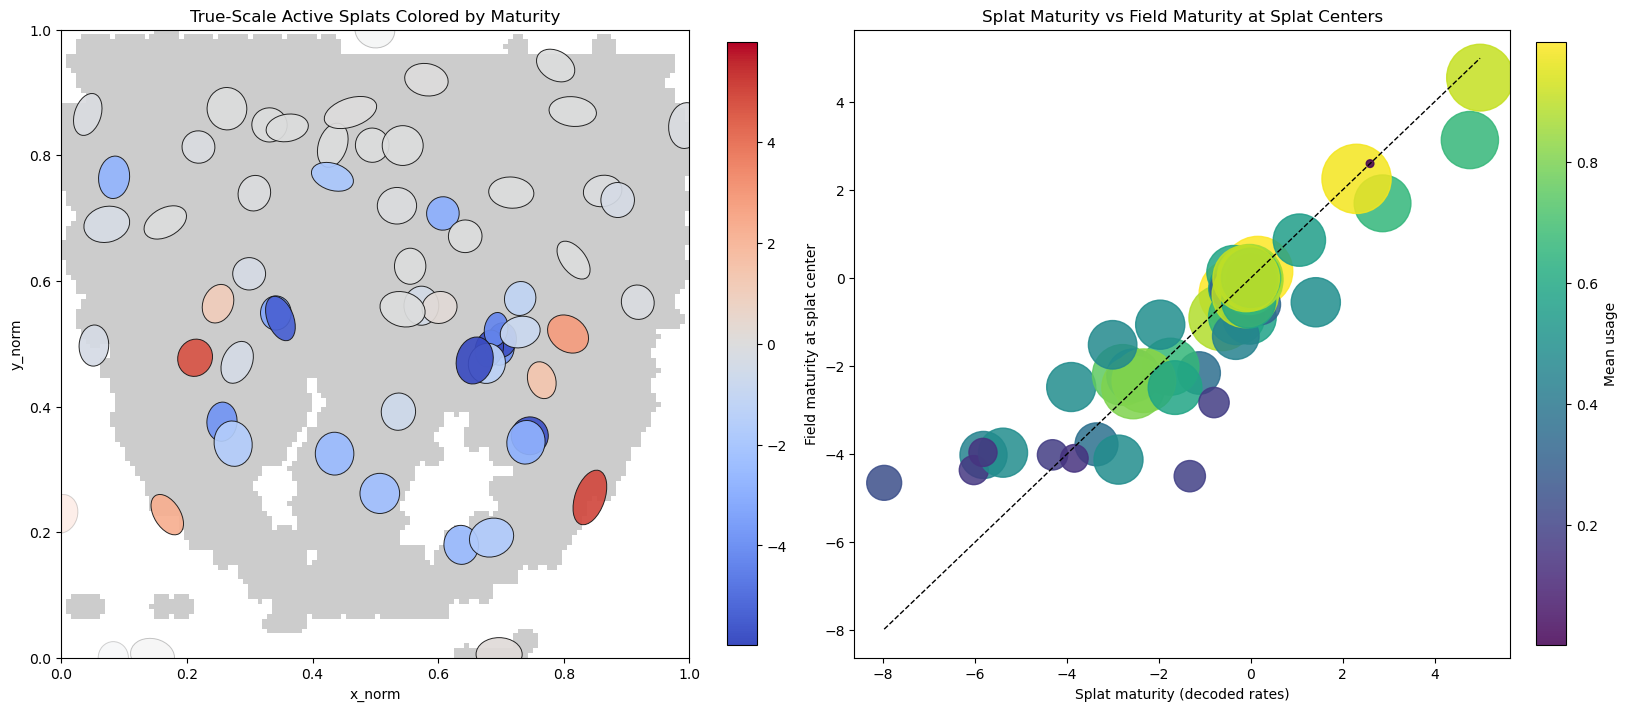

Splat-level maturity summary
{'active_splats': 63, 'available_progenitor': ['Sox2', 'Hes5', 'Fabp7'], 'available_intermediate': ['Eomes'], 'available_neuronal': ['Tbr1', 'Satb2', 'Rbfox3'], 'splat_maturity_rate_summary': {'mean': -0.8715, 'std': 2.317, 'min': -7.977, 'median': -0.1045, 'max': 4.984}, 'splat_maturity_composition_summary': {'mean': -0.0001535, 'std': 0.0003276, 'min': -0.0009541, 'median': -1.152e-05, 'max': 0.0004588}, 'field_maturity_at_centers_summary': {'mean': -0.9352, 'std': 1.884, 'min': -4.655, 'median': -0.2498, 'max': 4.543}, 'corr_splat_vs_field_maturity': 0.9169}


In [21]:
splat_maturity_query_idx = torch.randperm(len(cell_features), device=device)[:min(2048, len(cell_features))]
splat_maturity_queries = cell_features[splat_maturity_query_idx]
splat_maturity_model = ae_coarse_result['model']

with torch.no_grad():
    splat_maturity_weights = compute_splat_weights(splat_maturity_model, splat_maturity_queries)
    splat_mean_usage = splat_maturity_weights.mean(dim=0).detach().cpu().numpy()
    splat_full_usage = compute_splat_weights(splat_maturity_model, cell_features).detach().cpu().numpy()
    splat_active_mask = splat_mean_usage > 1e-4
    splat_active_idx = np.flatnonzero(splat_active_mask)

    splat_comp = splat_maturity_model.splat_composition().detach().cpu()
    splat_rates = splat_maturity_model.splat_rates().detach().cpu()
    splat_prog_score_comp = splat_comp[:, prog_idx.cpu()].float().mean(dim=1)
    if inter_idx is not None:
        splat_inter_score_comp = splat_comp[:, inter_idx.cpu()].float().mean(dim=1)
    else:
        splat_inter_score_comp = torch.zeros_like(splat_prog_score_comp)
    splat_neur_score_comp = splat_comp[:, neur_idx.cpu()].float().mean(dim=1)
    splat_maturity_score_comp = splat_neur_score_comp - splat_prog_score_comp

    splat_prog_score = splat_rates[:, prog_idx.cpu()].float().mean(dim=1)
    if inter_idx is not None:
        splat_inter_score = splat_rates[:, inter_idx.cpu()].float().mean(dim=1)
    else:
        splat_inter_score = torch.zeros_like(splat_prog_score)
    splat_neur_score = splat_rates[:, neur_idx.cpu()].float().mean(dim=1)
    splat_maturity_score = splat_neur_score - splat_prog_score

    center_log_rate = splat_maturity_model(splat_maturity_model.means)
    center_pred = torch.exp(center_log_rate)
    field_prog_at_centers = center_pred[:, prog_idx].float().mean(dim=1)
    if inter_idx is not None:
        field_inter_at_centers = center_pred[:, inter_idx].float().mean(dim=1)
    else:
        field_inter_at_centers = torch.zeros_like(field_prog_at_centers)
    field_neur_at_centers = center_pred[:, neur_idx].float().mean(dim=1)
    field_maturity_at_centers = field_neur_at_centers - field_prog_at_centers

    splat_means_np = splat_maturity_model.means.detach().cpu().numpy()
    splat_scales_xy_np = torch.exp(splat_maturity_model.log_scales).detach().cpu().numpy()
    splat_rotation_np = splat_maturity_model.rotation.detach().cpu().numpy().reshape(-1)

splat_prog_np = splat_prog_score.detach().cpu().numpy()
splat_inter_np = splat_inter_score.detach().cpu().numpy()
splat_neur_np = splat_neur_score.detach().cpu().numpy()
splat_maturity_np = splat_maturity_score.detach().cpu().numpy()
splat_prog_comp_np = splat_prog_score_comp.detach().cpu().numpy()
splat_inter_comp_np = splat_inter_score_comp.detach().cpu().numpy()
splat_neur_comp_np = splat_neur_score_comp.detach().cpu().numpy()
splat_maturity_comp_np = splat_maturity_score_comp.detach().cpu().numpy()
field_maturity_center_np = field_maturity_at_centers.detach().cpu().numpy()
splat_overlap_usage = np.zeros(len(splat_mean_usage), dtype=np.float64)
for splat_idx in splat_active_idx:
    dx = cell_points_np[:, 0] - splat_means_np[splat_idx, 0]
    dy = cell_points_np[:, 1] - splat_means_np[splat_idx, 1]
    theta = -float(splat_rotation_np[splat_idx])
    c, s = np.cos(theta), np.sin(theta)
    x_rot = c * dx - s * dy
    y_rot = s * dx + c * dy
    sx = max(float(splat_scales_xy_np[splat_idx, 0]), 1e-8)
    sy = max(float(splat_scales_xy_np[splat_idx, 1]), 1e-8)
    inside_mask = (x_rot / sx) ** 2 + (y_rot / sy) ** 2 <= 1.0
    if inside_mask.any():
        splat_overlap_usage[splat_idx] = float(splat_full_usage[inside_mask, splat_idx].mean())
    else:
        splat_overlap_usage[splat_idx] = float(splat_mean_usage[splat_idx])

if len(splat_active_idx) == 0:
    print('No active splats available for maturity diagnostic.')
else:
    active_splat_maturity = splat_maturity_np[splat_active_idx]
    active_splat_maturity_comp = splat_maturity_comp_np[splat_active_idx]
    active_field_maturity = field_maturity_center_np[splat_active_idx]
    active_usage = splat_overlap_usage[splat_active_idx]
    maturity_abs = np.quantile(np.abs(np.concatenate([active_splat_maturity, active_field_maturity])), 0.99) if len(active_splat_maturity) else 1.0
    maturity_abs = max(float(maturity_abs), 1e-6)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

    axes[0].imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    draw_order = np.argsort(active_usage)
    for rel_idx in draw_order:
        splat_idx = splat_active_idx[rel_idx]
        ellipse = Ellipse(
            xy=splat_means_np[splat_idx],
            width=2.0 * splat_scales_xy_np[splat_idx, 0],
            height=2.0 * splat_scales_xy_np[splat_idx, 1],
            angle=float(np.degrees(splat_rotation_np[splat_idx])),
            facecolor=plt.cm.coolwarm((splat_maturity_np[splat_idx] + maturity_abs) / (2.0 * maturity_abs)),
            edgecolor=(0.08, 0.08, 0.08, 0.95),
            linewidth=0.7,
            alpha=float(np.clip(0.18 + 12.0 * splat_overlap_usage[splat_idx], 0.18, 0.92)),
        )
        axes[0].add_patch(ellipse)
    axes[0].set_title('True-Scale Active Splats Colored by Maturity')
    axes[0].set_xlim(0, 1)
    axes[0].set_ylim(0, 1)
    axes[0].set_aspect('equal')
    axes[0].set_xlabel('x_norm')
    axes[0].set_ylabel('y_norm')
    sm = plt.cm.ScalarMappable(cmap='coolwarm', norm=plt.Normalize(vmin=-maturity_abs, vmax=maturity_abs))
    sm.set_array([])
    fig.colorbar(sm, ax=axes[0], fraction=0.046, pad=0.04)

    sc = axes[1].scatter(
        active_splat_maturity,
        active_field_maturity,
        c=active_usage,
        s=30.0 + 2500.0 * np.clip(active_usage, 0.0, None),
        cmap='viridis',
        alpha=0.85,
    )
    lo = float(min(active_splat_maturity.min(), active_field_maturity.min()))
    hi = float(max(active_splat_maturity.max(), active_field_maturity.max()))
    axes[1].plot([lo, hi], [lo, hi], linestyle='--', color='black', linewidth=1.0)
    axes[1].set_title('Splat Maturity vs Field Maturity at Splat Centers')
    axes[1].set_xlabel('Splat maturity (decoded rates)')
    axes[1].set_ylabel('Field maturity at splat center')
    fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04, label='Mean usage')
    export_figure_axes(fig, fallback_prefix='maturity_splat_diagnostic')
    plt.show()

    maturity_alignment = float(np.corrcoef(active_splat_maturity, active_field_maturity)[0, 1]) if len(active_splat_maturity) > 1 else float('nan')
    print('Splat-level maturity summary')
    print(format_for_display({
        'active_splats': int(len(splat_active_idx)),
        'available_progenitor': available_progenitor,
        'available_intermediate': available_intermediate,
        'available_neuronal': available_neuronal,
        'splat_maturity_rate_summary': {
            'mean': float(active_splat_maturity.mean()),
            'std': float(active_splat_maturity.std()),
            'min': float(active_splat_maturity.min()),
            'median': float(np.median(active_splat_maturity)),
            'max': float(active_splat_maturity.max()),
        },
        'splat_maturity_composition_summary': {
            'mean': float(active_splat_maturity_comp.mean()),
            'std': float(active_splat_maturity_comp.std()),
            'min': float(active_splat_maturity_comp.min()),
            'median': float(np.median(active_splat_maturity_comp)),
            'max': float(active_splat_maturity_comp.max()),
        },
        'field_maturity_at_centers_summary': {
            'mean': float(active_field_maturity.mean()),
            'std': float(active_field_maturity.std()),
            'min': float(active_field_maturity.min()),
            'median': float(np.median(active_field_maturity)),
            'max': float(active_field_maturity.max()),
        },
        'corr_splat_vs_field_maturity': maturity_alignment,
    }))


## Cellular Program Analysis

Cluster the active decoded splat programs from the AE-neighbor model and visualize their spatial arrangement, amplitude, and true-scale support.


AE-neighbor active splats for program clustering: 63 / 64
Per-Splat Amplitudes
{'all_splats': {'mean': 8873.0, 'std': 3891.0, 'min': 2350.0, 'median': 8017.0, 'q90': 14270.0, 'q99': 18910.0, 'max': 21700.0}, 'active_splats': {'mean': 8798.0, 'std': 3875.0, 'min': 2350.0, 'median': 7954.0, 'q90': 14280.0, 'q99': 18960.0, 'max': 21700.0}, 'corr_mean_usage_vs_total_intensity': -0.0548, 'corr_peak_usage_vs_total_intensity': -0.05462}


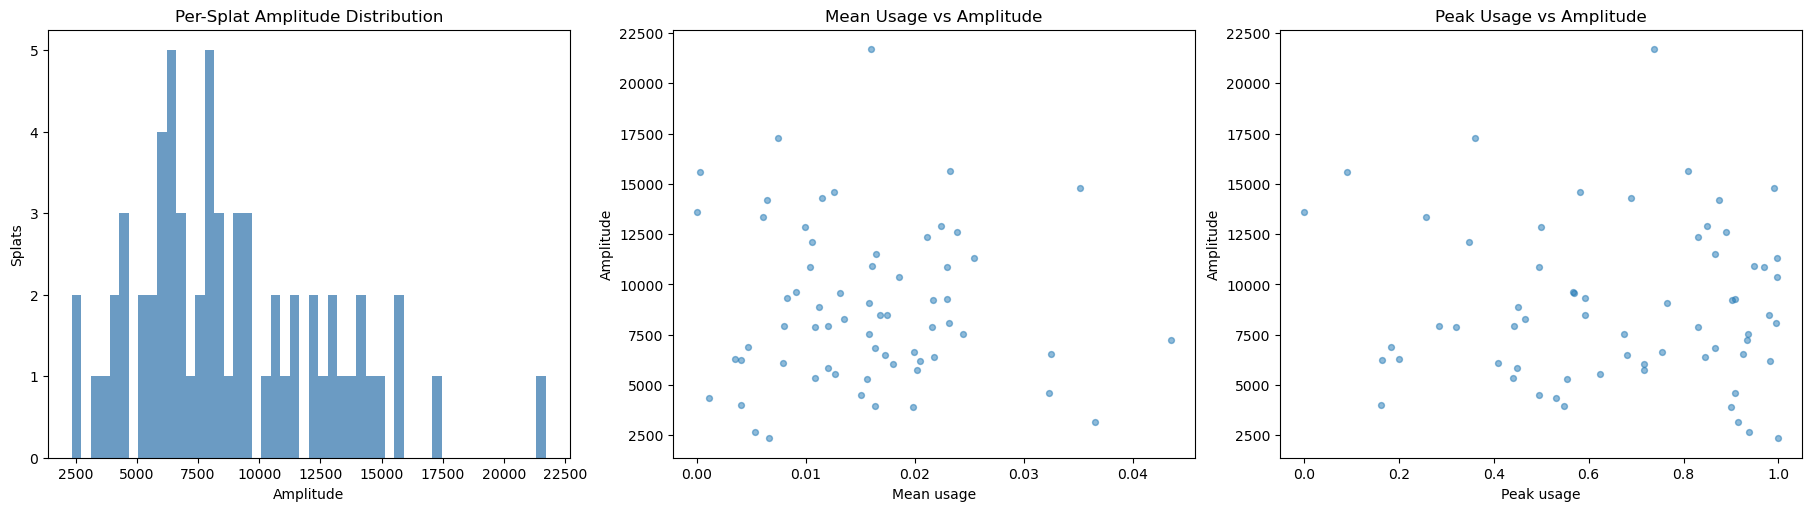

{'chosen_k': 8}


/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


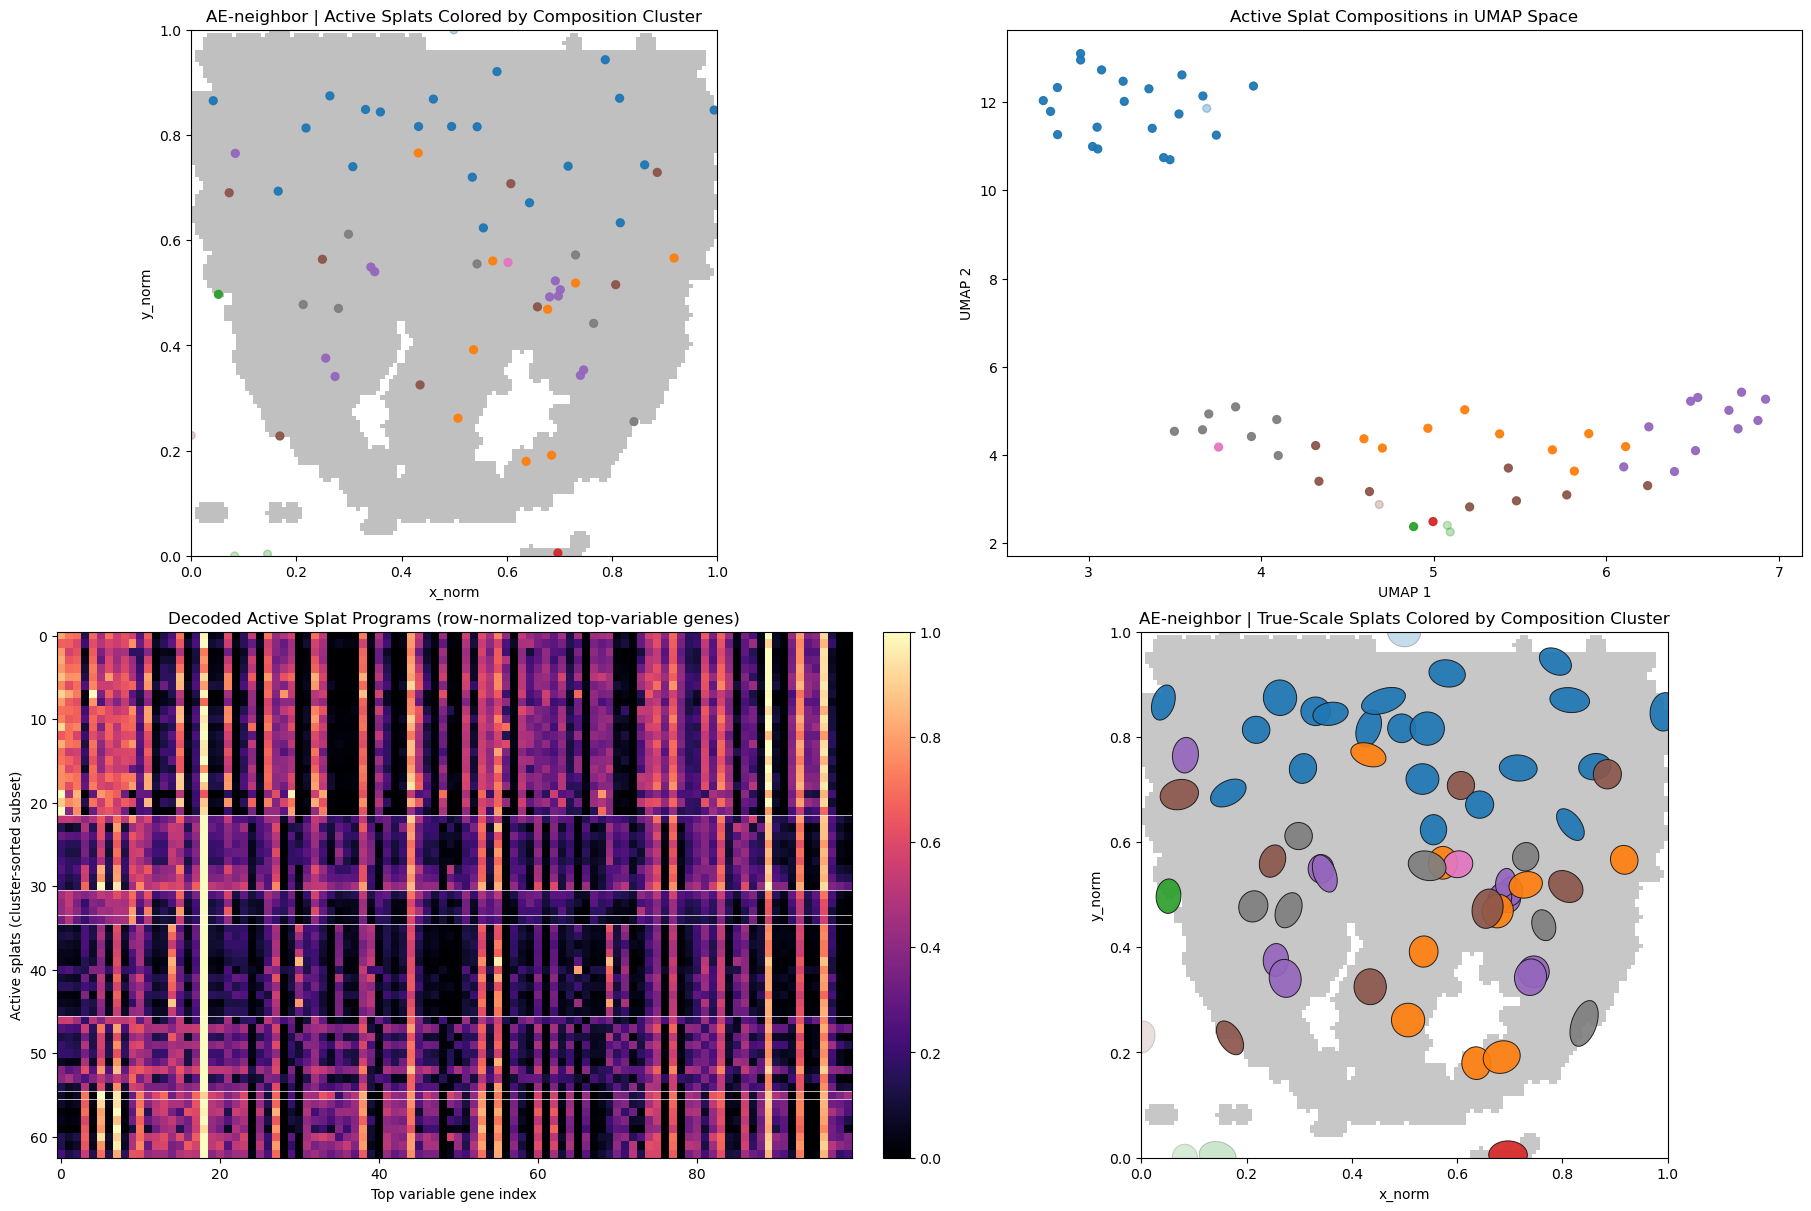

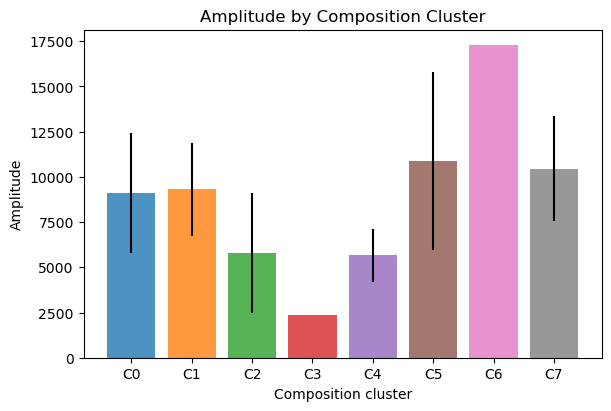

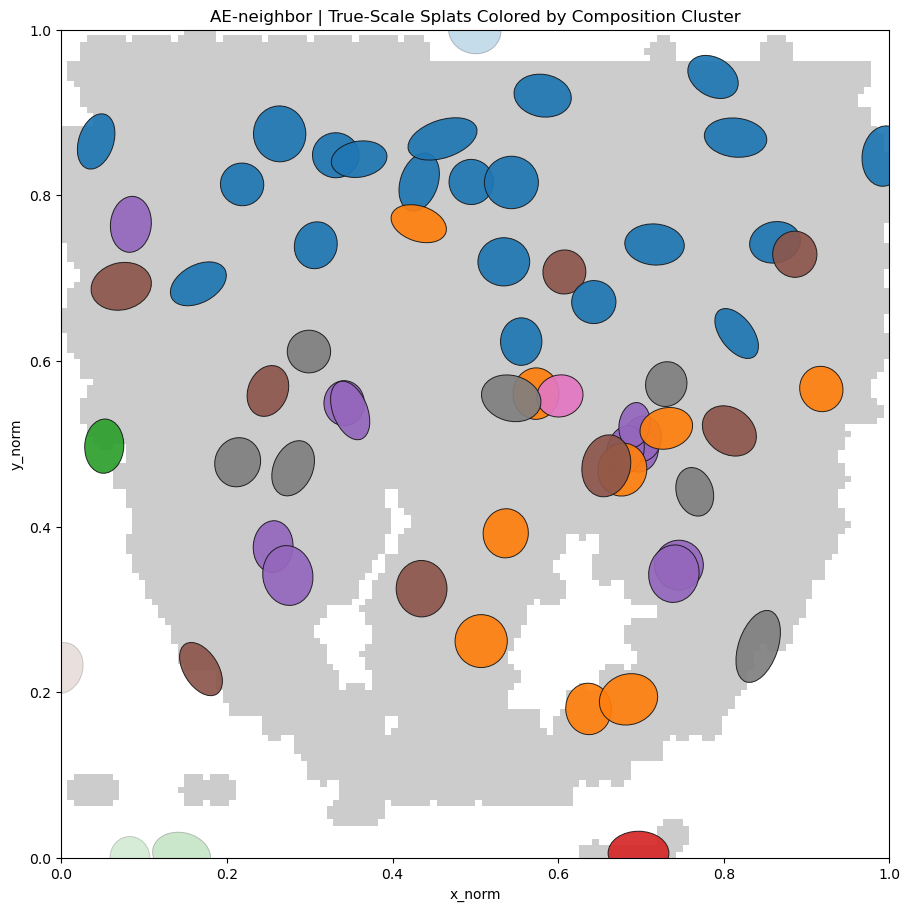

Shared Program Clusters (composition-based)
{'cluster_0': {'n_splats': 22, 'mean_usage': 0.01714, 'mean_opacity': 0.4922, 'mean_amplitude': 9110.0, 'top_genes_by_composition': ['Eef1a1', 'mt-Co1', 'mt-Co3', 'Gm42418', 'Actb']}, 'cluster_1': {'n_splats': 9, 'mean_usage': 0.01812, 'mean_opacity': 0.4977, 'mean_amplitude': 9302.0, 'top_genes_by_composition': ['Gm42418', 'mt-Co1', 'mt-Co3', 'mt-Atp6', 'Eef1a1']}, 'cluster_2': {'n_splats': 3, 'mean_usage': 0.008341, 'mean_opacity': 0.4833, 'mean_amplitude': 5807.0, 'top_genes_by_composition': ['Gm42418', 'Lars2', 'mt-Co1', 'Hbb-y', 'mt-Co3']}, 'cluster_3': {'n_splats': 1, 'mean_usage': 0.006644, 'mean_opacity': 0.5229, 'mean_amplitude': 2350.0, 'top_genes_by_composition': ['Gm42418', 'Lars2', 'mt-Co1', 'mt-Co2', 'mt-Co3']}, 'cluster_4': {'n_splats': 11, 'mean_usage': 0.01375, 'mean_opacity': 0.5143, 'mean_amplitude': 5655.0, 'top_genes_by_composition': ['Gm42418', 'Eef1a1', 'mt-Co1', 'Ptma', 'Actb']}, 'cluster_5': {'n_splats': 9, 'mean_usag

In [22]:
program_usage_query_idx = torch.randperm(len(cell_features), device=device)[:min(2048, len(cell_features))]
program_queries = cell_features[program_usage_query_idx]
program_model = ae_coarse_result['model']
program_label = 'AE-neighbor'
program_n_clusters = min(8, splat_cfg.num_splats)

with torch.no_grad():
    program_weights = compute_splat_weights(program_model, program_queries)
    program_mean_usage = program_weights.mean(dim=0).detach().cpu().numpy()
    program_peak_usage = program_weights.max(dim=0).values.detach().cpu().numpy()
    program_full_weights = compute_splat_weights(program_model, cell_features).detach().cpu().numpy()

    gene_logits, _ = program_model.decoder(program_model.latents)
    program_composition = torch.softmax(gene_logits, dim=-1).detach().cpu().numpy()
    program_total_intensity = program_model.splat_amplitudes().detach().cpu().numpy().reshape(-1)
    program_rates = program_total_intensity[:, None] * program_composition

    program_means = program_model.means.detach().cpu().numpy()
    program_scales_xy = torch.exp(program_model.log_scales).detach().cpu().numpy()
    program_scales = program_scales_xy.mean(axis=1)
    program_rotation = program_model.rotation.detach().cpu().numpy().reshape(-1)
    program_opacity = torch.sigmoid(program_model.opacity_logits).squeeze(-1).detach().cpu().numpy()

active_mask = program_mean_usage > 1e-4
active_idx = np.flatnonzero(active_mask)
program_overlap_usage = np.zeros(len(program_mean_usage), dtype=np.float64)
program_overlap_counts = np.zeros(len(program_mean_usage), dtype=np.int64)
for splat_idx in active_idx:
    dx = cell_points_np[:, 0] - program_means[splat_idx, 0]
    dy = cell_points_np[:, 1] - program_means[splat_idx, 1]
    theta = -float(program_rotation[splat_idx])
    c, s = np.cos(theta), np.sin(theta)
    x_rot = c * dx - s * dy
    y_rot = s * dx + c * dy
    sx = max(float(program_scales_xy[splat_idx, 0]), 1e-8)
    sy = max(float(program_scales_xy[splat_idx, 1]), 1e-8)
    inside_mask = (x_rot / sx) ** 2 + (y_rot / sy) ** 2 <= 1.0
    program_overlap_counts[splat_idx] = int(inside_mask.sum())
    if inside_mask.any():
        program_overlap_usage[splat_idx] = float(program_full_weights[inside_mask, splat_idx].mean())
    else:
        program_overlap_usage[splat_idx] = float(program_mean_usage[splat_idx])
print(f'{program_label} active splats for program clustering: {len(active_idx)} / {len(program_mean_usage)}')

program_amplitude_summary = {
    'all_splats': {
        'mean': float(program_total_intensity.mean()),
        'std': float(program_total_intensity.std()),
        'min': float(program_total_intensity.min()),
        'median': float(np.median(program_total_intensity)),
        'q90': float(np.quantile(program_total_intensity, 0.90)),
        'q99': float(np.quantile(program_total_intensity, 0.99)),
        'max': float(program_total_intensity.max()),
    },
    'active_splats': {
        'mean': float(program_total_intensity[active_idx].mean()) if len(active_idx) else float('nan'),
        'std': float(program_total_intensity[active_idx].std()) if len(active_idx) else float('nan'),
        'min': float(program_total_intensity[active_idx].min()) if len(active_idx) else float('nan'),
        'median': float(np.median(program_total_intensity[active_idx])) if len(active_idx) else float('nan'),
        'q90': float(np.quantile(program_total_intensity[active_idx], 0.90)) if len(active_idx) else float('nan'),
        'q99': float(np.quantile(program_total_intensity[active_idx], 0.99)) if len(active_idx) else float('nan'),
        'max': float(program_total_intensity[active_idx].max()) if len(active_idx) else float('nan'),
    },
    'corr_mean_usage_vs_total_intensity': float(np.corrcoef(program_mean_usage, program_total_intensity)[0, 1]) if len(program_mean_usage) > 1 else float('nan'),
    'corr_peak_usage_vs_total_intensity': float(np.corrcoef(program_peak_usage, program_total_intensity)[0, 1]) if len(program_peak_usage) > 1 else float('nan'),
}
print('Per-Splat Amplitudes')
print(format_for_display(program_amplitude_summary))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes[0].hist(program_total_intensity, bins=50, color='steelblue', alpha=0.8)
axes[0].set_title('Per-Splat Amplitude Distribution')
axes[0].set_xlabel('Amplitude')
axes[0].set_ylabel('Splats')

axes[1].scatter(program_mean_usage, program_total_intensity, s=18, alpha=0.5)
axes[1].set_title('Mean Usage vs Amplitude')
axes[1].set_xlabel('Mean usage')
axes[1].set_ylabel('Amplitude')

axes[2].scatter(program_peak_usage, program_total_intensity, s=18, alpha=0.5)
axes[2].set_title('Peak Usage vs Amplitude')
axes[2].set_xlabel('Peak usage')
axes[2].set_ylabel('Amplitude')
export_figure_axes(fig, fallback_prefix='program_amplitudes')
plt.show()

if len(active_idx) < 3:
    print('Not enough active splats to cluster decoded programs.')
else:
    from sklearn.cluster import KMeans
    from sklearn.decomposition import PCA

    active_compositions = program_composition[active_idx]
    active_log_rates = np.log1p(program_rates[active_idx])
    active_intensity = program_total_intensity[active_idx]
    n_clusters = min(program_n_clusters, len(active_idx))
    if n_clusters < 2:
        n_clusters = 2

    print(format_for_display({'chosen_k': int(n_clusters)}))
    program_clusters = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit_predict(active_compositions)

    try:
        import umap
        reducer = umap.UMAP(n_components=2, random_state=0)
        embedding = reducer.fit_transform(active_compositions)
        embedding_label = 'UMAP'
    except ImportError:
        reducer = PCA(n_components=2, random_state=0)
        embedding = reducer.fit_transform(active_compositions)
        embedding_label = 'PCA fallback (umap-learn not installed)'

    cluster_top = {}
    for cluster_id in range(n_clusters):
        cluster_mean = active_compositions[program_clusters == cluster_id].mean(axis=0)
        top_idx = np.argsort(cluster_mean)[-5:][::-1]
        cluster_top[cluster_id] = [gene_list[i] for i in top_idx]

    cluster_colors = plt.cm.tab10(np.arange(n_clusters) % 10)
    point_colors = cluster_colors[program_clusters]
    scatter_size = 32.0
    scatter_alpha = np.clip(0.28 + 8.0 * program_overlap_usage[active_idx], 0.28, 0.95)

    fig, axes = plt.subplots(2, 2, figsize=(18, 12), constrained_layout=True)
    axes[0, 0].imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25)
    axes[0, 0].scatter(
        program_means[active_idx, 0],
        program_means[active_idx, 1],
        color=point_colors,
        s=scatter_size,
        alpha=scatter_alpha,
    )
    axes[0, 0].set_title(f'{program_label} | Active Splats Colored by Composition Cluster')
    axes[0, 0].set_xlim(0, 1)
    axes[0, 0].set_ylim(0, 1)
    axes[0, 0].set_aspect('equal')
    axes[0, 0].set_xlabel('x_norm')
    axes[0, 0].set_ylabel('y_norm')

    axes[0, 1].scatter(
        embedding[:, 0],
        embedding[:, 1],
        color=point_colors,
        s=scatter_size,
        alpha=scatter_alpha,
    )
    axes[0, 1].set_title(f'Active Splat Compositions in {embedding_label} Space')
    axes[0, 1].set_xlabel(f'{embedding_label} 1')
    axes[0, 1].set_ylabel(f'{embedding_label} 2')

    order = np.argsort(program_clusters)
    sample_cap = min(300, len(active_idx))
    show_order = order[:sample_cap]
    show_clusters = program_clusters[show_order]
    variable_gene_k = min(100, active_log_rates.shape[1])
    variable_gene_idx = np.argsort(active_log_rates.var(axis=0))[::-1][:variable_gene_k]
    show_programs = active_log_rates[show_order][:, variable_gene_idx]
    show_programs_row_norm = show_programs / np.clip(show_programs.max(axis=1, keepdims=True), 1e-8, None)
    im = axes[1, 0].imshow(show_programs_row_norm, aspect='auto', cmap='magma', vmin=0.0, vmax=1.0)
    axes[1, 0].set_title('Decoded Active Splat Programs (row-normalized top-variable genes)')
    axes[1, 0].set_xlabel('Top variable gene index')
    axes[1, 0].set_ylabel('Active splats (cluster-sorted subset)')
    cluster_breaks = np.where(np.diff(show_clusters) != 0)[0]
    for boundary in cluster_breaks:
        axes[1, 0].axhline(boundary + 0.5, color='white', linewidth=0.7, alpha=0.7)
    fig.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

    intensity_means = [active_intensity[program_clusters == cluster_id].mean() for cluster_id in range(n_clusters)]
    intensity_stds = [active_intensity[program_clusters == cluster_id].std() for cluster_id in range(n_clusters)]
    axes[1, 1].imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.22)
    draw_order = np.argsort(program_overlap_usage[active_idx]) if len(active_idx) else np.array([], dtype=np.int64)
    for local_pos in draw_order:
        splat_idx = active_idx[local_pos]
        cluster_id = program_clusters[local_pos]
        face_color = cluster_colors[cluster_id]
        ellipse = Ellipse(
            xy=program_means[splat_idx],
            width=2.0 * program_scales_xy[splat_idx, 0],
            height=2.0 * program_scales_xy[splat_idx, 1],
            angle=float(np.degrees(program_rotation[splat_idx])),
            facecolor=face_color,
            edgecolor=(0.08, 0.08, 0.08, 0.95),
            linewidth=0.7,
            alpha=float(np.clip(0.18 + 12.0 * program_overlap_usage[splat_idx], 0.18, 0.92)),
        )
        axes[1, 1].add_patch(ellipse)
    axes[1, 1].set_title(f'{program_label} | True-Scale Splats Colored by Composition Cluster')
    axes[1, 1].set_xlim(0, 1)
    axes[1, 1].set_ylim(0, 1)
    axes[1, 1].set_aspect('equal')
    axes[1, 1].set_xlabel('x_norm')
    axes[1, 1].set_ylabel('y_norm')
    export_figure_axes(fig, fallback_prefix='composition_cluster_panels')
    plt.show()

    fig_cluster_bar, ax_cluster_bar = plt.subplots(1, 1, figsize=(6, 4), constrained_layout=True)
    ax_cluster_bar.bar(np.arange(n_clusters), intensity_means, yerr=intensity_stds, color=cluster_colors, alpha=0.8)
    ax_cluster_bar.set_title('Amplitude by Composition Cluster')
    ax_cluster_bar.set_xlabel('Composition cluster')
    ax_cluster_bar.set_ylabel('Amplitude')
    ax_cluster_bar.set_xticks(np.arange(n_clusters))
    ax_cluster_bar.set_xticklabels([f'C{cluster_id}' for cluster_id in range(n_clusters)])
    export_figure_axes(fig_cluster_bar, fallback_prefix='amplitude_by_composition_cluster')
    plt.show()

    draw_order = np.argsort(program_overlap_usage[active_idx])
    fig, ax = plt.subplots(1, 1, figsize=(9, 9), constrained_layout=True)
    ax.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    for local_idx in draw_order:
        splat_idx = active_idx[local_idx]
        cluster_id = int(program_clusters[local_idx])
        ellipse = Ellipse(
            xy=program_means[splat_idx],
            width=2.0 * program_scales_xy[splat_idx, 0],
            height=2.0 * program_scales_xy[splat_idx, 1],
            angle=float(np.degrees(program_rotation[splat_idx])),
            facecolor=cluster_colors[cluster_id],
            edgecolor=(0.08, 0.08, 0.08, 0.95),
            linewidth=0.7,
            alpha=float(np.clip(0.18 + 12.0 * program_overlap_usage[splat_idx], 0.18, 0.92)),
        )
        ax.add_patch(ellipse)
    ax.set_title(f'{program_label} | True-Scale Splats Colored by Composition Cluster')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')
    export_figure_axes(fig, fallback_prefix='true_scale_cluster')
    plt.show()

    print('Shared Program Clusters (composition-based)')
    cluster_program_summary = {}
    for cluster_id in range(n_clusters):
        cluster_mask = program_clusters == cluster_id
        cluster_program_summary[f'cluster_{cluster_id}'] = {
            'n_splats': int(cluster_mask.sum()),
            'mean_usage': float(program_mean_usage[active_idx][cluster_mask].mean()),
            'mean_opacity': float(program_opacity[active_idx][cluster_mask].mean()),
            'mean_amplitude': float(active_intensity[cluster_mask].mean()),
            'top_genes_by_composition': cluster_top[cluster_id],
        }
    print(format_for_display(cluster_program_summary))


## Baseline Comparison Analysis

Compare the AE-neighbor splat model against the trained baselines using the same spatial and per-cell diagnostics used in the modular amplitude notebooks.


Comparison Gene: Eomes
Edge vs Interior Error
AE-neighbor splat {'edge_thresh': 0.04282, 'interior_thresh': 0.1541, 'edge_mae': 0.2066, 'interior_mae': 0.2378, 'overall_mae': 0.2232, 'edge_n': 25, 'interior_n': 25}
AE-neighbor splat {'active_n': 22, 'inactive_n': 77, 'active_true_mean': 1.591, 'inactive_true_mean': 0.0, 'active_signed_error_mean': -0.4865, 'inactive_signed_error_mean': 0.1913, 'active_abs_error_mean': 1.186, 'inactive_abs_error_mean': 0.1913}
MLP-MAE {'edge_thresh': 0.04282, 'interior_thresh': 0.1541, 'edge_mae': 0.2209, 'interior_mae': 0.2485, 'overall_mae': 0.2365, 'edge_n': 25, 'interior_n': 25}
MLP-MAE {'active_n': 22, 'inactive_n': 77, 'active_true_mean': 1.591, 'inactive_true_mean': 0.0, 'active_signed_error_mean': -1.591, 'inactive_signed_error_mean': 8.183e-05, 'active_abs_error_mean': 1.591, 'inactive_abs_error_mean': 8.183e-05}
MLP (Bio Objective) {'edge_thresh': 0.04282, 'interior_thresh': 0.1541, 'edge_mae': 0.2244, 'interior_mae': 0.2441, 'overall_mae': 0.

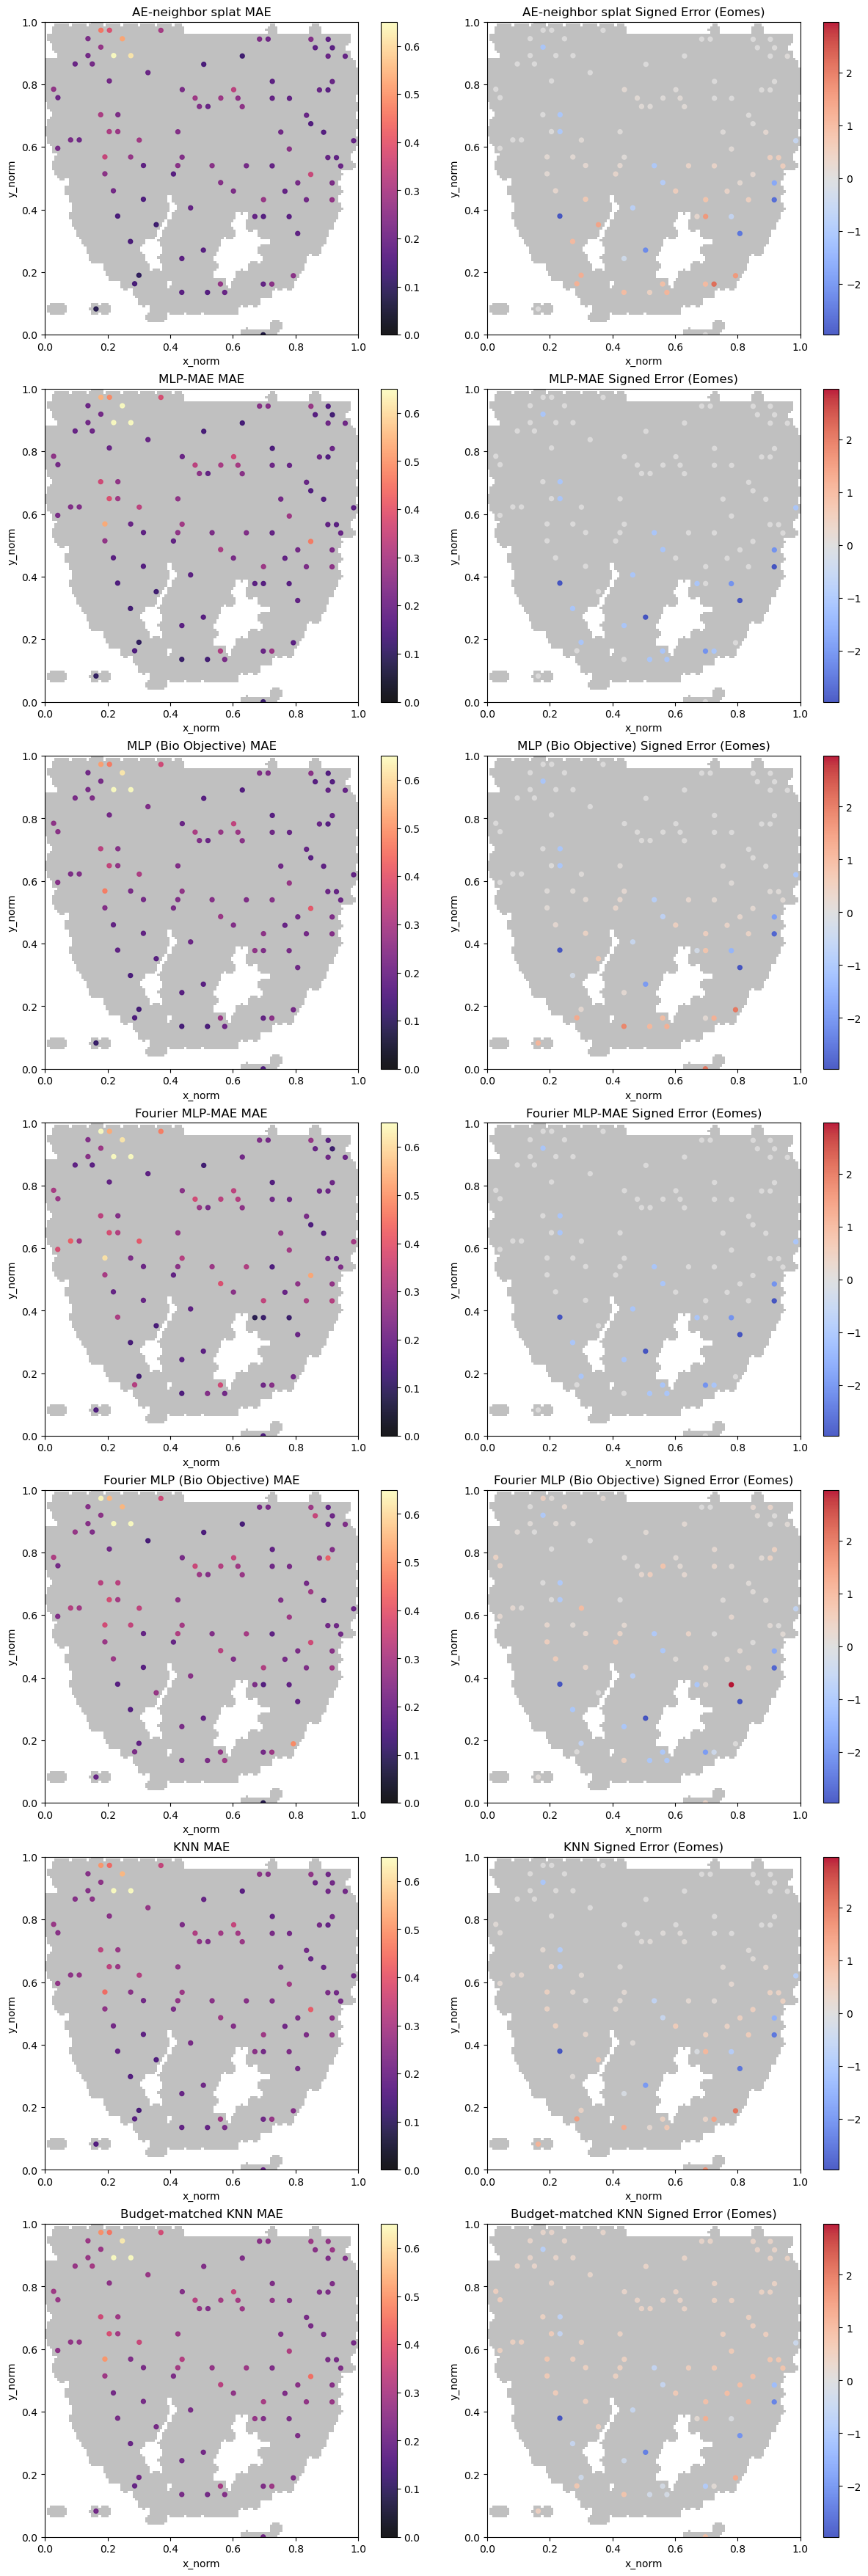

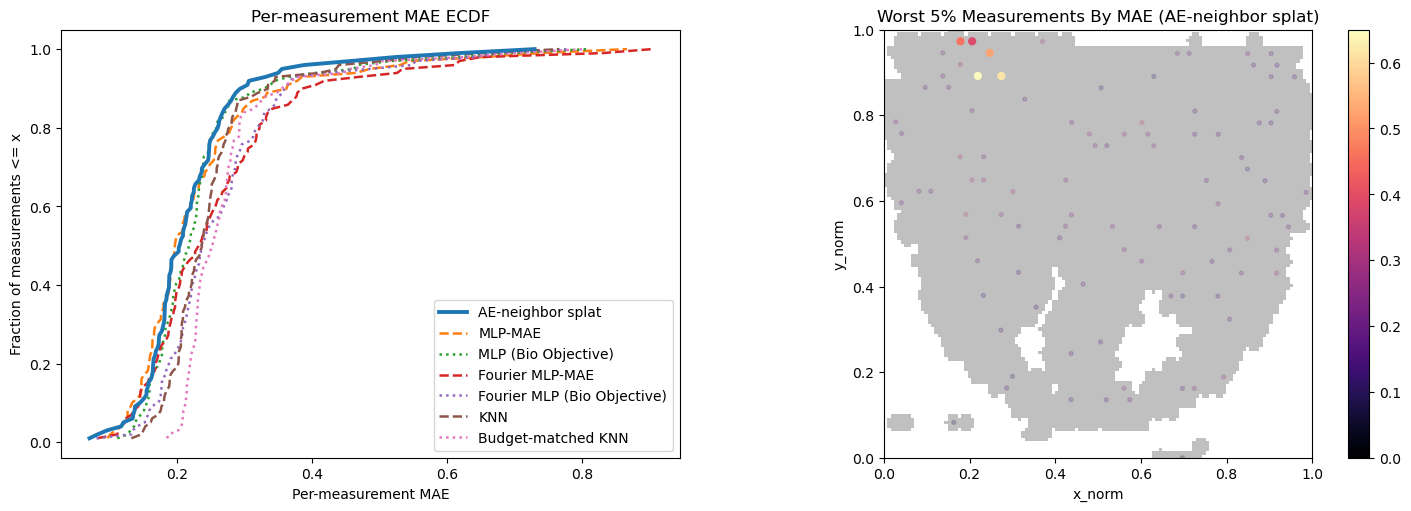

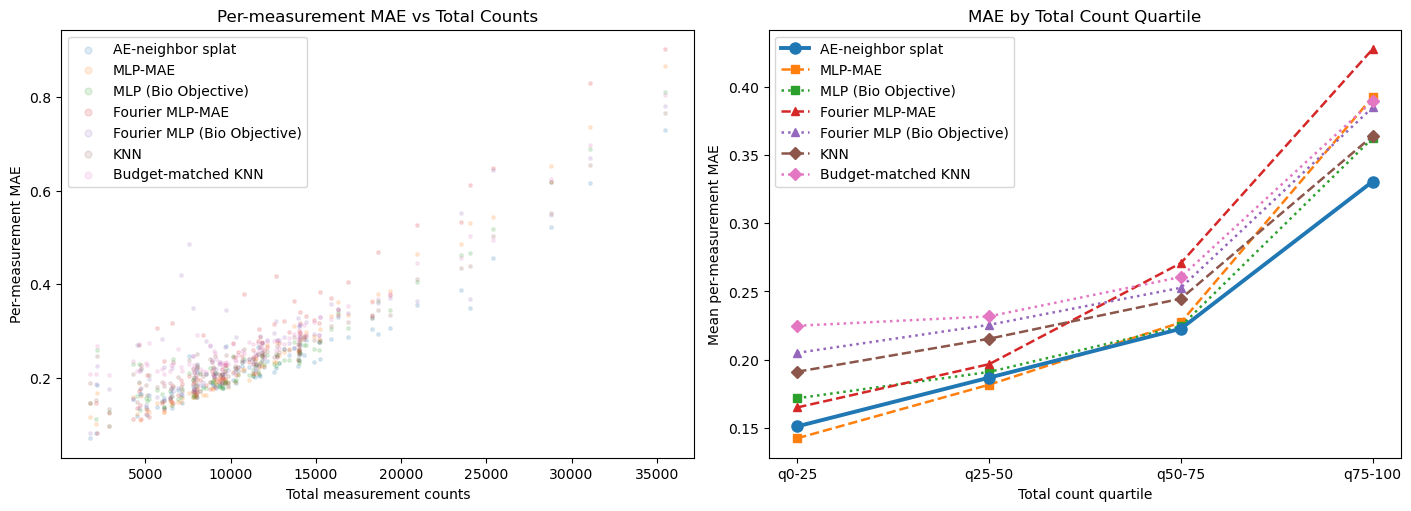

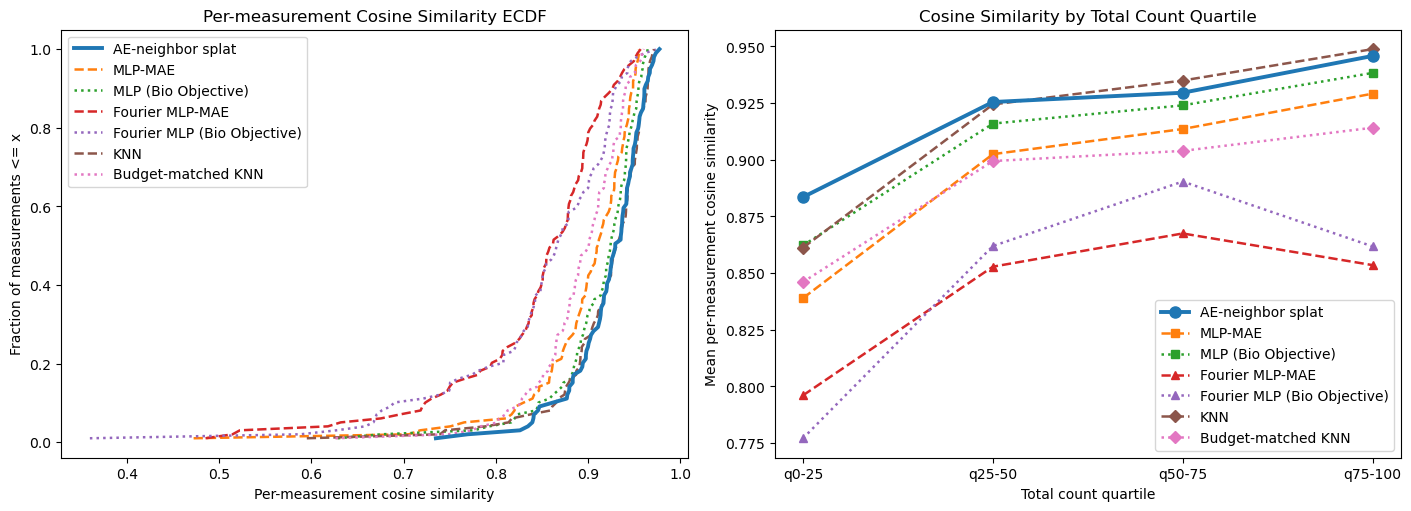

In [23]:
comparison_gene_name = comparison_gene_of_interest if comparison_gene_of_interest in gene_to_id else ('Eomes' if 'Eomes' in gene_to_id else gene_list[0])
comparison_gene_idx = gene_to_id[comparison_gene_name]

comparison_mask_np = tissue_mask_tensor.squeeze().detach().cpu().numpy() > 0.05
comparison_distance_map = distance_transform_edt(comparison_mask_np).astype(np.float32) / data_cfg.mask_grid_size

def predict_counts_cell_model(model, features, spans, batch_size=512):
    was_training = model.training
    model.eval()
    outs = []
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            outs.append(torch.exp(predict_cell_log_rates(model, features[start:start + batch_size], spans[start:start + batch_size], batch_size=batch_size)))
    if was_training:
        model.train()
    return torch.cat(outs, dim=0)


def predict_counts_direct_model(model, features, batch_size=256):
    was_training = model.training
    model.eval()
    outs = []
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            outs.append(torch.exp(model(features[start:start + batch_size])))
    if was_training:
        model.train()
    return torch.cat(outs, dim=0)


def per_cell_cosine_similarity(pred_counts, true_counts):
    pred_norm = pred_counts / pred_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
    true_norm = true_counts / true_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
    return (pred_norm * true_norm).sum(dim=1).detach().cpu().numpy()


def summarize_count_conditioned_error(total_counts, mae_values):
    q_edges = np.quantile(total_counts, [0.0, 0.25, 0.5, 0.75, 1.0])
    q_edges[0] = np.floor(q_edges[0])
    q_edges[-1] = np.ceil(q_edges[-1])
    labels = ['q0-25', 'q25-50', 'q50-75', 'q75-100']
    out = {}
    for i, label in enumerate(labels):
        lo = q_edges[i]
        hi = q_edges[i + 1]
        if i == len(labels) - 1:
            mask = (total_counts >= lo) & (total_counts <= hi)
        else:
            mask = (total_counts >= lo) & (total_counts < hi)
        out[label] = {
            'count_range': [float(lo), float(hi)],
            'n': int(mask.sum()),
            'mean_mae': float(mae_values[mask].mean()) if mask.any() else float('nan'),
            'median_mae': float(np.median(mae_values[mask])) if mask.any() else float('nan'),
        }
    corr = np.corrcoef(total_counts, mae_values)[0, 1] if len(total_counts) > 1 else float('nan')
    out['corr_total_count_vs_mae'] = float(corr)
    return out


def summarize_error_distribution(values):
    return {
        'mean': float(np.mean(values)),
        'std': float(np.std(values)),
        'median': float(np.median(values)),
        'q90': float(np.quantile(values, 0.90)),
        'q95': float(np.quantile(values, 0.95)),
        'q99': float(np.quantile(values, 0.99)),
    }

def ecdf_xy(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.array([], dtype=np.float64), np.array([], dtype=np.float64)
    x = np.sort(values)
    y = np.arange(1, len(x) + 1, dtype=np.float64) / float(len(x))
    return x, y

line_style_map = {
    'AE-neighbor splat': {'marker': 'o', 'linestyle': '-', 'linewidth': 2.8, 'markersize': 8, 'zorder': 5},
    'MLP-MAE': {'marker': 's', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'MLP (Bio Objective)': {'marker': 's', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
    'Fourier MLP-MAE': {'marker': '^', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'Fourier MLP (Bio Objective)': {'marker': '^', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
    'KNN': {'marker': 'D', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'Budget-matched KNN': {'marker': 'D', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
}

cell_test_features = cell_features[cell_test_idx]
cell_test_spans = cell_spans[cell_test_idx]
cell_test_targets_local = cell_targets[cell_test_idx]
cell_test_points = cell_test_features.detach().cpu().numpy()
cell_edge_distance = sample_numpy_grid(cell_test_points, comparison_distance_map)
cell_total_counts_test = cell_test_targets_local.sum(dim=1).detach().cpu().numpy()
cell_true_gene = cell_test_targets_local[:, comparison_gene_idx].detach().cpu().numpy()

comparison_models = [
    ('AE-neighbor splat', ae_coarse_result['model'], 'cell_model'),
    ('MLP-MAE', cell_mlp_mae.to(device), 'direct_model'),
    ('MLP (Bio Objective)', cell_mlp.to(device), 'direct_model'),
    ('Fourier MLP-MAE', cell_fourier_mlp_mae.to(device), 'direct_model'),
    ('Fourier MLP (Bio Objective)', cell_fourier_mlp.to(device), 'direct_model'),
    ('KNN', cell_knn.to(device), 'direct_model'),
    ('Budget-matched KNN', cell_budget_knn.to(device), 'direct_model'),
]

print(f'Comparison Gene: {comparison_gene_name}')
print('Edge vs Interior Error')
plot_specs = []
for label, model, model_kind in comparison_models:
    if model_kind == 'cell_model':
        pred_counts = predict_counts_cell_model(model, cell_test_features, cell_test_spans)
    else:
        pred_counts = predict_counts_direct_model(model, cell_test_features, batch_size=256)
    mae_values = (pred_counts - cell_test_targets_local).abs().mean(dim=1).detach().cpu().numpy()
    gene_values = pred_counts[:, comparison_gene_idx].detach().cpu().numpy()
    signed_values = gene_values - cell_true_gene
    cosine_values = per_cell_cosine_similarity(pred_counts, cell_test_targets_local)
    print(label, format_for_display(summarize_error_slices(mae_values, cell_edge_distance)))
    print(label, format_for_display(summarize_activity_slices(signed_values, cell_true_gene)))
    plot_specs.append((label, mae_values, signed_values, cosine_values))

print('MAE By Total Cell Counts')
for label, mae_values, _, _ in plot_specs:
    print(label, format_for_display(summarize_count_conditioned_error(cell_total_counts_test, mae_values)))

print('Per-cell MAE Distribution')
for label, mae_values, _, _ in plot_specs:
    print(label, format_for_display(summarize_error_distribution(mae_values)))

print('Per-cell Cosine Similarity')
for label, _, _, cosine_values in plot_specs:
    print(label, format_for_display(summarize_error_distribution(cosine_values)))

all_mae_values = np.concatenate([mae_values for _, mae_values, _, _ in plot_specs])
all_signed_values = np.concatenate([signed_values for _, _, signed_values, _ in plot_specs])
mae_vmax = np.quantile(all_mae_values, 0.98) if len(all_mae_values) else 1.0
signed_vmax = np.quantile(np.abs(all_signed_values), 0.98) if np.any(np.abs(all_signed_values) > 0) else 1.0

fig, axes = plt.subplots(len(plot_specs), 2, figsize=(12, 5 * len(plot_specs)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, (label, mae_values, signed_values, _) in enumerate(plot_specs):
    for col, (values, suffix, cmap) in enumerate([
        (mae_values, 'MAE', 'magma'),
        (signed_values, f'Signed Error ({comparison_gene_name})', 'coolwarm'),
    ]):
        ax = axes[row, col]
        ax.imshow(comparison_mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25, vmin=0.0, vmax=1.0)
        if cmap == 'coolwarm':
            sc = ax.scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=values, s=18, cmap=cmap, alpha=0.9, vmin=-signed_vmax, vmax=signed_vmax)
        else:
            sc = ax.scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=values, s=18, cmap=cmap, alpha=0.9, vmin=0.0, vmax=mae_vmax)
        ax.set_title(f'{label} {suffix}')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('x_norm')
        ax.set_ylabel('y_norm')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix='comparison_panels')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, mae_values, _, _ in plot_specs:
    x, y = ecdf_xy(mae_values)
    ecdf_style = dict(line_style_map.get(label, {'linestyle': '-', 'linewidth': 1.8}))
    ecdf_style.pop('marker', None)
    ecdf_style.pop('markersize', None)
    axes[0].plot(x, y, label=label, **ecdf_style)
axes[0].set_title('Per-measurement MAE ECDF')
axes[0].set_xlabel('Per-measurement MAE')
axes[0].set_ylabel('Fraction of measurements <= x')
axes[0].legend()

refined_label = 'AE-neighbor splat'
refined_mae = next(mae_values for label, mae_values, _, _ in plot_specs if label == refined_label)
worst_thresh = np.quantile(refined_mae, 0.95) if len(refined_mae) else 0.0
worst_mask = refined_mae >= worst_thresh
axes[1].imshow(comparison_mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25, vmin=0.0, vmax=1.0)
sc = axes[1].scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=refined_mae, s=np.where(worst_mask, 24, 8), cmap='magma', alpha=np.where(worst_mask, 0.95, 0.18), vmin=0.0, vmax=mae_vmax)
axes[1].set_title(f'Worst 5% Measurements By MAE ({refined_label})')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_aspect('equal')
axes[1].set_xlabel('x_norm')
axes[1].set_ylabel('y_norm')
fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix='mae_ecdf')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, mae_values, _, _ in plot_specs:
    axes[0].scatter(cell_total_counts_test, mae_values, s=6, alpha=0.15, label=label)
axes[0].set_title('Per-measurement MAE vs Total Counts')
axes[0].set_xlabel('Total measurement counts')
axes[0].set_ylabel('Per-measurement MAE')
axes[0].legend(markerscale=2)

count_edges = np.quantile(cell_total_counts_test, [0.0, 0.25, 0.5, 0.75, 1.0])
count_labels = ['q0-25', 'q25-50', 'q50-75', 'q75-100']
for label, mae_values, _, _ in plot_specs:
    means = []
    for i in range(4):
        lo = count_edges[i]
        hi = count_edges[i + 1]
        if i == 3:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test <= hi)
        else:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test < hi)
        means.append(mae_values[mask].mean() if mask.any() else np.nan)
    axes[1].plot(count_labels, means, label=label, **line_style_map.get(label, {'marker': 'o', 'linestyle': '-', 'linewidth': 1.8, 'markersize': 6}))
axes[1].set_title('MAE by Total Count Quartile')
axes[1].set_xlabel('Total count quartile')
axes[1].set_ylabel('Mean per-measurement MAE')
axes[1].legend()
export_figure_axes(fig, fallback_prefix='mae_counts')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, _, _, cosine_values in plot_specs:
    x, y = ecdf_xy(cosine_values)
    ecdf_style = dict(line_style_map.get(label, {'linestyle': '-', 'linewidth': 1.8}))
    ecdf_style.pop('marker', None)
    ecdf_style.pop('markersize', None)
    axes[0].plot(x, y, label=label, **ecdf_style)
axes[0].set_title('Per-measurement Cosine Similarity ECDF')
axes[0].set_xlabel('Per-measurement cosine similarity')
axes[0].set_ylabel('Fraction of measurements <= x')
axes[0].legend()

for label, _, _, cosine_values in plot_specs:
    means = []
    for i in range(4):
        lo = count_edges[i]
        hi = count_edges[i + 1]
        if i == 3:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test <= hi)
        else:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test < hi)
        means.append(cosine_values[mask].mean() if mask.any() else np.nan)
    axes[1].plot(count_labels, means, label=label, **line_style_map.get(label, {'marker': 'o', 'linestyle': '-', 'linewidth': 1.8, 'markersize': 6}))
axes[1].set_title('Cosine Similarity by Total Count Quartile')
axes[1].set_xlabel('Total count quartile')
axes[1].set_ylabel('Mean per-measurement cosine similarity')
axes[1].legend()
export_figure_axes(fig, fallback_prefix='cosine_counts')
plt.show()
